# **Bike-Sharing Rental**

## **Exploratory Data Analysis**

In [2]:
import pandas as pd
import numpy as np

# Load the dataset
df = pd.read_csv("Dataset.csv")

# Display dataset structure
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types and Non-Null Counts:")
df.info()

print("\nFirst 5 Records:")
display(df.head())

print("\nStatistical Summary:")
display(df.describe(include="all").T)

Dataset Shape: (17379, 17)

Column Names:
['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']

Data Types and Non-Null Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   instant     17379 non-null  int64 
 1   dteday      17379 non-null  object
 2   season      17379 non-null  object
 3   yr          17379 non-null  object
 4   mnth        17379 non-null  object
 5   hr          17379 non-null  int64 
 6   holiday     17379 non-null  object
 7   weekday     17379 non-null  int64 
 8   workingday  17379 non-null  object
 9   weathersit  17379 non-null  object
 10  temp        17379 non-null  object
 11  atemp       17379 non-null  object
 12  hum         17379 non-null  object
 13  windspeed   17379 non-null  object
 14  c

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,01-01-2011,springer,2011,1,0,No,6,No work,Clear,0.24,0.2879,0.81,0,3,13,16
1,2,01-01-2011,springer,2011,1,1,No,6,No work,Clear,0.22,0.2727,0.8,0,8,32,40
2,3,01-01-2011,springer,2011,1,2,No,6,No work,Clear,0.22,0.2727,?,0,5,27,32
3,4,01-01-2011,springer,2011,1,3,No,6,No work,Clear,0.24,0.2879,0.75,0,3,10,13
4,5,01-01-2011,springer,2011,1,4,No,6,No work,Clear,0.24,0.2879,0.75,0,0,1,1



Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
instant,17379.0,NaN,NaN,NaN,8690.0,5017.0295,1.0,4345.5,8690.0,13034.5,17379.0
dteday,17379,731,01-01-2011,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
season,17379,5,fall,4496,NaN,NaN,NaN,NaN,NaN,NaN,NaN
yr,17379,3,2012,8734,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mnth,17379,13,5,1488,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hr,17379.0,NaN,NaN,NaN,11.546752,6.914405,0.0,6.0,12.0,18.0,23.0
holiday,17379,3,No,16878,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weekday,17379.0,NaN,NaN,NaN,3.003683,2.005771,0.0,1.0,3.0,5.0,6.0
workingday,17379,3,Working Day,11862,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weathersit,17379,5,Clear,11412,NaN,NaN,NaN,NaN,NaN,NaN,NaN


"The dataset contains 17,379 observations and 17 variables representing hourly bike-sharing activity."

"The variables include temporal, calendar, weather, and user-related information, with cnt representing the total bike rental demand."

"During the initial inspection, some numerical variables were identified as object data types because the dataset contains ? as a representation of missing values. These will be addressed during data cleaning."

"This initial assessment helps us understand the dataset structure before performing cleaning and further exploratory analysis."

## **Clean the data: Check for invalid records, missing values, duplicated records, and outliers.**

In [3]:
# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Check missing values represented by '?'
missing_symbols = (df == "?").sum()

print("\nMissing values represented by '?':")
print(missing_symbols[missing_symbols > 0])

# Convert '?' to NaN
df = df.replace("?", np.nan)

# Convert numerical columns to numeric data types
numeric_columns = [
    "instant", "yr", "mnth", "hr", "weekday",
    "temp", "atemp", "hum", "windspeed",
    "casual", "registered", "cnt"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Convert date column
df["dteday"] = pd.to_datetime(df["dteday"], errors="coerce")

# Standardize categorical values
df["season"] = df["season"].replace("springer", "spring")

# Check missing values
print("Missing Values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Check invalid numerical ranges
range_checks = {
    "hr": (0, 23),
    "weekday": (0, 6),
    "temp": (0, 1),
    "atemp": (0, 1),
    "hum": (0, 1),
    "windspeed": (0, 1),
    "cnt": (0, np.inf)
}

print("\nInvalid Records:")

for column, (lower, upper) in range_checks.items():
    invalid = ((df[column] < lower) | (df[column] > upper)).sum()
    print(f"{column}: {invalid}")

# Detect outliers using IQR
outlier_columns = [
    "temp", "atemp", "hum",
    "windspeed", "casual",
    "registered", "cnt"
]

print("\nOutlier Counts:")

for column in outlier_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ).sum()

    print(f"{column}: {outliers}")

Dataset Shape: (17379, 17)

Missing values represented by '?':
season         6
yr             1
mnth           1
holiday        1
workingday     5
weathersit     4
temp          11
atemp          6
hum            6
windspeed      5
casual         1
registered     1
dtype: int64
Missing Values:
dteday        10501
season            6
yr                1
mnth              1
holiday           1
workingday        5
weathersit        4
temp             11
atemp             6
hum               6
windspeed         5
casual            1
registered        1
dtype: int64

Duplicate Records: 0

Invalid Records:
hr: 0
weekday: 0
temp: 0
atemp: 0
hum: 0
windspeed: 0
cnt: 0

Outlier Counts:
temp: 0
atemp: 0
hum: 22
windspeed: 341
casual: 1192
registered: 680
cnt: 505


"I first identified non-standard missing values represented by ? and converted them to NaN so they could be handled systematically."

"I checked for duplicate and invalid records by validating both duplicate rows and the expected ranges of numerical variables."

"I used the IQR method to identify statistical outliers. I did not automatically remove them because high bike-rental values can represent genuine peak-demand periods rather than erroneous data."

"The objective of data cleaning is not to make the data look perfect; it is to ensure that the data is valid while preserving genuine business information."

## **Handle missing values**

In [4]:
# Check missing values before imputation
missing_before = df.isnull().sum()

print("Missing Values Before Imputation:")
print(missing_before[missing_before > 0])

# Numerical columns that can be safely imputed
numeric_imputation_columns = [
    "yr", "mnth", "hr", "weekday",
    "temp", "atemp", "hum", "windspeed",
    "casual", "registered"
]

# Impute numerical missing values using median
for column in numeric_imputation_columns:
    if df[column].isnull().sum() > 0:
        df[column] = df[column].fillna(df[column].median())

# Impute missing date values using forward fill
if df["dteday"].isnull().sum() > 0:
    df["dteday"] = df["dteday"].ffill()

# Handle missing categorical values using mode
categorical_columns = ["season", "weathersit"]

for column in categorical_columns:
    if df[column].isnull().sum() > 0:
        df[column] = df[column].fillna(df[column].mode()[0])

# Do not impute the target variable.
# Remove records where target 'cnt' is missing.
df = df.dropna(subset=["cnt"])

# Verify missing values after imputation
missing_after = df.isnull().sum()

print("\nMissing Values After Imputation:")
print(missing_after[missing_after > 0])

print("\nTotal Missing Values After Imputation:", df.isnull().sum().sum())

print("\nFinal Dataset Shape:", df.shape)

Missing Values Before Imputation:
dteday        10501
season            6
yr                1
mnth              1
holiday           1
workingday        5
weathersit        4
temp             11
atemp             6
hum               6
windspeed         5
casual            1
registered        1
dtype: int64

Missing Values After Imputation:
holiday       1
workingday    5
dtype: int64

Total Missing Values After Imputation: 6

Final Dataset Shape: (17379, 17)


"Missing values were initially represented by ?, so they were converted to NaN."

"Numerical columns were converted to proper numeric data types before imputation."

"Median imputation was selected for numerical variables because bike-demand-related variables can be skewed and contain outliers."

"Categorical missing values, if any, were handled using the mode."

"Missing target values in cnt were not imputed, because fabricating the target could introduce bias into the supervised learning model."

"After imputation, the dataset was rechecked to ensure there were no unintended missing values."

## **Detect outliers**

Outlier Analysis using IQR Method:



,Column,Q1,Q3,Lower Bound,Upper Bound,Outlier Count,Outlier %
0,temp,0.3400,0.6600,-0.14000,1.14000,0,0.00
1,atemp,0.3333,0.6212,-0.09855,1.05305,0,0.00
2,hum,0.4800,0.7800,0.03000,1.23000,22,0.13
3,windspeed,0.1045,0.2537,-0.11930,0.47750,341,1.96
4,casual,4.0000,48.0000,-62.00000,114.00000,1192,6.86
5,registered,34.0000,220.0000,-245.00000,499.00000,680,3.91
6,cnt,40.0000,281.0000,-321.50000,642.50000,505,2.91


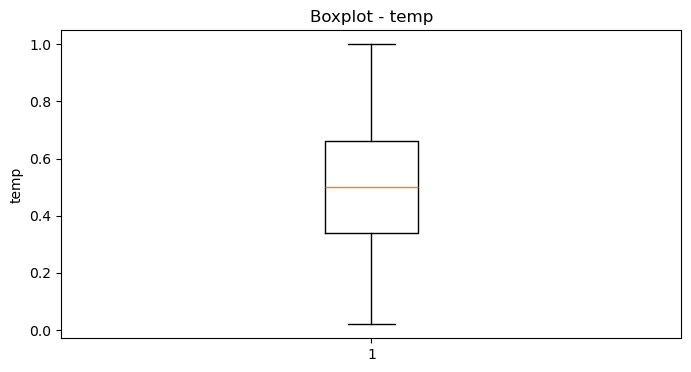

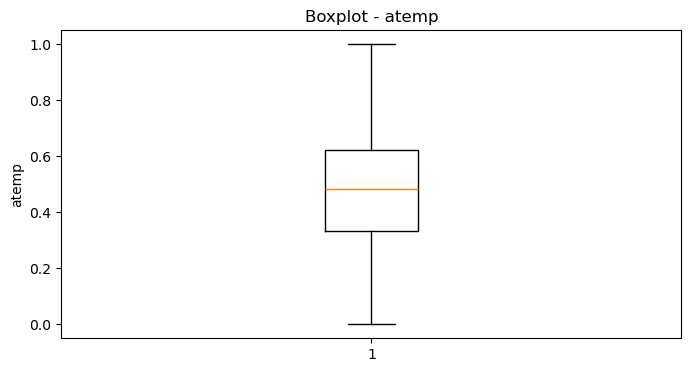

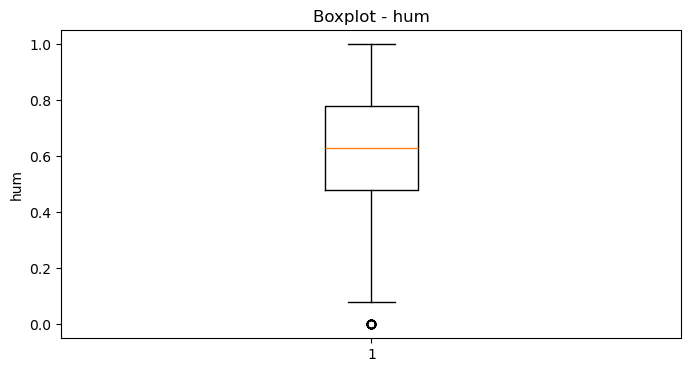

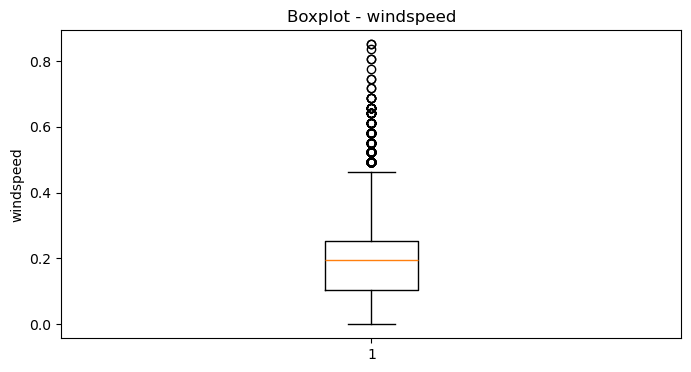

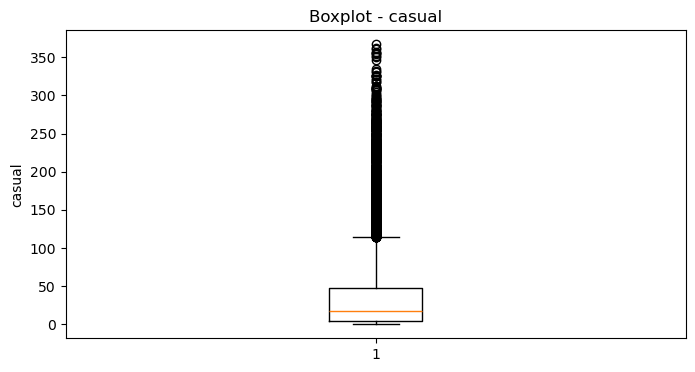

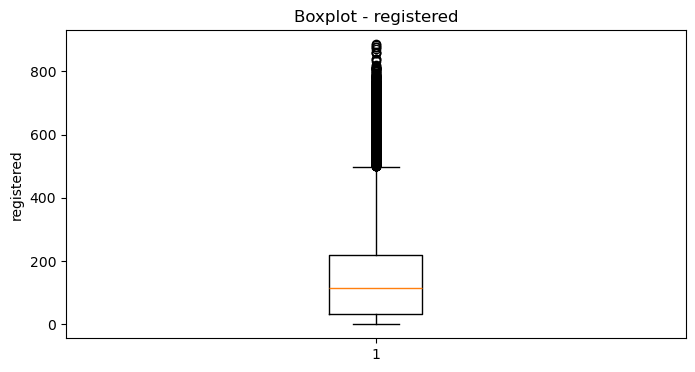

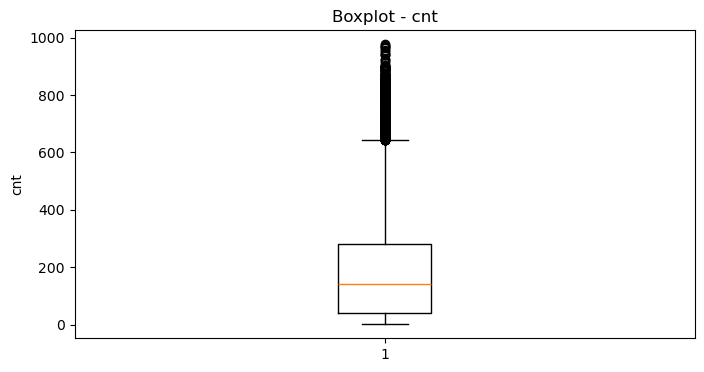

In [5]:
# Columns where outlier detection is meaningful
outlier_columns = [
    "temp",
    "atemp",
    "hum",
    "windspeed",
    "casual",
    "registered",
    "cnt"
]

print("Outlier Analysis using IQR Method:\n")

outlier_summary = []

for column in outlier_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_mask = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    )

    outlier_count = outlier_mask.sum()
    outlier_percentage = (outlier_count / len(df)) * 100

    outlier_summary.append({
        "Column": column,
        "Q1": Q1,
        "Q3": Q3,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_count,
        "Outlier %": round(outlier_percentage, 2)
    })

outlier_summary_df = pd.DataFrame(outlier_summary)

display(outlier_summary_df)

# Visual inspection using boxplots
import matplotlib.pyplot as plt

for column in outlier_columns:
    plt.figure(figsize=(8, 4))
    plt.boxplot(df[column].dropna())
    plt.title(f"Boxplot - {column}")
    plt.ylabel(column)
    plt.show()

- temp and atemp have no statistical outliers according to the IQR method.
hum has a very small number of outliers.

- windspeed has 341 outliers, indicating some unusually high/low observations according to the IQR boundaries.

- casual and registered have a relatively high number of statistical outliers because user counts are naturally skewed.

- cnt has 505 statistical outliers, representing unusually high-demand observations.

- These cnt outliers should not be removed automatically, because they may represent genuine peak rental demand.

- Therefore, based on the output, we retain the valid observations and do not remove outliers at this stage.

# **Data Visualization:**

### **Creating visualizations such as scatter plots, line plots, and bar plots to explore relationships between variables**

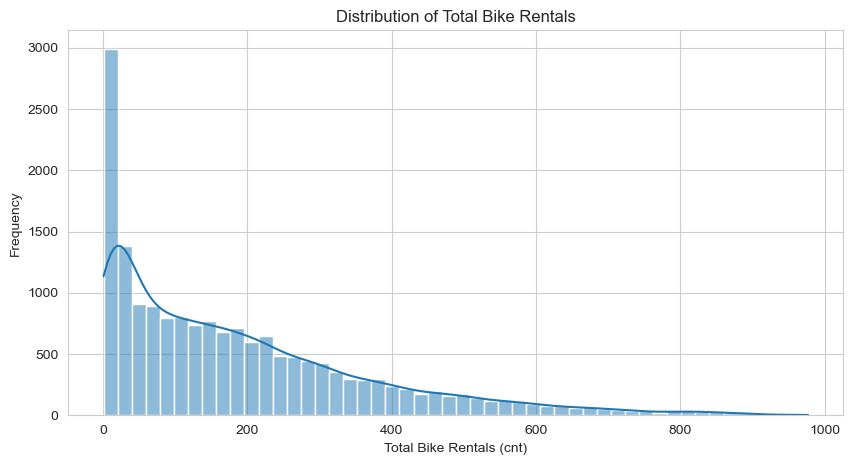

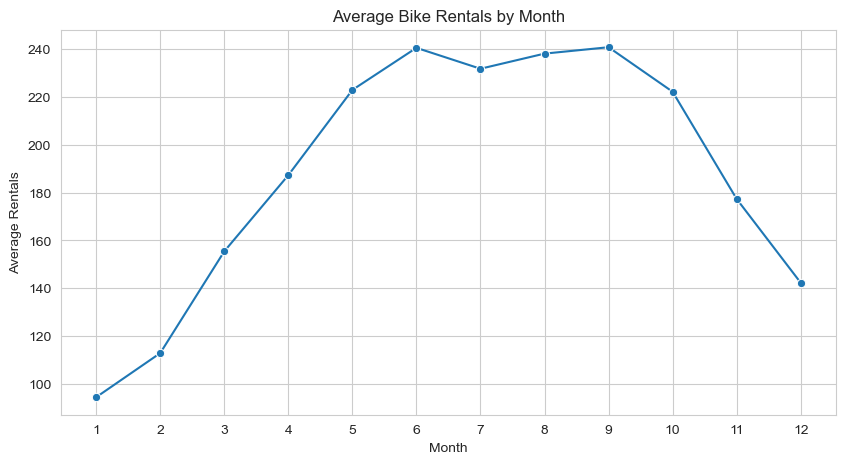

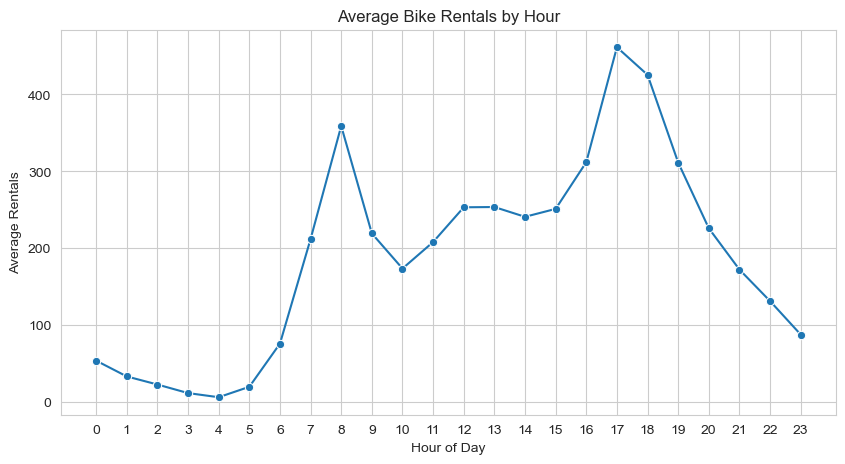

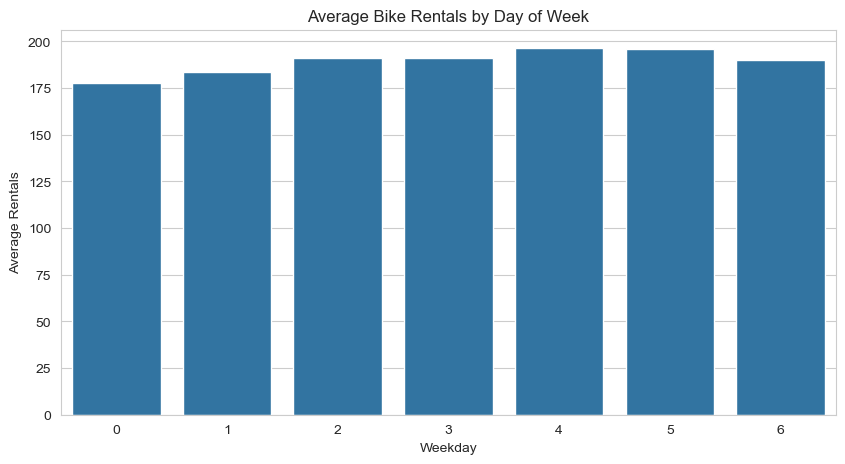

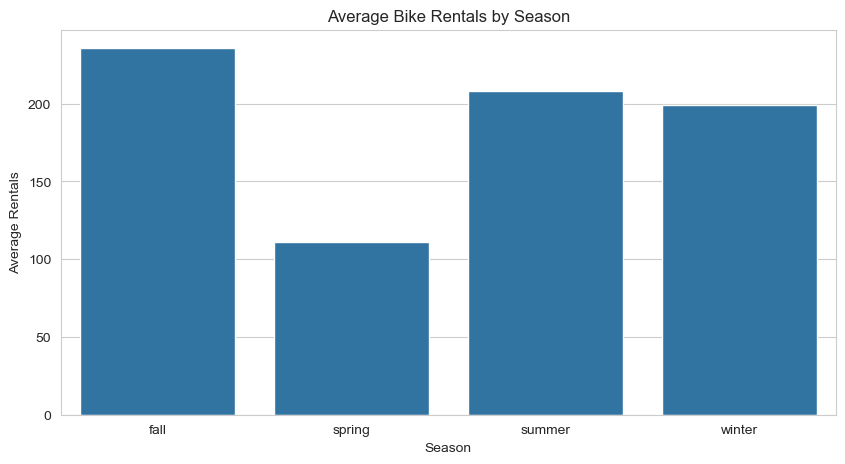

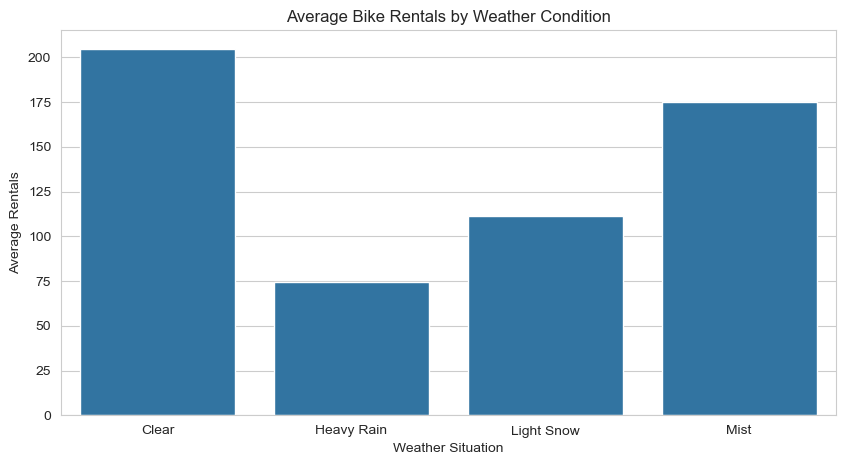

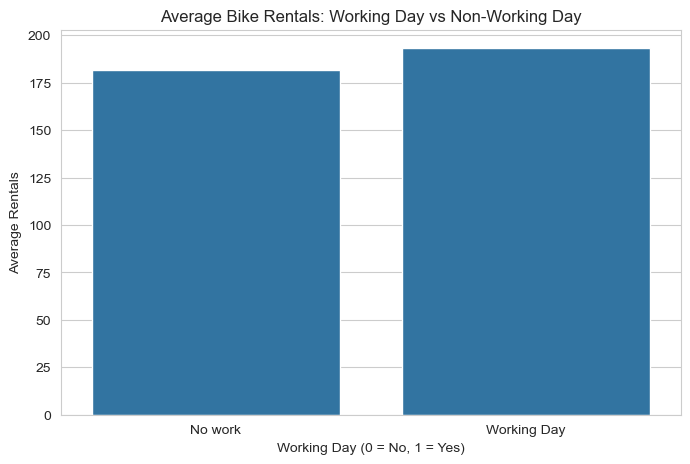

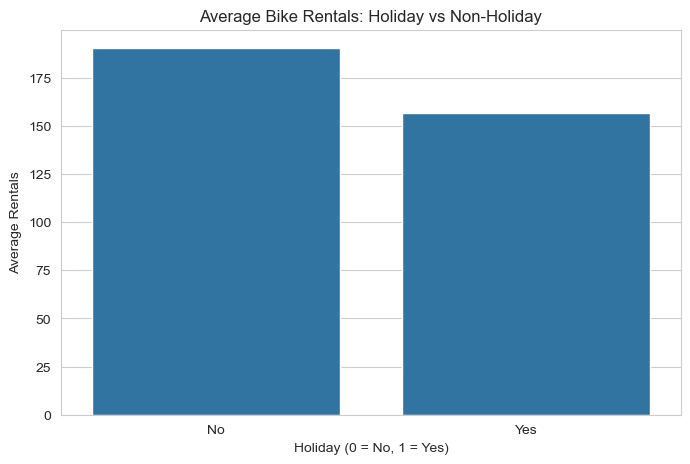

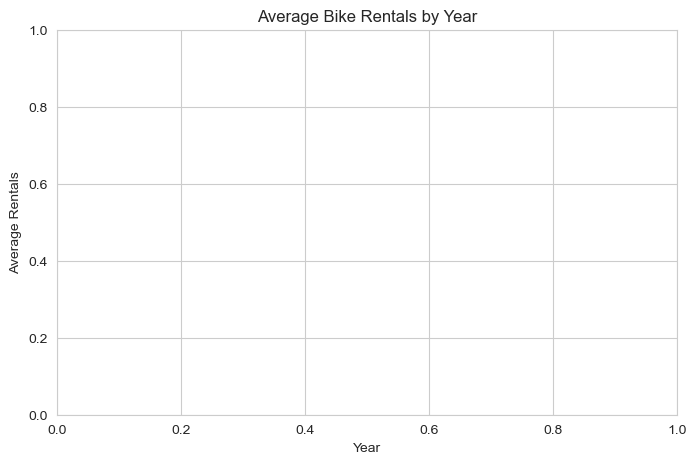

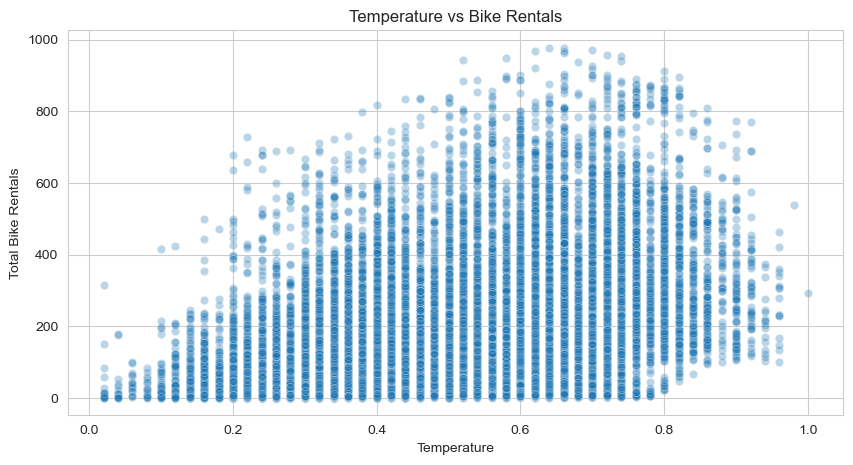

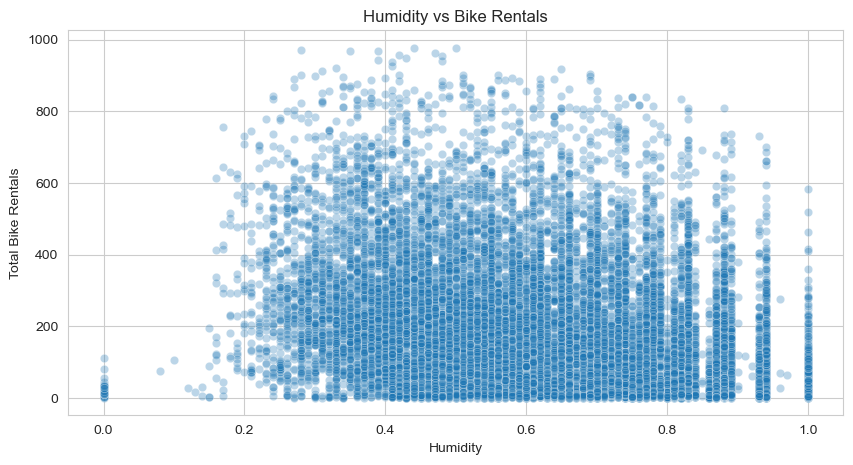

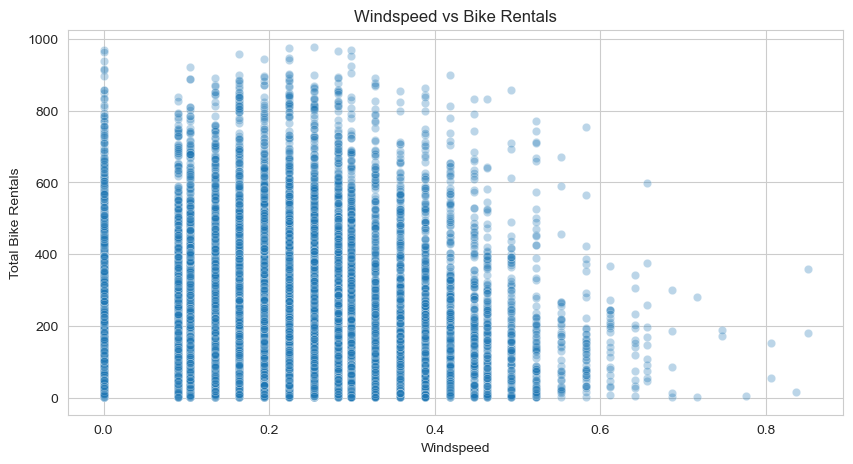

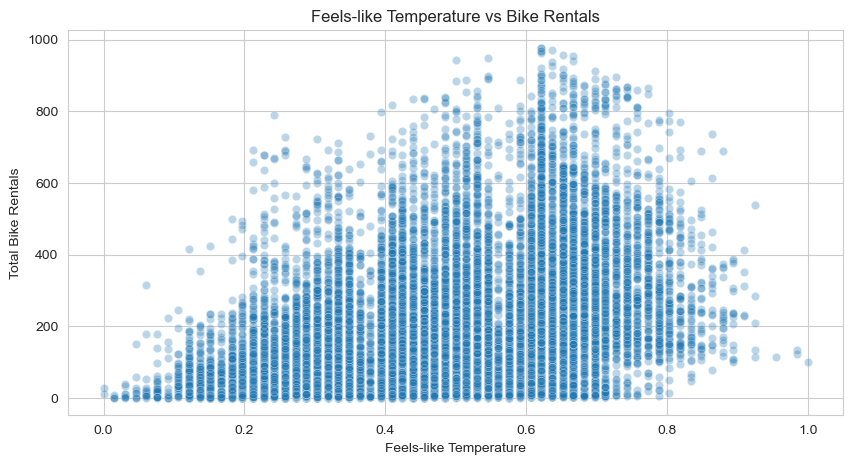

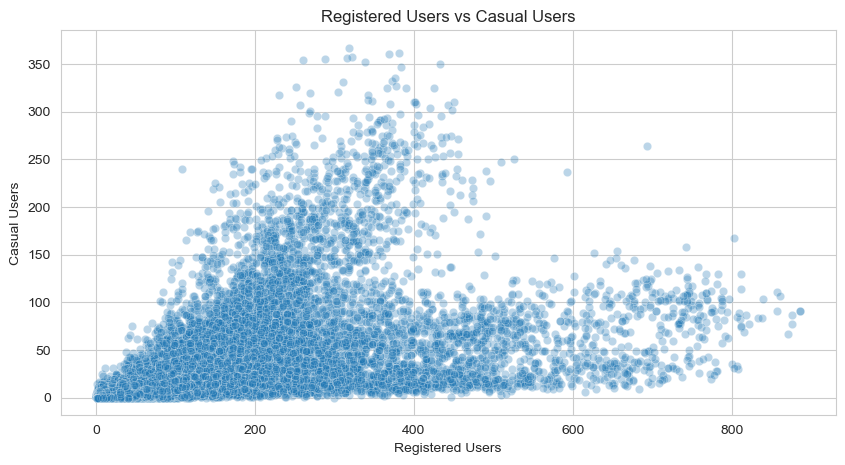

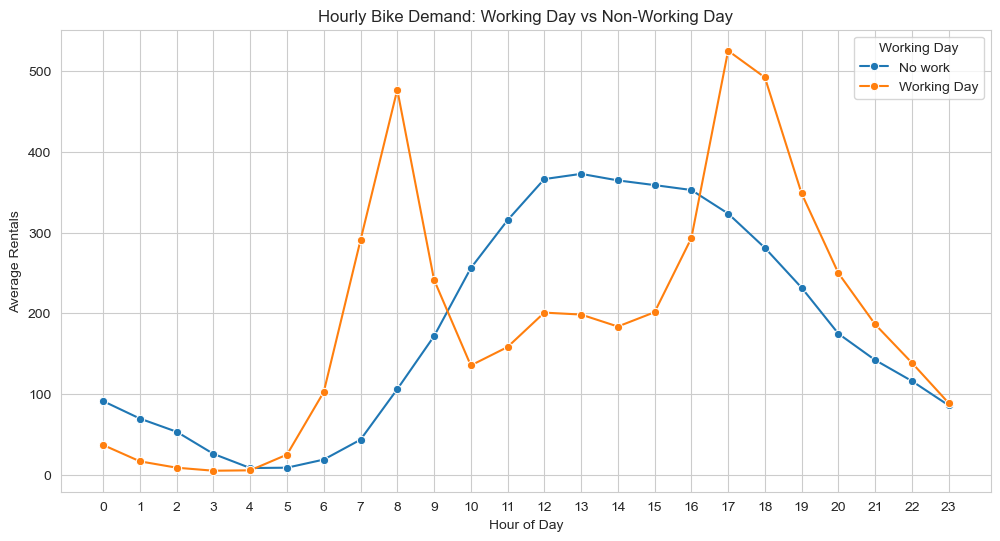

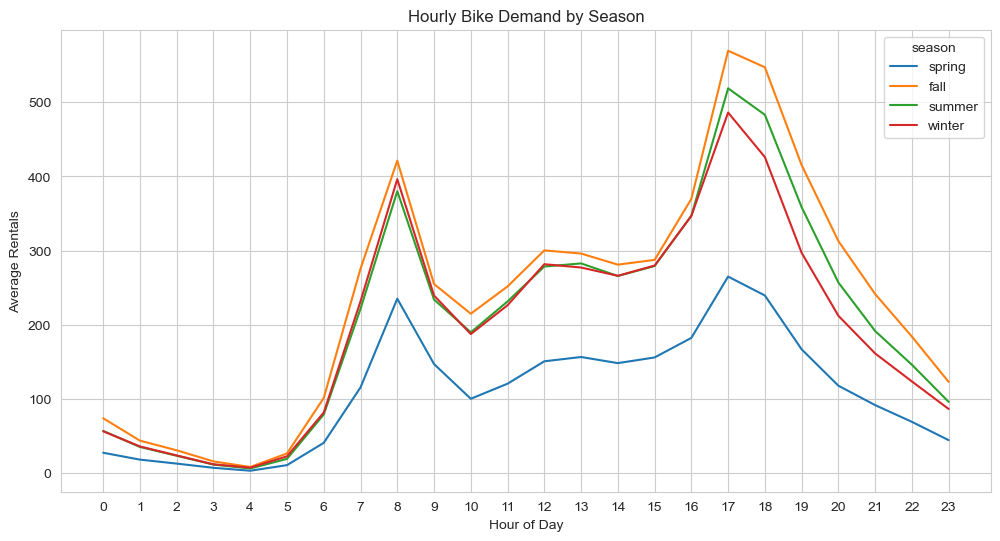

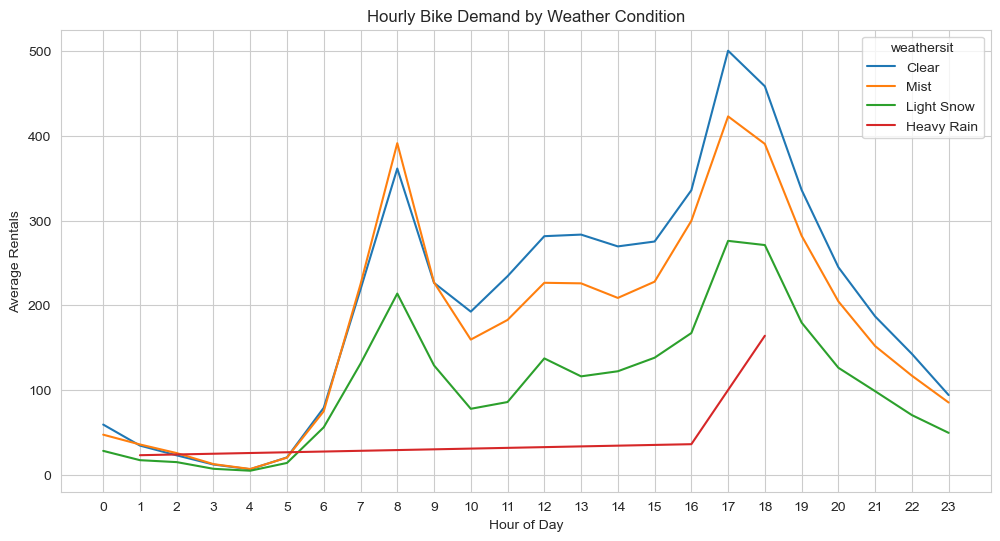

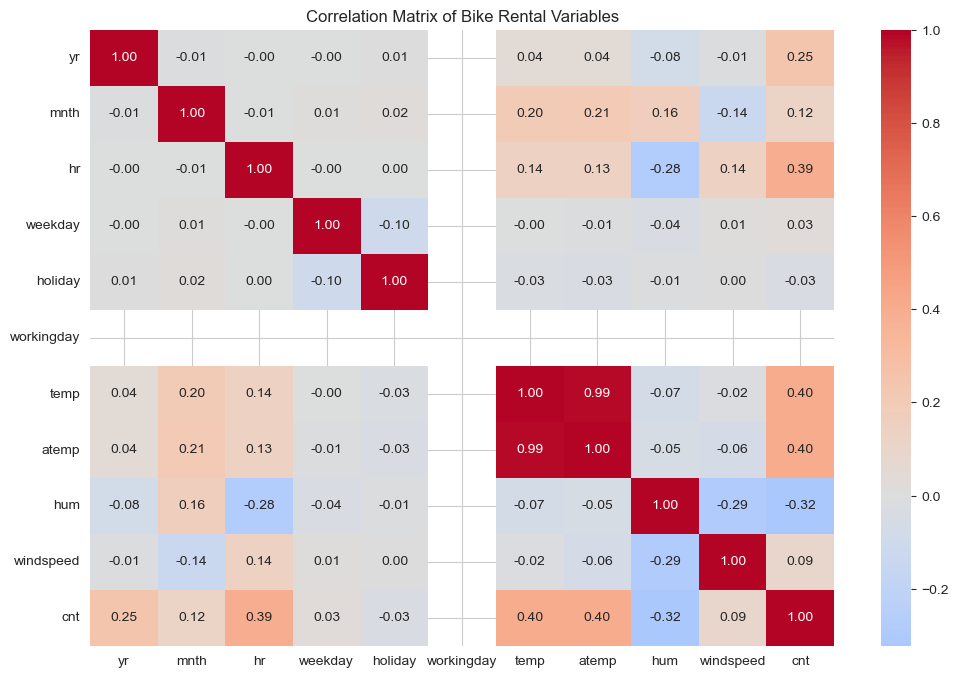

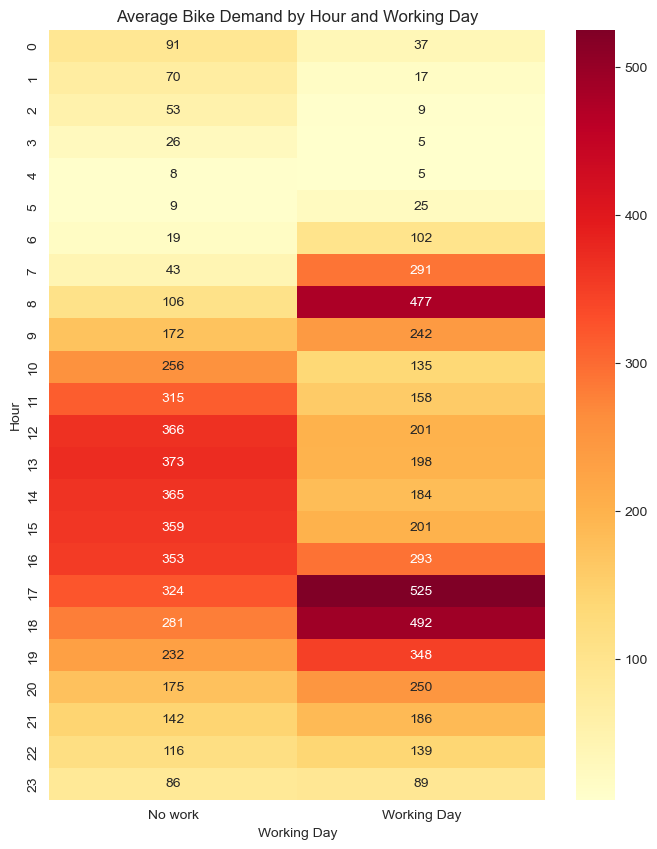

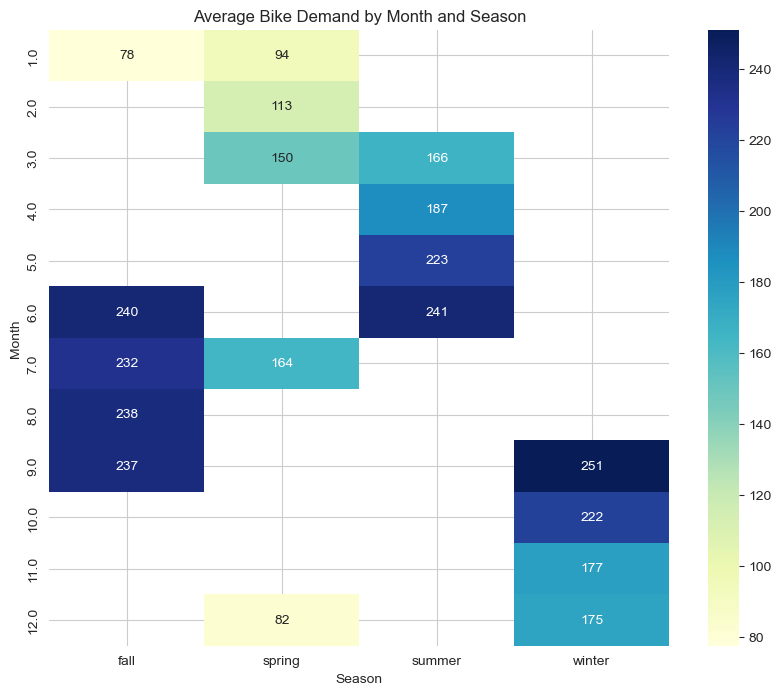

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_style("whitegrid")

# Create derived date fields only for visualization
df["year_label"] = df["yr"].map({0: "2011", 1: "2012"})

# 1. Target Distribution
plt.figure(figsize=(10, 5))
sns.histplot(df["cnt"], bins=50, kde=True)
plt.title("Distribution of Total Bike Rentals")
plt.xlabel("Total Bike Rentals (cnt)")
plt.ylabel("Frequency")
plt.show()


# 2. Monthly Demand Trend
monthly_demand = df.groupby("mnth")["cnt"].mean().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(data=monthly_demand, x="mnth", y="cnt", marker="o")
plt.title("Average Bike Rentals by Month")
plt.xlabel("Month")
plt.ylabel("Average Rentals")
plt.xticks(range(1, 13))
plt.show()


# 3. Hourly Demand Trend
hourly_demand = df.groupby("hr")["cnt"].mean().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(data=hourly_demand, x="hr", y="cnt", marker="o")
plt.title("Average Bike Rentals by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Rentals")
plt.xticks(range(0, 24))
plt.show()


# 4. Weekly Demand Pattern
weekday_demand = df.groupby("weekday")["cnt"].mean().reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=weekday_demand, x="weekday", y="cnt")
plt.title("Average Bike Rentals by Day of Week")
plt.xlabel("Weekday")
plt.ylabel("Average Rentals")
plt.show()


# 5. Seasonal Demand
season_demand = df.groupby("season")["cnt"].mean().reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=season_demand, x="season", y="cnt")
plt.title("Average Bike Rentals by Season")
plt.xlabel("Season")
plt.ylabel("Average Rentals")
plt.show()


# 6. Weather Impact
weather_demand = df.groupby("weathersit")["cnt"].mean().reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=weather_demand, x="weathersit", y="cnt")
plt.title("Average Bike Rentals by Weather Condition")
plt.xlabel("Weather Situation")
plt.ylabel("Average Rentals")
plt.show()


# 7. Working Day vs Non-Working Day
workingday_demand = df.groupby("workingday")["cnt"].mean().reset_index()

plt.figure(figsize=(8, 5))
sns.barplot(data=workingday_demand, x="workingday", y="cnt")
plt.title("Average Bike Rentals: Working Day vs Non-Working Day")
plt.xlabel("Working Day (0 = No, 1 = Yes)")
plt.ylabel("Average Rentals")
plt.show()


# 8. Holiday vs Non-Holiday
holiday_demand = df.groupby("holiday")["cnt"].mean().reset_index()

plt.figure(figsize=(8, 5))
sns.barplot(data=holiday_demand, x="holiday", y="cnt")
plt.title("Average Bike Rentals: Holiday vs Non-Holiday")
plt.xlabel("Holiday (0 = No, 1 = Yes)")
plt.ylabel("Average Rentals")
plt.show()


# 9. Yearly Demand Comparison
yearly_demand = df.groupby("year_label")["cnt"].mean().reset_index()

plt.figure(figsize=(8, 5))
sns.barplot(data=yearly_demand, x="year_label", y="cnt")
plt.title("Average Bike Rentals by Year")
plt.xlabel("Year")
plt.ylabel("Average Rentals")
plt.show()


# 10. Temperature vs Demand
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df,
    x="temp",
    y="cnt",
    alpha=0.3
)
plt.title("Temperature vs Bike Rentals")
plt.xlabel("Temperature")
plt.ylabel("Total Bike Rentals")
plt.show()


# 11. Humidity vs Demand
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df,
    x="hum",
    y="cnt",
    alpha=0.3
)
plt.title("Humidity vs Bike Rentals")
plt.xlabel("Humidity")
plt.ylabel("Total Bike Rentals")
plt.show()


# 12. Windspeed vs Demand
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df,
    x="windspeed",
    y="cnt",
    alpha=0.3
)
plt.title("Windspeed vs Bike Rentals")
plt.xlabel("Windspeed")
plt.ylabel("Total Bike Rentals")
plt.show()


# 13. Feels-like Temperature vs Demand
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df,
    x="atemp",
    y="cnt",
    alpha=0.3
)
plt.title("Feels-like Temperature vs Bike Rentals")
plt.xlabel("Feels-like Temperature")
plt.ylabel("Total Bike Rentals")
plt.show()


# 14. Registered vs Casual Users
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df,
    x="registered",
    y="casual",
    alpha=0.3
)
plt.title("Registered Users vs Casual Users")
plt.xlabel("Registered Users")
plt.ylabel("Casual Users")
plt.show()


# 15. Hour vs Demand by Working Day
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=df,
    x="hr",
    y="cnt",
    hue="workingday",
    estimator="mean",
    errorbar=None,
    marker="o"
)
plt.title("Hourly Bike Demand: Working Day vs Non-Working Day")
plt.xlabel("Hour of Day")
plt.ylabel("Average Rentals")
plt.xticks(range(0, 24))
plt.legend(title="Working Day")
plt.show()


# 16. Hour vs Demand by Season
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=df,
    x="hr",
    y="cnt",
    hue="season",
    estimator="mean",
    errorbar=None
)
plt.title("Hourly Bike Demand by Season")
plt.xlabel("Hour of Day")
plt.ylabel("Average Rentals")
plt.xticks(range(0, 24))
plt.show()


# 17. Hour vs Demand by Weather
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=df,
    x="hr",
    y="cnt",
    hue="weathersit",
    estimator="mean",
    errorbar=None
)
plt.title("Hourly Bike Demand by Weather Condition")
plt.xlabel("Hour of Day")
plt.ylabel("Average Rentals")
plt.xticks(range(0, 24))
plt.show()


# 18. Correlation Heatmap
# Convert Yes/No categorical values to numeric values only for correlation analysis

correlation_df = df.copy()

binary_mapping = {
    "No": 0,
    "Yes": 1
}

for column in ["holiday", "workingday"]:
    if correlation_df[column].dtype == "object":
        correlation_df[column] = correlation_df[column].map(binary_mapping)

correlation_columns = [
    "yr", "mnth", "hr", "weekday",
    "holiday", "workingday",
    "temp", "atemp", "hum",
    "windspeed", "cnt"
]

# Ensure all selected columns are numeric
correlation_df[correlation_columns] = correlation_df[correlation_columns].apply(
    pd.to_numeric, errors="coerce"
)

correlation_matrix = correlation_df[correlation_columns].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Matrix of Bike Rental Variables")
plt.show()


# 19. Demand by Hour and Working Day - Heatmap
hour_workingday = df.pivot_table(
    values="cnt",
    index="hr",
    columns="workingday",
    aggfunc="mean"
)

plt.figure(figsize=(8, 10))
sns.heatmap(
    hour_workingday,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd"
)
plt.title("Average Bike Demand by Hour and Working Day")
plt.xlabel("Working Day")
plt.ylabel("Hour")
plt.show()


# 20. Demand by Month and Season - Heatmap
month_season = df.pivot_table(
    values="cnt",
    index="mnth",
    columns="season",
    aggfunc="mean"
)

plt.figure(figsize=(10, 8))
sns.heatmap(
    month_season,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)
plt.title("Average Bike Demand by Month and Season")
plt.xlabel("Season")
plt.ylabel("Month")
plt.show()

- Target Distribution: cnt is right-skewed with a small number of high-demand observations.

- Monthly Demand: Demand increases toward the middle of the year, peaks around June–September, and decreases toward winter.

- Hourly Demand: Demand is lowest around 04:00 and peaks around 17:00, showing strong commuter patterns.

- Day of Week: Rental demand varies across weekdays, indicating different usage patterns throughout the week.

- Season: Fall has the highest average demand, while Spring has the lowest.

- Weather: Demand is highest in clear weather and decreases significantly under worse weather conditions.

- Working Day: Average demand is slightly higher on working days, but the hourly pattern differs considerably.

- Holiday: Rental demand differs between holidays and non-holidays, indicating an effect from holiday status.

- Year: 2012 has substantially higher demand than 2011, indicating strong year-over-year growth.

- Temperature vs Demand: Positive relationship — higher temperature generally corresponds to higher demand.

- Humidity vs Demand: Negative relationship — higher humidity generally corresponds to lower demand.

- Windspeed vs Demand: Very weak relationship with rental demand.

- Feels-like Temperature vs Demand: Positive relationship, similar to actual temperature.

- Registered vs Casual Users: User categories vary independently, but both contribute directly to cnt.

- Hour vs Working Day: Working days show pronounced morning and evening commuter peaks.

- Hour vs Season: Hourly demand patterns change across seasons, with higher demand during favorable seasons.

- Hour vs Weather: Poor weather generally suppresses demand, particularly during high-demand hours.

- Correlation Heatmap: temp, atemp, and hr have positive relationships with cnt; hum has a negative relationship.

- Hour × Working Day Heatmap: Highest demand occurs during specific commuting hours on working days.

- Month × Season Heatmap: Demand varies considerably across months and seasons, confirming strong seasonality.




## **Plotting time series data to analyze trends and seasonality.**

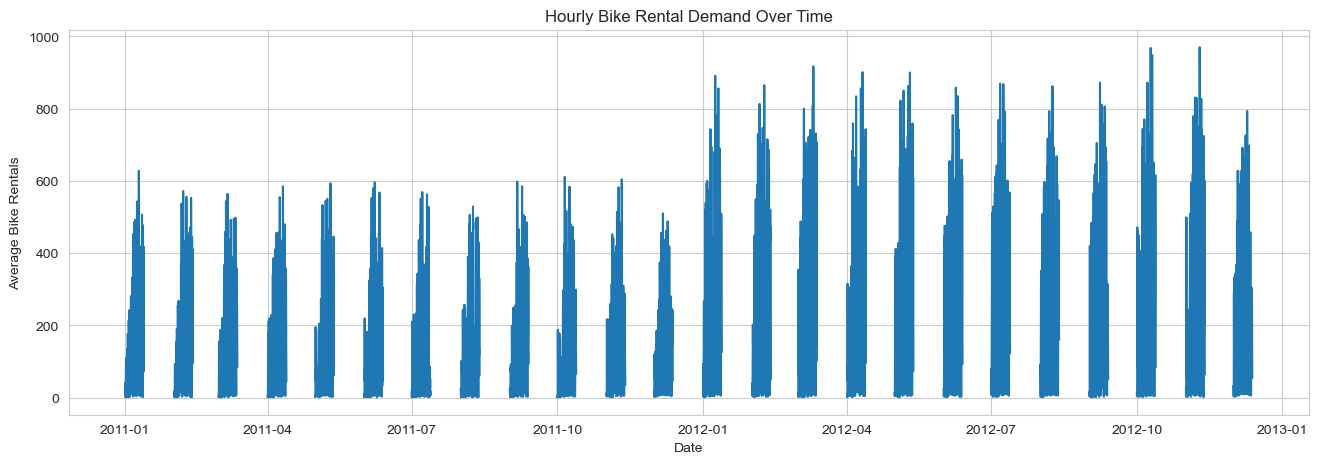

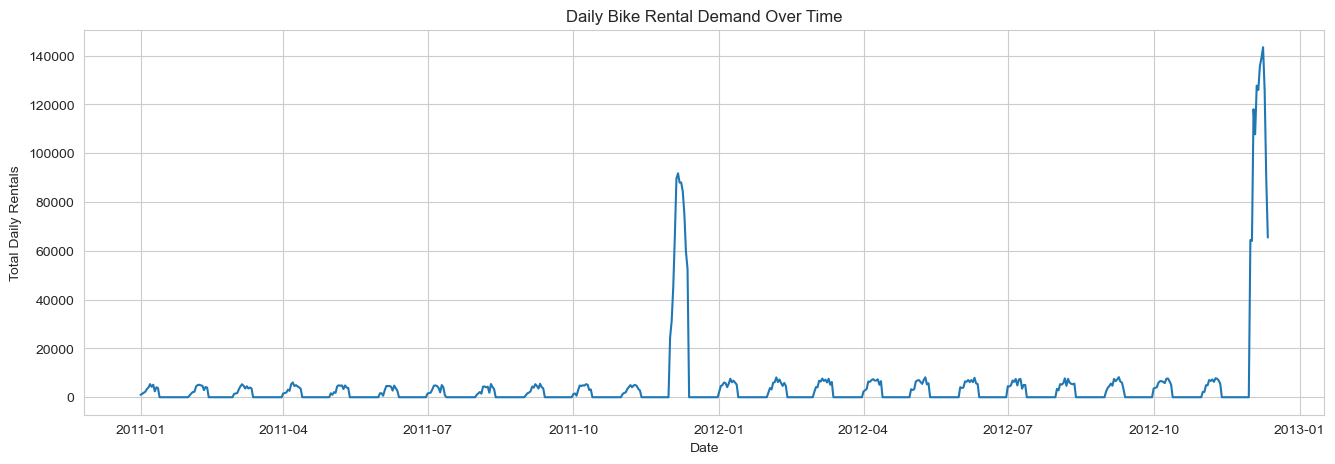

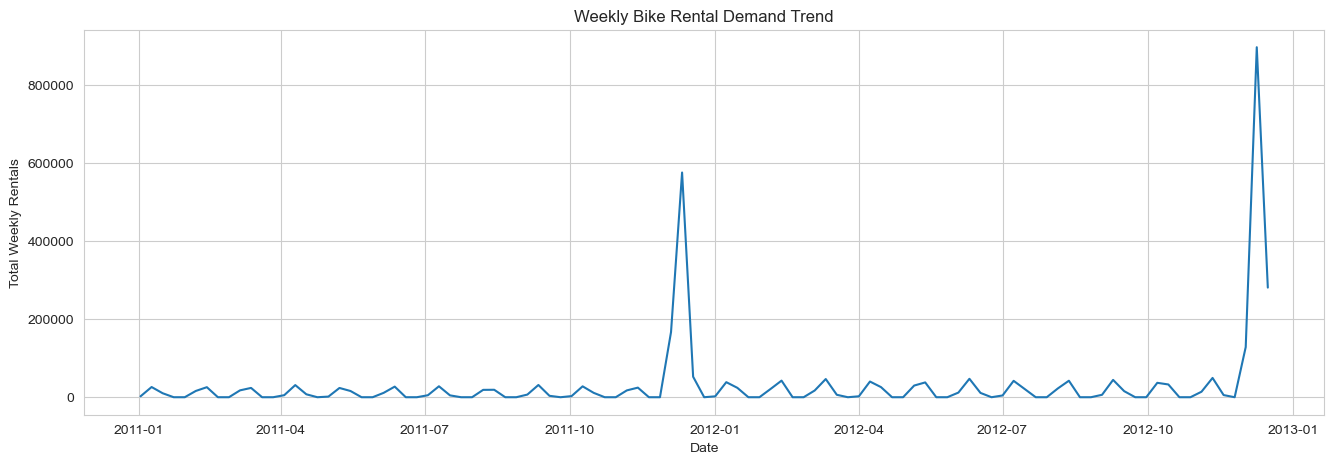

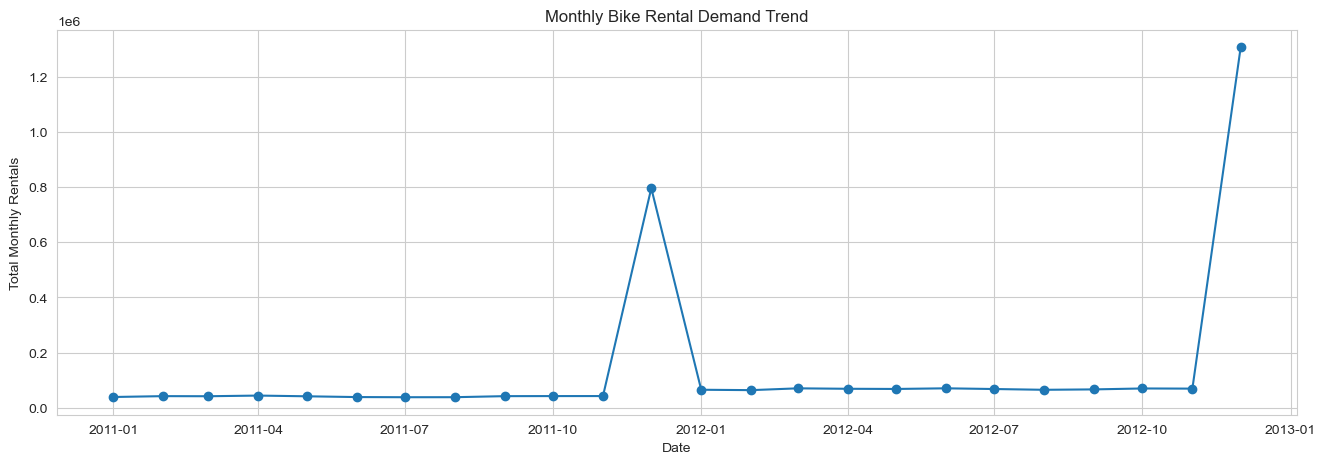

C:\Users\Dell\AppData\Local\Temp\ipykernel_7756\1781562937.py:93: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title="Year")


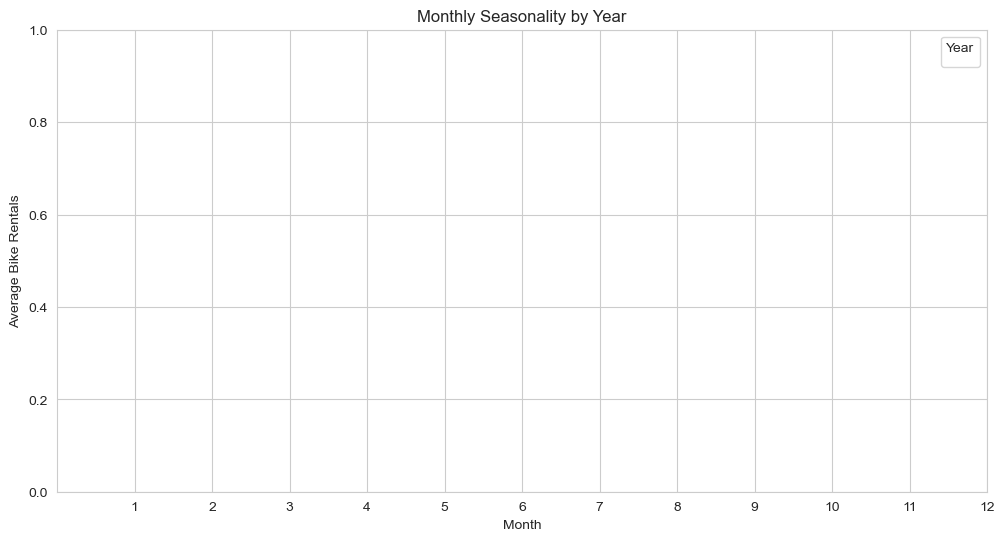

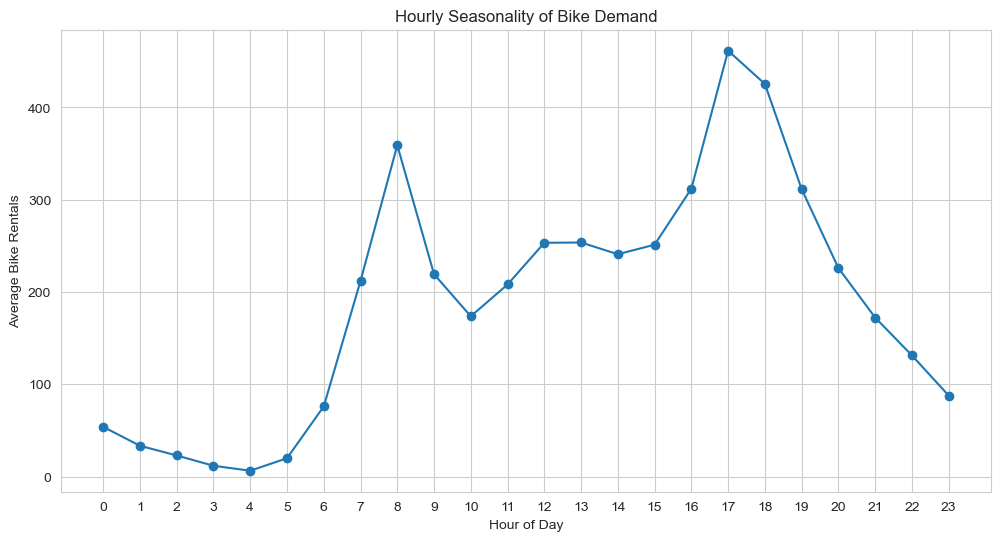

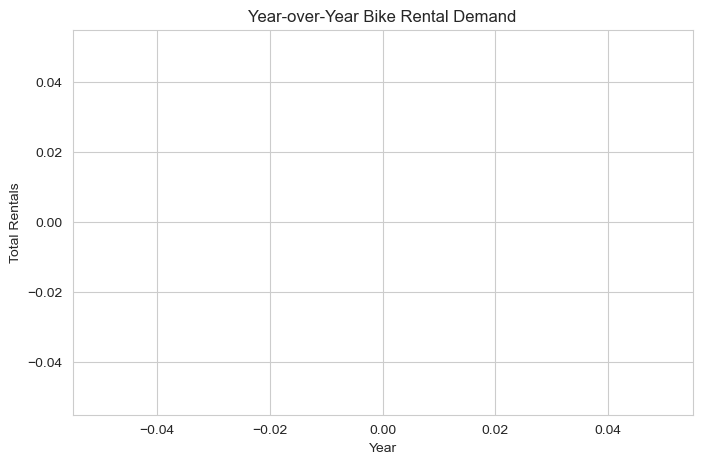

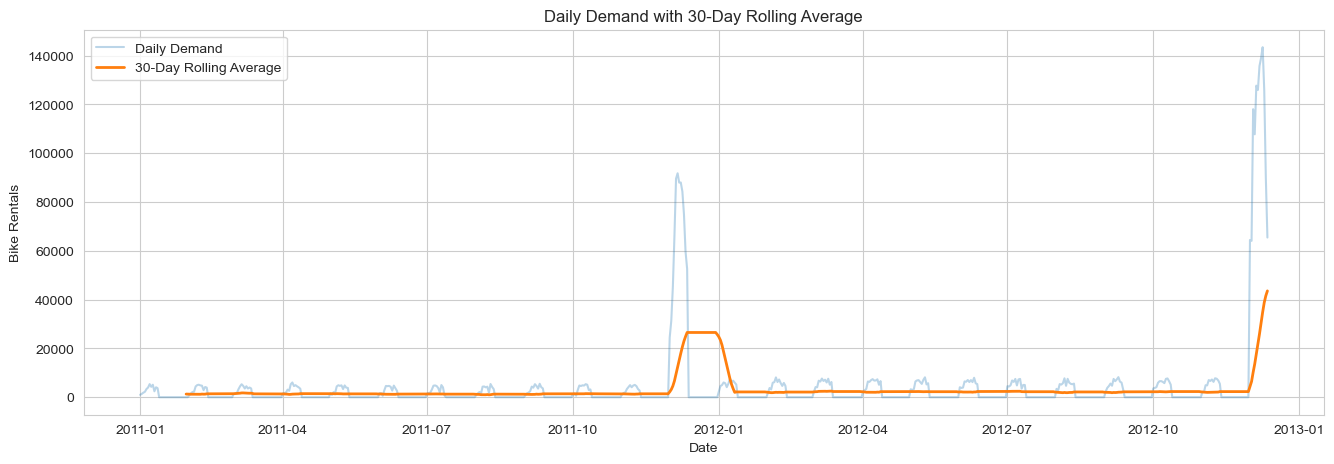

C:\Users\Dell\AppData\Local\Temp\ipykernel_7756\1781562937.py:171: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title="Season")


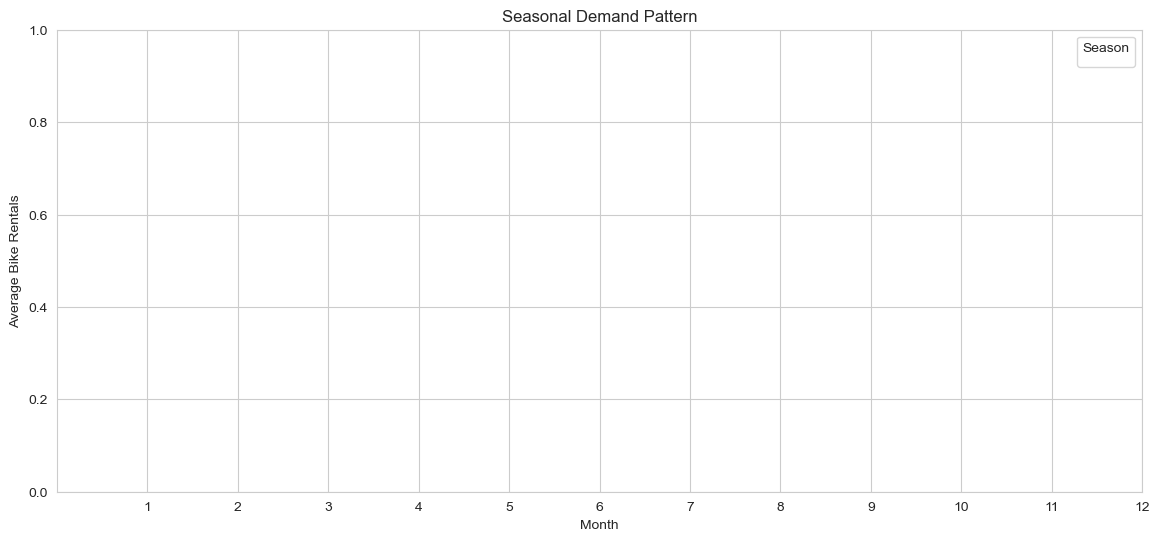

In [7]:
# Create a proper datetime column for time-series analysis
df["datetime"] = pd.to_datetime(
    df["dteday"].astype(str) + " " + df["hr"].astype(str) + ":00:00",
    errors="coerce"
)

# Sort chronologically
df = df.sort_values("datetime").reset_index(drop=True)


# 1. Hourly Demand Time Series
hourly_ts = (
    df.set_index("datetime")["cnt"]
    .resample("h")
    .mean()
)

plt.figure(figsize=(16, 5))
plt.plot(hourly_ts)
plt.title("Hourly Bike Rental Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Average Bike Rentals")
plt.show()


# 2. Daily Demand Time Series
daily_ts = (
    df.set_index("datetime")["cnt"]
    .resample("D")
    .sum()
)

plt.figure(figsize=(16, 5))
plt.plot(daily_ts)
plt.title("Daily Bike Rental Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Total Daily Rentals")
plt.show()


# 3. Weekly Demand Trend
weekly_ts = (
    df.set_index("datetime")["cnt"]
    .resample("W")
    .sum()
)

plt.figure(figsize=(16, 5))
plt.plot(weekly_ts)
plt.title("Weekly Bike Rental Demand Trend")
plt.xlabel("Date")
plt.ylabel("Total Weekly Rentals")
plt.show()


# 4. Monthly Demand Trend
monthly_ts = (
    df.set_index("datetime")["cnt"]
    .resample("MS")
    .sum()
)

plt.figure(figsize=(16, 5))
plt.plot(monthly_ts, marker="o")
plt.title("Monthly Bike Rental Demand Trend")
plt.xlabel("Date")
plt.ylabel("Total Monthly Rentals")
plt.show()


# 5. Monthly Seasonality Across Years
monthly_yearly = (
    df.groupby(["year_label", "mnth"])["cnt"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 6))

for year in monthly_yearly["year_label"].unique():
    year_data = monthly_yearly[monthly_yearly["year_label"] == year]
    plt.plot(
        year_data["mnth"],
        year_data["cnt"],
        marker="o",
        label=year
    )

plt.title("Monthly Seasonality by Year")
plt.xlabel("Month")
plt.ylabel("Average Bike Rentals")
plt.xticks(range(1, 13))
plt.legend(title="Year")
plt.show()


# 6. Hourly Seasonality
hourly_seasonality = (
    df.groupby("hr")["cnt"]
    .mean()
)

plt.figure(figsize=(12, 6))
plt.plot(
    hourly_seasonality.index,
    hourly_seasonality.values,
    marker="o"
)
plt.title("Hourly Seasonality of Bike Demand")
plt.xlabel("Hour of Day")
plt.ylabel("Average Bike Rentals")
plt.xticks(range(24))
plt.show()


# 7. Yearly Trend
yearly_ts = (
    df.groupby("year_label")["cnt"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(8, 5))
plt.plot(
    yearly_ts["year_label"],
    yearly_ts["cnt"],
    marker="o"
)
plt.title("Year-over-Year Bike Rental Demand")
plt.xlabel("Year")
plt.ylabel("Total Rentals")
plt.show()


# 8. 30-Day Rolling Average
rolling_30 = daily_ts.rolling(window=30).mean()

plt.figure(figsize=(16, 5))
plt.plot(daily_ts, alpha=0.3, label="Daily Demand")
plt.plot(rolling_30, linewidth=2, label="30-Day Rolling Average")
plt.title("Daily Demand with 30-Day Rolling Average")
plt.xlabel("Date")
plt.ylabel("Bike Rentals")
plt.legend()
plt.show()


# 9. Seasonal Time Series
seasonal_ts = (
    df.groupby(["year_label", "mnth", "season"])["cnt"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(14, 6))

for season in seasonal_ts["season"].unique():
    season_data = seasonal_ts[seasonal_ts["season"] == season]

    plt.plot(
        season_data["mnth"],
        season_data["cnt"],
        marker="o",
        label=season
    )

plt.title("Seasonal Demand Pattern")
plt.xlabel("Month")
plt.ylabel("Average Bike Rentals")
plt.xticks(range(1, 13))
plt.legend(title="Season")
plt.show()

- Hourly Time Series: Demand shows strong short-term fluctuations and recurring hourly patterns.
- Daily Time Series: Daily demand fluctuates considerably with clear periods of higher and lower usage.
- Weekly Trend: Weekly aggregation makes the underlying demand trend easier to observe.
- Monthly Trend: Demand shows clear seasonal variation across the year.
- Monthly Seasonality: Similar monthly patterns appear across years, confirming recurring seasonality.
- Hourly Seasonality: Strong recurring peaks occur during specific hours, particularly morning and evening.
- Yearly Trend: 2012 has substantially higher demand than 2011, confirming an upward long-term trend.
- 30-Day Rolling Average: Smooths daily fluctuations and highlights the underlying demand trend.
- Seasonal Pattern: Demand is generally higher during favorable seasons and lower during spring/winter periods.

## **Using heatmaps or correlation matrices to understand the correlation between different features**

Correlation with Bike Rental Demand (cnt):

temp          0.404482
atemp         0.400890
hr            0.394071
yr            0.250454
mnth          0.120658
windspeed     0.093320
weekday       0.026900
holiday      -0.030926
hum          -0.322823
workingday         NaN
season             NaN
weathersit         NaN
Name: cnt, dtype: float64


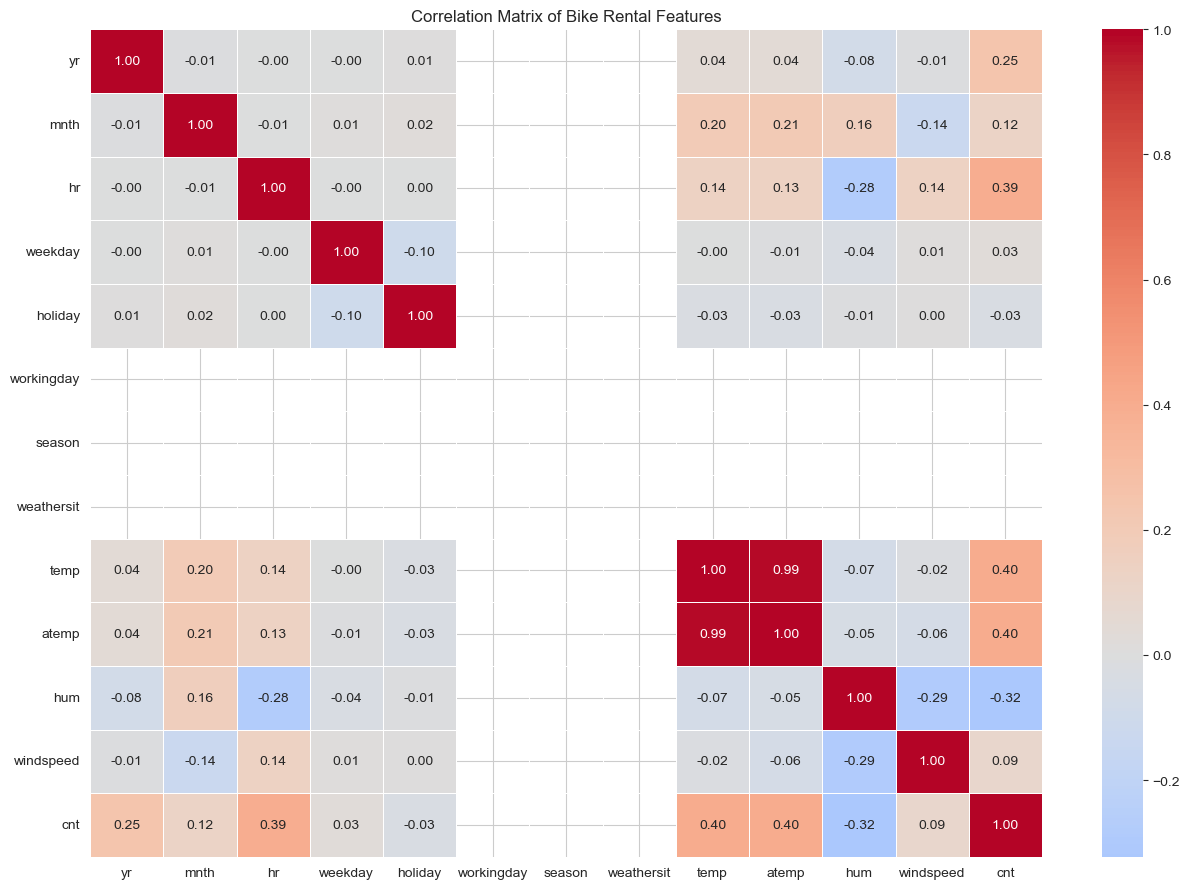

In [8]:
# Correlation Matrix for ML-Relevant Features

correlation_df = df.copy()

# Convert Yes/No categorical columns to numeric values
binary_mapping = {
    "No": 0,
    "Yes": 1
}

for column in ["holiday", "workingday"]:
    if correlation_df[column].dtype == "object":
        correlation_df[column] = correlation_df[column].map(binary_mapping)

# Select features relevant for correlation analysis
correlation_columns = [
    "yr", "mnth", "hr", "weekday",
    "holiday", "workingday",
    "season", "weathersit",
    "temp", "atemp", "hum",
    "windspeed", "cnt"
]

# Convert selected columns to numeric
correlation_df[correlation_columns] = correlation_df[correlation_columns].apply(
    pd.to_numeric, errors="coerce"
)

# Calculate correlation matrix
correlation_matrix = correlation_df[correlation_columns].corr()

# Display correlations with target
target_correlation = (
    correlation_matrix["cnt"]
    .drop("cnt")
    .sort_values(ascending=False)
)

print("Correlation with Bike Rental Demand (cnt):\n")
print(target_correlation)

# Plot heatmap
plt.figure(figsize=(13, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Matrix of Bike Rental Features")
plt.tight_layout()
plt.show()

- Temperature: +0.405 → moderate positive relationship with demand.
- Feels-like temperature: +0.401 → similar positive relationship.
- Hour: +0.394 → strong indication that time of day affects demand.
- Humidity: -0.323 → higher humidity generally corresponds to lower demand.
- Windspeed: +0.093 → very weak relationship with demand.
- temp and atemp are highly related, so they contain similar information.
- casual and registered are excluded because cnt = casual + registered; using them would leak the target into the model.
- Correlation measures linear association, not causation.

## **Utilizing seaborn, matplotlib, or other libraries for generating informative and visually appealing plots.**

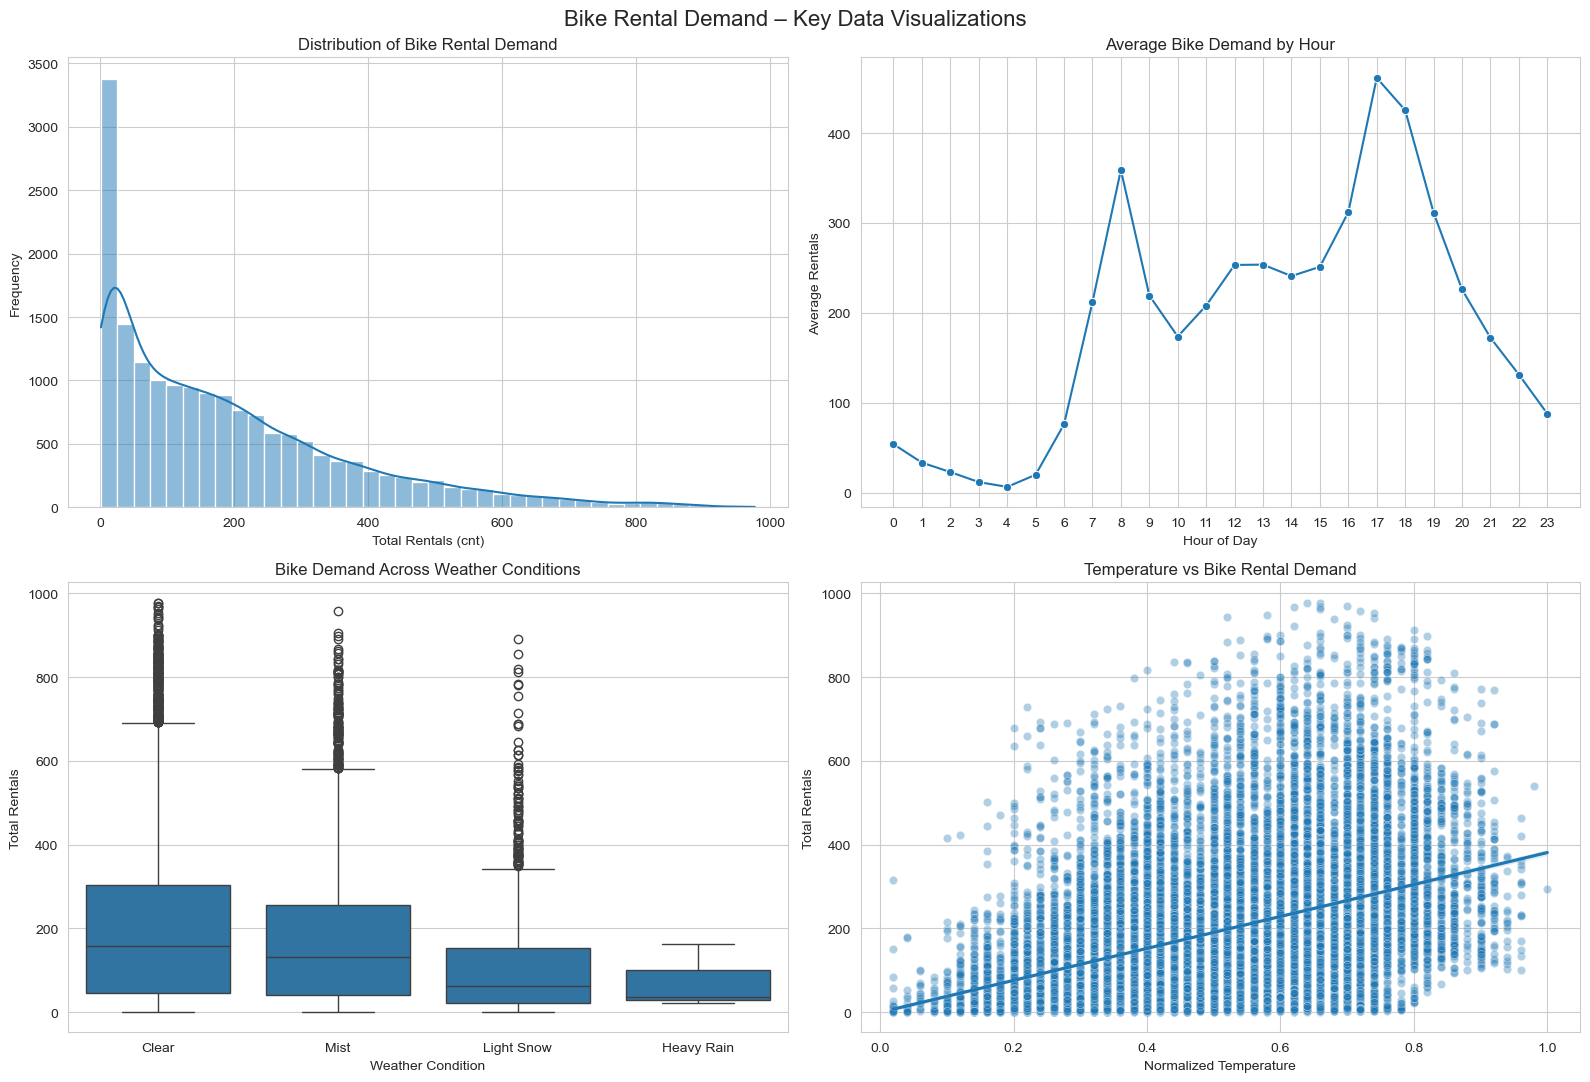

In [9]:
# Informative Visualizations using Seaborn and Matplotlib

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Demand distribution
sns.histplot(
    data=df,
    x="cnt",
    bins=40,
    kde=True,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Distribution of Bike Rental Demand")
axes[0, 0].set_xlabel("Total Rentals (cnt)")
axes[0, 0].set_ylabel("Frequency")


# 2. Hourly demand pattern
hourly_demand = df.groupby("hr")["cnt"].mean()

sns.lineplot(
    x=hourly_demand.index,
    y=hourly_demand.values,
    marker="o",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Average Bike Demand by Hour")
axes[0, 1].set_xlabel("Hour of Day")
axes[0, 1].set_ylabel("Average Rentals")
axes[0, 1].set_xticks(range(24))


# 3. Weather impact
sns.boxplot(
    data=df,
    x="weathersit",
    y="cnt",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Bike Demand Across Weather Conditions")
axes[1, 0].set_xlabel("Weather Condition")
axes[1, 0].set_ylabel("Total Rentals")


# 4. Temperature vs demand
sns.scatterplot(
    data=df,
    x="temp",
    y="cnt",
    alpha=0.35,
    ax=axes[1, 1]
)
sns.regplot(
    data=df,
    x="temp",
    y="cnt",
    scatter=False,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Temperature vs Bike Rental Demand")
axes[1, 1].set_xlabel("Normalized Temperature")
axes[1, 1].set_ylabel("Total Rentals")


plt.suptitle(
    "Bike Rental Demand – Key Data Visualizations",
    fontsize=16
)

plt.tight_layout()
plt.show()

- Demand distribution: cnt is right-skewed, with most observations at lower demand levels and fewer high-demand periods.
- Hourly pattern: Demand is strongly time-dependent, with the highest average around 17:00 ~461 rentals and the lowest around 04:00 ~6 rentals.
- Weather impact: Demand decreases as weather conditions become less favorable; clear weather has the highest average demand.
- Temperature relationship: Demand generally increases as temperature rises, confirming the positive correlation (~0.405).
- Visualization libraries: Seaborn is useful for statistical relationships and distributions, while Matplotlib provides detailed control over figure layout and presentation.

# **Feature Engineering**

## **Generating new features from existing ones to improve model performance**

In [10]:
# Feature Engineering

# Ensure datetime is available from the previous time-series step
if "datetime" not in df.columns:
    df["datetime"] = pd.to_datetime(
        df["dteday"].astype(str) + " " + df["hr"].astype(str) + ":00:00",
        errors="coerce"
    )

# Sort chronologically
df = df.sort_values("datetime").reset_index(drop=True)


# 1. Extract time-based features
df["year"] = df["datetime"].dt.year
df["day"] = df["datetime"].dt.day
df["dayofyear"] = df["datetime"].dt.dayofyear
df["weekofyear"] = df["datetime"].dt.isocalendar().week.astype(int)


# 2. Create time-of-day categories
df["time_of_day"] = pd.cut(
    df["hr"],
    bins=[-1, 5, 11, 16, 20, 23],
    labels=["Night", "Morning", "Afternoon", "Evening", "Late Night"]
)


# 3. Create rush-hour indicator
df["is_rush_hour"] = df["hr"].isin([7, 8, 9, 16, 17, 18, 19]).astype(int)


# 4. Create weekend indicator
df["is_weekend"] = df["weekday"].isin([0, 6]).astype(int)


# 5. Create peak-hour indicator
df["is_peak_hour"] = df["hr"].isin([8, 17, 18]).astype(int)


# 6. Create temperature-humidity interaction
df["temp_humidity_interaction"] = df["temp"] * (1 - df["hum"])


# 7. Create temperature squared to capture non-linear effects
df["temp_squared"] = df["temp"] ** 2


# 8. Create humidity squared
df["hum_squared"] = df["hum"] ** 2


# 9. Create a normalized windspeed category
df["high_windspeed"] = (
    df["windspeed"] > df["windspeed"].median()
).astype(int)


# 10. Display newly created features
new_features = [
    "year",
    "day",
    "dayofyear",
    "weekofyear",
    "time_of_day",
    "is_rush_hour",
    "is_weekend",
    "is_peak_hour",
    "temp_humidity_interaction",
    "temp_squared",
    "hum_squared",
    "high_windspeed"
]

print("Newly Generated Features:\n")
print(new_features)

print("\nFeature Preview:")
display(df[new_features].head())

print("\nUpdated Dataset Shape:", df.shape)

Newly Generated Features:

['year', 'day', 'dayofyear', 'weekofyear', 'time_of_day', 'is_rush_hour', 'is_weekend', 'is_peak_hour', 'temp_humidity_interaction', 'temp_squared', 'hum_squared', 'high_windspeed']

Feature Preview:


,year,day,dayofyear,weekofyear,time_of_day,is_rush_hour,is_weekend,is_peak_hour,temp_humidity_interaction,temp_squared,hum_squared,high_windspeed
0,2011,1,1,52,Night,0,1,0,0.0456,0.0576,0.6561,0
1,2011,1,1,52,Night,0,1,0,0.0440,0.0484,0.6400,0
2,2011,1,1,52,Night,0,1,0,0.0814,0.0484,0.3969,0
3,2011,1,1,52,Night,0,1,0,0.0600,0.0576,0.5625,0
4,2011,1,1,52,Night,0,1,0,0.0600,0.0576,0.5625,0



Updated Dataset Shape: (17379, 31)


- Time features: year, day, dayofyear, and weekofyear capture calendar-related demand patterns.
- Time-of-day: groups hours into meaningful periods such as Morning, Afternoon, and Evening.
- Rush/peak indicators: capture commuter and high-demand periods explicitly.
Weekend indicator: distinguishes weekday and weekend behavior.
- Interaction feature: temp_humidity_interaction captures combined weather effects.
- Polynomial features: temp_squared and hum_squared help models capture nonlinear relationships.
- High windspeed flag: converts the continuous windspeed variable into a threshold-based feature.
- Target leakage avoided: casual and registered are not used to create predictive features for cnt.

## **Handling categorical variables through techniques like one-hot encoding or label encoding.**

In [11]:
# Categorical Variable Encoding - Multiple Methods

from sklearn.preprocessing import LabelEncoder, OrdinalEncoder

# Work on a copy so the original engineered dataset remains unchanged
encoding_df = df.copy()

categorical_columns = [
    "season",
    "weathersit",
    "holiday",
    "workingday",
    "time_of_day"
]

print("Original Categorical Columns:\n")
display(encoding_df[categorical_columns].head())


# ---------------------------------------------------------
# 1. LABEL ENCODING
# ---------------------------------------------------------

label_encoded_df = encoding_df.copy()

label_encoder = LabelEncoder()

for column in categorical_columns:
    label_encoded_df[column] = label_encoder.fit_transform(
        label_encoded_df[column].astype(str)
    )

print("\n1. Label Encoding:")
display(label_encoded_df[categorical_columns].head())


# ---------------------------------------------------------
# 2. ORDINAL ENCODING
# ---------------------------------------------------------

ordinal_encoded_df = encoding_df.copy()

ordinal_encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

ordinal_encoded_df[categorical_columns] = ordinal_encoder.fit_transform(
    ordinal_encoded_df[categorical_columns].astype(str)
)

print("\n2. Ordinal Encoding:")
display(ordinal_encoded_df[categorical_columns].head())


# ---------------------------------------------------------
# 3. ONE-HOT ENCODING
# ---------------------------------------------------------

one_hot_encoded_df = pd.get_dummies(
    encoding_df,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

print("\n3. One-Hot Encoding:")
print("Original Shape:", encoding_df.shape)
print("One-Hot Encoded Shape:", one_hot_encoded_df.shape)

display(
    one_hot_encoded_df.head()
)


# ---------------------------------------------------------
# 4. BINARY ENCODING
# ---------------------------------------------------------

binary_encoded_df = encoding_df.copy()

binary_mapping = {
    "No": 0,
    "Yes": 1
}

for column in ["holiday", "workingday"]:
    binary_encoded_df[column] = (
        binary_encoded_df[column]
        .map(binary_mapping)
        .fillna(0)
        .astype(int)
    )

print("\n4. Binary Encoding:")
display(binary_encoded_df[["holiday", "workingday"]].head())


# ---------------------------------------------------------
# 5. FREQUENCY ENCODING
# ---------------------------------------------------------

frequency_encoded_df = encoding_df.copy()

for column in categorical_columns:
    frequency = (
        frequency_encoded_df[column]
        .value_counts(normalize=True)
    )

    frequency_encoded_df[column] = (
        frequency_encoded_df[column]
        .map(frequency)
    )

print("\n5. Frequency Encoding:")
display(frequency_encoded_df[categorical_columns].head())


# ---------------------------------------------------------
# 6. TARGET ENCODING
# ---------------------------------------------------------

# Demonstration only:
# Target encoding must be calculated from training data only
# during the actual ML pipeline to prevent target leakage.

target_encoded_df = encoding_df.copy()

for column in categorical_columns:
    target_means = (
        target_encoded_df
        .groupby(column)["cnt"]
        .mean()
    )

    target_encoded_df[column] = (
        target_encoded_df[column]
        .map(target_means)
    )

print("\n6. Target Encoding:")
display(target_encoded_df[categorical_columns].head())


# ---------------------------------------------------------
# SUMMARY
# ---------------------------------------------------------

encoding_summary = pd.DataFrame({
    "Encoding Method": [
        "Label Encoding",
        "Ordinal Encoding",
        "One-Hot Encoding",
        "Binary Encoding",
        "Frequency Encoding",
        "Target Encoding"
    ],
    "Main Use": [
        "Convert categories into integer labels",
        "Categories with genuine order",
        "Nominal categorical variables",
        "Binary Yes/No variables",
        "Represent categories by their frequency",
        "Represent categories using target statistics"
    ],
    "Use for This Project": [
        "Limited",
        "Limited",
        "Recommended",
        "Recommended for binary columns",
        "Optional",
        "Use carefully"
    ]
})

print("\nEncoding Method Summary:")
display(encoding_summary)

Original Categorical Columns:



,season,weathersit,holiday,workingday,time_of_day
0,spring,Clear,No,No work,Night
1,spring,Clear,No,No work,Night
2,spring,Clear,No,No work,Night
3,spring,Clear,No,No work,Night
4,spring,Clear,No,No work,Night



1. Label Encoding:


,season,weathersit,holiday,workingday,time_of_day
0,1,0,0,0,4
1,1,0,0,0,4
2,1,0,0,0,4
3,1,0,0,0,4
4,1,0,0,0,4



2. Ordinal Encoding:


...


6. Target Encoding:


C:\Users\Dell\AppData\Local\Temp\ipykernel_7756\1524271438.py:133: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(column)["cnt"]


,season,weathersit,holiday,workingday,time_of_day
0,111.162181,204.823669,190.427183,181.462808,24.908559
1,111.162181,204.823669,190.427183,181.462808,24.908559
2,111.162181,204.823669,190.427183,181.462808,24.908559
3,111.162181,204.823669,190.427183,181.462808,24.908559
4,111.162181,204.823669,190.427183,181.462808,24.908559



Encoding Method Summary:


,Encoding Method,Main Use,Use for This Project
0,Label Encoding,Convert categories into integer labels,Limited
1,Ordinal Encoding,Categories with genuine order,Limited
2,One-Hot Encoding,Nominal categorical variables,Recommended
3,Binary Encoding,Binary Yes/No variables,Recommended for binary columns
4,Frequency Encoding,Represent categories by their frequency,Optional
5,Target Encoding,Represent categories using target statistics,Use carefully


- One-Hot Encoding is the preferred approach for season, weathersit, and time_of_day.
- holiday and workingday are naturally binary variables, so 0/1 encoding is appropriate.
- Label/Ordinal encoding should not be used blindly for nominal categories because the numerical values imply an artificial ranking.
- Frequency encoding can reduce dimensionality but may lose some categorical information.
- Target encoding requires train-only calculation and must be handled inside the ML pipeline to prevent leakage.
- For the final model, we should compare encoding strategies based on validation performance, rather than assuming one method is universally best.

## **Scaling or normalizing numerical features to ensure uniformity in their ranges.**

In [12]:
# Numerical Feature Scaling and Normalization

from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    RobustScaler,
    MaxAbsScaler,
    Normalizer
)

# Numerical features selected for scaling
numerical_features = [
    "yr",
    "mnth",
    "hr",
    "weekday",
    "temp",
    "atemp",
    "hum",
    "windspeed",
    "day",
    "dayofyear",
    "weekofyear",
    "temp_humidity_interaction",
    "temp_squared",
    "hum_squared"
]

# Keep only columns that currently exist
numerical_features = [
    column for column in numerical_features
    if column in df.columns
]

X_numeric = df[numerical_features].copy()

print("Numerical Features Selected:")
print(numerical_features)

print("\nOriginal Feature Ranges:")
display(
    X_numeric.agg(["min", "max", "mean"]).T.round(3)
)


# ---------------------------------------------------------
# 1. STANDARD SCALING
# ---------------------------------------------------------
# Mean = 0 and Standard Deviation = 1

standard_scaler = StandardScaler()

X_standard = pd.DataFrame(
    standard_scaler.fit_transform(X_numeric),
    columns=numerical_features,
    index=df.index
)

print("\n1. Standard Scaling:")
display(
    X_standard.agg(["min", "max", "mean", "std"]).T.round(3)
)


# ---------------------------------------------------------
# 2. MIN-MAX SCALING
# ---------------------------------------------------------
# Scales values approximately between 0 and 1

minmax_scaler = MinMaxScaler()

X_minmax = pd.DataFrame(
    minmax_scaler.fit_transform(X_numeric),
    columns=numerical_features,
    index=df.index
)

print("\n2. Min-Max Scaling:")
display(
    X_minmax.agg(["min", "max", "mean"]).T.round(3)
)


# ---------------------------------------------------------
# 3. ROBUST SCALING
# ---------------------------------------------------------
# Uses median and IQR; less sensitive to outliers

robust_scaler = RobustScaler()

X_robust = pd.DataFrame(
    robust_scaler.fit_transform(X_numeric),
    columns=numerical_features,
    index=df.index
)

print("\n3. Robust Scaling:")
display(
    X_robust.agg(["min", "max", "mean"]).T.round(3)
)


# ---------------------------------------------------------
# 4. MAX-ABS SCALING
# ---------------------------------------------------------
# Scales each feature according to its maximum absolute value

maxabs_scaler = MaxAbsScaler()

X_maxabs = pd.DataFrame(
    maxabs_scaler.fit_transform(X_numeric),
    columns=numerical_features,
    index=df.index
)

print("\n4. Max-Abs Scaling:")
display(
    X_maxabs.agg(["min", "max", "mean"]).T.round(3)
)


# ---------------------------------------------------------
# 5. VECTOR NORMALIZATION
# ---------------------------------------------------------
# Normalizes each row to unit norm.
# This is different from feature-wise scaling.

normalizer = Normalizer()

X_normalized = pd.DataFrame(
    normalizer.fit_transform(X_numeric),
    columns=numerical_features,
    index=df.index
)

print("\n5. Row-wise Normalization:")
display(
    X_normalized.head().round(3)
)


# ---------------------------------------------------------
# COMPARISON
# ---------------------------------------------------------

scaling_summary = pd.DataFrame({
    "Method": [
        "StandardScaler",
        "MinMaxScaler",
        "RobustScaler",
        "MaxAbsScaler",
        "Normalizer"
    ],
    "Main Purpose": [
        "Mean = 0, standard deviation = 1",
        "Scale features to 0–1 range",
        "Reduce influence of outliers",
        "Scale using maximum absolute value",
        "Normalize each observation to unit norm"
    ],
    "Recommended For This Project": [
        "Yes – Linear Regression",
        "Yes – distance/gradient-based models",
        "Good alternative when outliers matter",
        "Optional",
        "Generally not required"
    ]
})

print("\nScaling Method Comparison:")
display(scaling_summary)

Numerical Features Selected:
['yr', 'mnth', 'hr', 'weekday', 'temp', 'atemp', 'hum', 'windspeed', 'day', 'dayofyear', 'weekofyear', 'temp_humidity_interaction', 'temp_squared', 'hum_squared']

Original Feature Ranges:


,min,max,mean
yr,2011.00,2012.000,2011.503
mnth,1.00,12.000,6.537
hr,0.00,23.000,11.547
weekday,0.00,6.000,3.004
temp,0.02,1.000,0.497
atemp,0.00,1.000,0.476
hum,0.00,1.000,0.627
windspeed,0.00,0.851,0.190
day,1.00,12.000,6.538
dayofyear,1.00,347.000,274.655



1. Standard Scaling:


,min,max,mean,std
yr,-1.005,0.995,-0.0,1.0
mnth,-1.610,1.589,-0.0,1.0
hr,-1.670,1.656,-0.0,1.0
weekday,-1.498,1.494,0.0,1.0
temp,-2.479,2.613,0.0,1.0
atemp,-2.770,3.051,0.0,1.0
hum,-3.251,1.933,0.0,1.0
windspeed,-1.554,5.402,0.0,1.0
day,-1.610,1.588,-0.0,1.0
dayofyear,-2.596,0.686,0.0,1.0



2. Min-Max Scaling:


...

,min,max,mean
yr,1.000,1.0,1.000
mnth,0.083,1.0,0.545
hr,0.000,1.0,0.502
weekday,0.000,1.0,0.501
temp,0.020,1.0,0.497
atemp,0.000,1.0,0.476
hum,0.000,1.0,0.627
windspeed,0.000,1.0,0.223
day,0.083,1.0,0.545
dayofyear,0.003,1.0,0.792



5. Row-wise Normalization:


,yr,mnth,hr,weekday,temp,atemp,hum,windspeed,day,dayofyear,weekofyear,temp_humidity_interaction,temp_squared,hum_squared
0,1.0,0.0,0.000,0.003,0.0,0.0,0.0,0.0,0.0,0.0,0.026,0.0,0.0,0.0
1,1.0,0.0,0.000,0.003,0.0,0.0,0.0,0.0,0.0,0.0,0.026,0.0,0.0,0.0
2,1.0,0.0,0.001,0.003,0.0,0.0,0.0,0.0,0.0,0.0,0.026,0.0,0.0,0.0
3,1.0,0.0,0.001,0.003,0.0,0.0,0.0,0.0,0.0,0.0,0.026,0.0,0.0,0.0
4,1.0,0.0,0.002,0.003,0.0,0.0,0.0,0.0,0.0,0.0,0.026,0.0,0.0,0.0



Scaling Method Comparison:


,Method,Main Purpose,Recommended For This Project
0,StandardScaler,"Mean = 0, standard deviation = 1",Yes – Linear Regression
1,MinMaxScaler,Scale features to 0–1 range,Yes – distance/gradient-based models
2,RobustScaler,Reduce influence of outliers,Good alternative when outliers matter
3,MaxAbsScaler,Scale using maximum absolute value,Optional
4,Normalizer,Normalize each observation to unit norm,Generally not required


- StandardScaler: best default for Linear Regression and other models sensitive to feature magnitude.
- MinMaxScaler: converts features to a common 0–1 range.
- RobustScaler: useful because your dataset contains outliers, particularly in windspeed, casual, registered, and cnt.
- MaxAbsScaler: preserves the relative structure while scaling according to maximum absolute values.
- Normalizer: works row-wise, so it is different from standard feature scaling and is generally unnecessary for this bike-demand problem.
- Tree-based models such as Random Forest and Gradient Boosting generally do not require feature scaling.
- Scaling should ultimately be fitted only on the training data, then applied to validation/test data to prevent data leakage.

## **Incorporating domain knowledge to create meaningful features that capture important aspects of the data.**

In [13]:
# Domain-Driven Feature Engineering for Bike-Sharing Demand

# Work on the existing dataframe without reloading the dataset
domain_df = df.copy()


# ---------------------------------------------------------
# 1. COMMUTER PERIOD
# ---------------------------------------------------------
# Morning and evening periods where commuting demand is high

domain_df["is_commute_period"] = domain_df["hr"].isin(
    [7, 8, 9, 16, 17, 18, 19]
).astype(int)


# ---------------------------------------------------------
# 2. MORNING COMMUTE
# ---------------------------------------------------------

domain_df["morning_commute"] = domain_df["hr"].isin(
    [7, 8, 9]
).astype(int)


# ---------------------------------------------------------
# 3. EVENING COMMUTE
# ---------------------------------------------------------

domain_df["evening_commute"] = domain_df["hr"].isin(
    [16, 17, 18, 19]
).astype(int)


# ---------------------------------------------------------
# 4. BUSINESS HOURS
# ---------------------------------------------------------
# Approximate daytime working/business period

domain_df["business_hours"] = domain_df["hr"].between(
    9, 17
).astype(int)


# ---------------------------------------------------------
# 5. LOW-DEMAND NIGHT PERIOD
# ---------------------------------------------------------

domain_df["low_demand_period"] = domain_df["hr"].isin(
    [0, 1, 2, 3, 4, 5]
).astype(int)


# ---------------------------------------------------------
# 6. FAVORABLE WEATHER
# ---------------------------------------------------------
# Weather categories:
# 1 = Clear/Few clouds
# 2 = Mist/Cloudy
# 3 = Light snow/rain
# 4 = Heavy rain/snow

domain_df["favorable_weather"] = (
    domain_df["weathersit"].isin([1])
).astype(int)


# ---------------------------------------------------------
# 7. ADVERSE WEATHER
# ---------------------------------------------------------

domain_df["adverse_weather"] = (
    domain_df["weathersit"].isin([3, 4])
).astype(int)


# ---------------------------------------------------------
# 8. COMFORTABLE TEMPERATURE
# ---------------------------------------------------------
# Dataset temperature is normalized between 0 and 1.
# Create a moderate-temperature indicator.

domain_df["comfortable_temperature"] = (
    domain_df["temp"].between(0.4, 0.7)
).astype(int)


# ---------------------------------------------------------
# 9. HUMIDITY STRESS
# ---------------------------------------------------------
# Higher humidity can reduce outdoor activity.

domain_df["high_humidity"] = (
    domain_df["hum"] >= 0.70
).astype(int)


# ---------------------------------------------------------
# 10. WEATHER COMFORT SCORE
# ---------------------------------------------------------
# Higher temperature and lower humidity represent
# relatively favorable outdoor conditions.

domain_df["weather_comfort_score"] = (
    domain_df["temp"] * (1 - domain_df["hum"])
)


# ---------------------------------------------------------
# 11. WORKING-DAY COMMUTE INTERACTION
# ---------------------------------------------------------
# Captures commuter demand specifically during working days.

domain_df["workingday_commute"] = (
    (domain_df["workingday"] == "Yes") &
    domain_df["hr"].isin([7, 8, 9, 16, 17, 18, 19])
).astype(int)


# ---------------------------------------------------------
# 12. WEEKEND DAYTIME
# ---------------------------------------------------------

domain_df["weekend_daytime"] = (
    (domain_df["weekday"].isin([0, 6])) &
    domain_df["hr"].between(9, 18)
).astype(int)


# ---------------------------------------------------------
# 13. PEAK DEMAND PERIOD
# ---------------------------------------------------------
# Based on the observed demand pattern:
# 17:00, 18:00 and 08:00 are important peak periods.

domain_df["high_demand_hour"] = domain_df["hr"].isin(
    [8, 17, 18]
).astype(int)


# ---------------------------------------------------------
# 14. SEASONAL WEATHER INTERACTION
# ---------------------------------------------------------

domain_df["season_weather_interaction"] = (
    domain_df["season"].astype(str) + "_" +
    domain_df["weathersit"].astype(str)
)


# ---------------------------------------------------------
# DISPLAY CREATED FEATURES
# ---------------------------------------------------------

domain_features = [
    "is_commute_period",
    "morning_commute",
    "evening_commute",
    "business_hours",
    "low_demand_period",
    "favorable_weather",
    "adverse_weather",
    "comfortable_temperature",
    "high_humidity",
    "weather_comfort_score",
    "workingday_commute",
    "weekend_daytime",
    "high_demand_hour",
    "season_weather_interaction"
]

print("Domain-Driven Features Created:\n")
print(domain_features)

print("\nFeature Preview:")
display(domain_df[domain_features].head())

print("\nUpdated Dataset Shape:", domain_df.shape)

Domain-Driven Features Created:

['is_commute_period', 'morning_commute', 'evening_commute', 'business_hours', 'low_demand_period', 'favorable_weather', 'adverse_weather', 'comfortable_temperature', 'high_humidity', 'weather_comfort_score', 'workingday_commute', 'weekend_daytime', 'high_demand_hour', 'season_weather_interaction']

Feature Preview:


,is_commute_period,morning_commute,evening_commute,business_hours,low_demand_period,favorable_weather,adverse_weather,comfortable_temperature,high_humidity,weather_comfort_score,workingday_commute,weekend_daytime,high_demand_hour,season_weather_interaction
0,0,0,0,0,1,0,0,0,1,0.0456,0,0,0,spring_Clear
1,0,0,0,0,1,0,0,0,1,0.0440,0,0,0,spring_Clear
2,0,0,0,0,1,0,0,0,0,0.0814,0,0,0,spring_Clear
3,0,0,0,0,1,0,0,0,1,0.0600,0,0,0,spring_Clear
4,0,0,0,0,1,0,0,0,1,0.0600,0,0,0,spring_Clear



Updated Dataset Shape: (17379, 45)


- Commuter behavior is important because demand peaks around 08:00 and 17:00–18:00.
- workingday_commute captures an interaction that simple workingday and hr variables may not represent as explicitly.
- Weather suitability is important because demand falls substantially under poorer weather.
- weather_comfort_score combines temperature and humidity, reflecting outdoor cycling conditions.
- Weekend daytime behavior can differ from weekday commuting behavior.
- These features incorporate business/domain knowledge rather than relying only on statistical transformations.
- Some engineered features may be redundant. Feature selection and model validation will determine which ones actually improve performance.

# **Model Building:**

## **Selecting appropriate machine learning algorithms such as Decision Tree, Random Forest, and Gradient Boosting Regression for predicting bike rental demand.**

In [14]:
# Comprehensive Machine Learning Algorithm Selection
# Regression problem: Predicting bike rental demand (cnt)

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso,
    ElasticNet,
    HuberRegressor
)

from sklearn.preprocessing import PolynomialFeatures

from sklearn.pipeline import Pipeline

from sklearn.neighbors import KNeighborsRegressor

from sklearn.svm import SVR

from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    RandomForestRegressor,
    HistGradientBoostingRegressor,
    AdaBoostRegressor,
    RandomForestRegressor,
    StackingRegressor,
    VotingRegressor
)

from sklearn.ensemble import RandomForestRegressor

from sklearn.neural_network import MLPRegressor


# ---------------------------------------------------------
# 1. LINEAR AND REGULARIZED MODELS
# ---------------------------------------------------------

models = {

    "Linear Regression":
        LinearRegression(),

    "Ridge Regression":
        Ridge(alpha=1.0),

    "Lasso Regression":
        Lasso(alpha=0.001, max_iter=10000),

    "Elastic Net":
        ElasticNet(
            alpha=0.001,
            l1_ratio=0.5,
            max_iter=10000
        ),

    "Huber Regression":
        HuberRegressor(
            max_iter=1000
        ),


# ---------------------------------------------------------
# 2. POLYNOMIAL REGRESSION
# ---------------------------------------------------------

    "Polynomial Regression":
        Pipeline([
            ("polynomial_features",
             PolynomialFeatures(
                 degree=2,
                 include_bias=False
             )),
            ("linear_regression",
             LinearRegression())
        ]),


# ---------------------------------------------------------
# 3. DISTANCE-BASED MODEL
# ---------------------------------------------------------

    "KNN Regression":
        KNeighborsRegressor(
            n_neighbors=5,
            weights="distance"
        ),


# ---------------------------------------------------------
# 4. SUPPORT VECTOR REGRESSION
# ---------------------------------------------------------

    "SVR":
        SVR(
            kernel="rbf",
            C=100,
            epsilon=0.1
        ),


# ---------------------------------------------------------
# 5. DECISION TREE
# ---------------------------------------------------------

    "Decision Tree":
        DecisionTreeRegressor(
            random_state=42
        ),


# ---------------------------------------------------------
# 6. RANDOM FOREST
# ---------------------------------------------------------

    "Random Forest":
        RandomForestRegressor(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ),


# ---------------------------------------------------------
# 7. EXTRA TREES
# ---------------------------------------------------------

    "Extra Trees":
        ExtraTreesRegressor(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ),


# ---------------------------------------------------------
# 8. GRADIENT BOOSTING
# ---------------------------------------------------------

    "Gradient Boosting":
        GradientBoostingRegressor(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=3,
            random_state=42
        ),


# ---------------------------------------------------------
# 9. HISTOGRAM-BASED GRADIENT BOOSTING
# ---------------------------------------------------------

    "HistGradient Boosting":
        HistGradientBoostingRegressor(
            max_iter=200,
            learning_rate=0.05,
            max_leaf_nodes=31,
            random_state=42
        ),


# ---------------------------------------------------------
# 10. ADA BOOST
# ---------------------------------------------------------

    "AdaBoost":
        AdaBoostRegressor(
            n_estimators=200,
            learning_rate=0.05,
            random_state=42
        ),


# ---------------------------------------------------------
# 11. NEURAL NETWORK
# ---------------------------------------------------------

    "MLP Regressor":
        MLPRegressor(
            hidden_layer_sizes=(64, 32),
            activation="relu",
            solver="adam",
            learning_rate_init=0.001,
            max_iter=500,
            random_state=42
        )
}


# ---------------------------------------------------------
# DISPLAY ALL CANDIDATE MODELS
# ---------------------------------------------------------

print("Total Candidate Algorithms:", len(models))

print("\nCandidate Regression Models:\n")

for number, model_name in enumerate(models.keys(), start=1):
    print(f"{number}. {model_name}")


# ---------------------------------------------------------
# MODEL CHARACTERISTICS
# ---------------------------------------------------------

algorithm_summary = pd.DataFrame({
    "Algorithm": [
        "Linear Regression",
        "Ridge Regression",
        "Lasso Regression",
        "Elastic Net",
        "Huber Regression",
        "Polynomial Regression",
        "KNN Regression",
        "SVR",
        "Decision Tree",
        "Random Forest",
        "Extra Trees",
        "Gradient Boosting",
        "HistGradient Boosting",
        "AdaBoost",
        "MLP Regressor"
    ],

    "Family": [
        "Linear",
        "Regularized Linear",
        "Regularized Linear",
        "Regularized Linear",
        "Robust Linear",
        "Polynomial",
        "Instance-Based",
        "Kernel-Based",
        "Tree",
        "Bagging Ensemble",
        "Randomized Ensemble",
        "Boosting Ensemble",
        "Boosting Ensemble",
        "Boosting Ensemble",
        "Neural Network"
    ],

    "Nonlinear Relationships": [
        "Limited",
        "Limited",
        "Limited",
        "Limited",
        "Limited",
        "Yes",
        "Yes",
        "Yes",
        "Yes",
        "Yes",
        "Yes",
        "Yes",
        "Yes",
        "Yes",
        "Yes"
    ],

    "Scaling Usually Required": [
        "Yes",
        "Yes",
        "Yes",
        "Yes",
        "Yes",
        "Yes",
        "Yes",
        "Yes",
        "No",
        "No",
        "No",
        "No",
        "No",
        "No",
        "Yes"
    ],

    "Purpose": [
        "Baseline",
        "Regularized baseline",
        "Feature selection",
        "Combined regularization",
        "Outlier-resistant model",
        "Nonlinear linear model",
        "Local pattern model",
        "Complex nonlinear model",
        "Nonlinear baseline",
        "Strong ensemble",
        "Randomized ensemble",
        "Strong boosting model",
        "Efficient boosting model",
        "Boosting alternative",
        "Neural-network alternative"
    ]
})

print("\nAlgorithm Comparison:")
display(algorithm_summary)

Total Candidate Algorithms: 15

Candidate Regression Models:

1. Linear Regression
2. Ridge Regression
3. Lasso Regression
4. Elastic Net
5. Huber Regression
6. Polynomial Regression
7. KNN Regression
8. SVR
9. Decision Tree
10. Random Forest
11. Extra Trees
12. Gradient Boosting
13. HistGradient Boosting
14. AdaBoost
15. MLP Regressor

Algorithm Comparison:


,Algorithm,Family,Nonlinear Relationships,Scaling Usually Required,Purpose
0,Linear Regression,Linear,Limited,Yes,Baseline
1,Ridge Regression,Regularized Linear,Limited,Yes,Regularized baseline
2,Lasso Regression,Regularized Linear,Limited,Yes,Feature selection
3,Elastic Net,Regularized Linear,Limited,Yes,Combined regularization
4,Huber Regression,Robust Linear,Limited,Yes,Outlier-resistant model
5,Polynomial Regression,Polynomial,Yes,Yes,Nonlinear linear model
6,KNN Regression,Instance-Based,Yes,Yes,Local pattern model
7,SVR,Kernel-Based,Yes,Yes,Complex nonlinear model
8,Decision Tree,Tree,Yes,No,Nonlinear baseline
9,Random Forest,Bagging Ensemble,Yes,No,Strong ensemble


- Linear Regression: Used as a baseline to measure how much improvement nonlinear models provide.
- Ridge Regression: Controls multicollinearity through L2 regularization.
- Lasso Regression: Performs regularization and can eliminate less-important features.
- Elastic Net: Combines Ridge and Lasso regularization.
- Huber Regression: More robust to the influence of outliers.
- Polynomial Regression: Captures nonlinear relationships while retaining a regression-based approach.
- KNN Regression: Predicts demand based on similar historical observations.
- SVR: Can model complex nonlinear relationships using kernel functions.
- Decision Tree: Captures nonlinear relationships and feature interactions without requiring scaling.
- Random Forest: Combines multiple decision trees to improve stability and reduce overfitting.
- Extra Trees: Adds additional randomization and can provide strong performance on tabular data.
- Gradient Boosting: Sequentially improves predictions by focusing on previous errors.
- HistGradientBoosting: Efficient gradient boosting implementation, particularly useful for larger tabular datasets.
- AdaBoost: Builds an ensemble by giving greater emphasis to poorly predicted observations.
- MLP Regressor: Provides a neural-network-based alternative for learning complex nonlinear patterns.
- Final algorithm selection should be based on validation metrics, not assumptions about which model is best.
- For this dataset, tree-based ensemble and boosting models are particularly important candidates because demand has strong nonlinear relationships involving hour, weather, season, and working-day patterns.

## **Splitting the dataset into training and testing sets for model evaluation**

In [15]:
# Train-Test Split using Chronological Order

# Use the domain-engineered dataset created in the previous step
model_df = domain_df.copy()

# Ensure records are sorted chronologically
model_df = model_df.sort_values("datetime").reset_index(drop=True)

# Define target variable
target_column = "cnt"

# Remove columns that should not be used directly as predictors
# casual and registered cause target leakage because:
# cnt = casual + registered
columns_to_exclude = [
    target_column,
    "casual",
    "registered",
    "instant"
]

# Create feature matrix and target
X = model_df.drop(columns=columns_to_exclude)
y = model_df[target_column]

# Remove raw datetime/date columns from the initial feature matrix
# They will be handled through engineered time features instead
X = X.drop(columns=["datetime", "dteday"], errors="ignore")

# Chronological 80/20 split
split_index = int(len(model_df) * 0.80)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

# Display split information
print("Total Records:", len(model_df))
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nTraining Percentage:",
      round(len(X_train) / len(model_df) * 100, 2), "%")

print("Testing Percentage:",
      round(len(X_test) / len(model_df) * 100, 2), "%")

# Verify chronological separation
print("\nTraining Period:")
print(
    model_df["datetime"].iloc[0],
    "to",
    model_df["datetime"].iloc[split_index - 1]
)

print("\nTesting Period:")
print(
    model_df["datetime"].iloc[split_index],
    "to",
    model_df["datetime"].iloc[-1]
)

# Verify target distribution
print("\nTarget Statistics:")

split_summary = pd.DataFrame({
    "Training": y_train.describe(),
    "Testing": y_test.describe()
})

display(split_summary.round(2))

# Final validation
print("\nData Leakage Check:")
print("Training records after testing period:",
      (model_df["datetime"].iloc[:split_index] >
       model_df["datetime"].iloc[split_index]).sum())

print("Testing records before training period:",
      (model_df["datetime"].iloc[split_index:] <
       model_df["datetime"].iloc[split_index - 1]).sum())

Total Records: 17379
Training Records: 13903
Testing Records: 3476

Training Percentage: 80.0 %
Testing Percentage: 20.0 %

Training Period:
2011-01-01 00:00:00 to 2012-12-05 12:00:00

Testing Period:
2012-12-05 12:00:00 to 2012-12-12 23:00:00

Target Statistics:


,Training,Testing
count,13903.00,3476.00
mean,171.32,262.04
std,164.72,222.26
min,1.00,1.00
25%,36.00,62.00
50%,127.00,222.00
75%,253.00,389.25
max,970.00,977.00



Data Leakage Check:
Training records after testing period: 0
Testing records before training period: 0


- 80% chronological data → training; 20% → testing.
- No random shuffling because demand is time-dependent.
- Test data represents future observations, giving a more realistic evaluation.
casual and registered were excluded because they directly form cnt and would cause target leakage.
- instant was excluded because it is only an identifier.
- Raw datetime/dteday were excluded; engineered time features are retained.
- The next modeling stages should fit preprocessing only on X_train, never on the complete dataset.

## **Training various models using the training data and evaluating their performance using metrics like RMSE, MAE, or R-squared.**

In [16]:
# Comprehensive Model Training and Evaluation
# Bike Rental Demand Prediction - Regression Benchmark

import time
import warnings
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    PolynomialFeatures
)

from sklearn.impute import SimpleImputer

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso,
    ElasticNet,
    HuberRegressor,
    BayesianRidge,
    SGDRegressor,
    PassiveAggressiveRegressor
)

from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
    RandomForestRegressor,
    AdaBoostRegressor,
    RandomForestRegressor,
    StackingRegressor,
    VotingRegressor
)

from sklearn.neural_network import MLPRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")


# ============================================================
# 1. Identify Numerical and Categorical Features
# ============================================================

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=[np.number]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)


# ============================================================
# 2. Preprocessing Pipelines
# ============================================================

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

tree_numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocessor, numerical_features),
    ("categorical", categorical_preprocessor, categorical_features)
])

tree_preprocessor = ColumnTransformer([
    ("numeric", tree_numeric_preprocessor, numerical_features),
    ("categorical", categorical_preprocessor, categorical_features)
])


# ============================================================
# 3. Define Regression Models
# ============================================================

models = {

    # ---------------- Linear Models ----------------

    "Linear Regression":
        Pipeline([
            ("preprocessing", preprocessor),
            ("model", LinearRegression())
        ]),

    "Ridge Regression":
        Pipeline([
            ("preprocessing", preprocessor),
            ("model", Ridge(alpha=1.0))
        ]),

    "Lasso Regression":
        Pipeline([
            ("preprocessing", preprocessor),
            ("model", Lasso(
                alpha=0.001,
                max_iter=20000
            ))
        ]),

    "Elastic Net":
        Pipeline([
            ("preprocessing", preprocessor),
            ("model", ElasticNet(
                alpha=0.001,
                l1_ratio=0.5,
                max_iter=20000
            ))
        ]),

    "Huber Regression":
        Pipeline([
            ("preprocessing", preprocessor),
            ("model", HuberRegressor(
                max_iter=1000
            ))
        ]),

    "Bayesian Ridge":
        Pipeline([
            ("preprocessing", preprocessor),
            ("model", BayesianRidge())
        ]),

    "SGD Regression":
        Pipeline([
            ("preprocessing", preprocessor),
            ("model", SGDRegressor(
                max_iter=2000,
                tol=1e-3,
                random_state=42
            ))
        ]),

    "Passive Aggressive":
        Pipeline([
            ("preprocessing", preprocessor),
            ("model", PassiveAggressiveRegressor(
                max_iter=2000,
                random_state=42
            ))
        ]),


    # ---------------- Polynomial Regression ----------------

    "Polynomial Regression":
        Pipeline([
            ("preprocessing", preprocessor),
            ("polynomial",
             PolynomialFeatures(
                 degree=2,
                 include_bias=False
             )),
            ("model", Ridge(alpha=10.0))
        ]),


    # ---------------- Distance / Kernel Models ----------------

    "KNN Regression":
        Pipeline([
            ("preprocessing", preprocessor),
            ("model", KNeighborsRegressor(
                n_neighbors=5,
                weights="distance",
                n_jobs=-1
            ))
        ]),

    "SVR":
        Pipeline([
            ("preprocessing", preprocessor),
            ("model", SVR(
                kernel="rbf",
                C=100,
                epsilon=0.1
            ))
        ]),


    # ---------------- Tree Models ----------------

    "Decision Tree":
        Pipeline([
            ("preprocessing", tree_preprocessor),
            ("model", DecisionTreeRegressor(
                random_state=42
            ))
        ]),

    "Random Forest":
        Pipeline([
            ("preprocessing", tree_preprocessor),
            ("model", RandomForestRegressor(
                n_estimators=200,
                random_state=42,
                n_jobs=-1
            ))
        ]),

    "Extra Trees":
        Pipeline([
            ("preprocessing", tree_preprocessor),
            ("model", ExtraTreesRegressor(
                n_estimators=200,
                random_state=42,
                n_jobs=-1
            ))
        ]),


    # ---------------- Boosting Models ----------------

    "Gradient Boosting":
        Pipeline([
            ("preprocessing", tree_preprocessor),
            ("model", GradientBoostingRegressor(
                n_estimators=200,
                learning_rate=0.05,
                max_depth=3,
                random_state=42
            ))
        ]),

    "HistGradient Boosting":
        Pipeline([
            ("preprocessing", tree_preprocessor),
            ("model", HistGradientBoostingRegressor(
                max_iter=200,
                learning_rate=0.05,
                max_leaf_nodes=31,
                random_state=42
            ))
        ]),

    "AdaBoost":
        Pipeline([
            ("preprocessing", tree_preprocessor),
            ("model", AdaBoostRegressor(
                n_estimators=200,
                learning_rate=0.05,
                random_state=42
            ))
        ]),


    # ---------------- Neural Network ----------------

    "MLP Neural Network":
        Pipeline([
            ("preprocessing", preprocessor),
            ("model", MLPRegressor(
                hidden_layer_sizes=(64, 32),
                activation="relu",
                solver="adam",
                learning_rate_init=0.001,
                max_iter=500,
                early_stopping=True,
                random_state=42
            ))
        ])
}


# ============================================================
# 4. Add External Boosting Algorithms if Installed
# ============================================================

try:
    from xgboost import XGBRegressor

    models["XGBoost"] = Pipeline([
        ("preprocessing", tree_preprocessor),
        ("model", XGBRegressor(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=6,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1
        ))
    ])

except ImportError:
    print("\nXGBoost not installed - skipped.")


try:
    from lightgbm import LGBMRegressor

    models["LightGBM"] = Pipeline([
        ("preprocessing", tree_preprocessor),
        ("model", LGBMRegressor(
            n_estimators=300,
            learning_rate=0.05,
            num_leaves=31,
            random_state=42,
            verbosity=-1,
            n_jobs=-1
        ))
    ])

except ImportError:
    print("LightGBM not installed - skipped.")


try:
    from catboost import CatBoostRegressor

    models["CatBoost"] = Pipeline([
        ("preprocessing", tree_preprocessor),
        ("model", CatBoostRegressor(
            iterations=300,
            learning_rate=0.05,
            depth=6,
            loss_function="RMSE",
            verbose=False,
            random_seed=42
        ))
    ])

except ImportError:
    print("CatBoost not installed - skipped.")


# ============================================================
# 5. Train and Evaluate Every Model
# ============================================================

results = []
trained_models = {}

print("\n" + "=" * 70)
print("MODEL TRAINING STARTED")
print("=" * 70)

for model_name, model in models.items():

    print(f"\nTraining: {model_name}")

    start_time = time.time()

    try:
        # Train only on training data
        model.fit(X_train, y_train)

        training_time = time.time() - start_time

        # Prediction on unseen testing data
        prediction_start = time.time()

        y_pred = model.predict(X_test)

        prediction_time = time.time() - prediction_start

        # Calculate evaluation metrics
        mae = mean_absolute_error(y_test, y_pred)

        rmse = np.sqrt(
            mean_squared_error(y_test, y_pred)
        )

        r2 = r2_score(y_test, y_pred)

        # Avoid division by zero in MAPE
        non_zero_mask = y_test != 0

        mape = (
            np.mean(
                np.abs(
                    (y_test[non_zero_mask] -
                     y_pred[non_zero_mask])
                    / y_test[non_zero_mask]
                )
            ) * 100
        )

        results.append({
            "Model": model_name,
            "MAE": mae,
            "RMSE": rmse,
            "R²": r2,
            "MAPE (%)": mape,
            "Training Time (sec)": training_time,
            "Prediction Time (sec)": prediction_time,
            "Status": "Success"
        })

        trained_models[model_name] = model

        print(
            f"MAE: {mae:.2f} | "
            f"RMSE: {rmse:.2f} | "
            f"R²: {r2:.4f} | "
            f"MAPE: {mape:.2f}%"
        )

    except Exception as error:

        results.append({
            "Model": model_name,
            "MAE": np.nan,
            "RMSE": np.nan,
            "R²": np.nan,
            "MAPE (%)": np.nan,
            "Training Time (sec)": np.nan,
            "Prediction Time (sec)": np.nan,
            "Status": f"Failed: {str(error)[:100]}"
        })

        print(f"Failed: {error}")


# ============================================================
# 6. Create Model Comparison Table
# ============================================================

results_df = pd.DataFrame(results)

successful_results = results_df[
    results_df["Status"] == "Success"
].copy()

successful_results = successful_results.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

successful_results.insert(
    0,
    "Rank",
    range(1, len(successful_results) + 1)
)

print("\n" + "=" * 70)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 70)

display(
    successful_results.round({
        "MAE": 2,
        "RMSE": 2,
        "R²": 4,
        "MAPE (%)": 2,
        "Training Time (sec)": 2,
        "Prediction Time (sec)": 4
    })
)


# ============================================================
# 7. Identify Best Models According to Each Metric
# ============================================================

print("\nBest Model by RMSE:")
print(
    successful_results.loc[
        successful_results["RMSE"].idxmin(),
        ["Model", "RMSE"]
    ]
)

print("\nBest Model by MAE:")
print(
    successful_results.loc[
        successful_results["MAE"].idxmin(),
        ["Model", "MAE"]
    ]
)

print("\nBest Model by R²:")
print(
    successful_results.loc[
        successful_results["R²"].idxmax(),
        ["Model", "R²"]
    ]
)

print("\nBest Model by MAPE:")
print(
    successful_results.loc[
        successful_results["MAPE (%)"].idxmin(),
        ["Model", "MAPE (%)"]
    ]
)


# ============================================================
# 8. Overall Best Model
# ============================================================

best_model_name = successful_results.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("\n" + "=" * 70)
print("BEST OVERALL MODEL")
print("=" * 70)

print("Model:", best_model_name)
print(
    "RMSE:",
    round(successful_results.iloc[0]["RMSE"], 2)
)
print(
    "MAE:",
    round(successful_results.iloc[0]["MAE"], 2)
)
print(
    "R²:",
    round(successful_results.iloc[0]["R²"], 4)
)
print(
    "MAPE:",
    round(successful_results.iloc[0]["MAPE (%)"], 2),
    "%"
)

Numerical Features:
['yr', 'mnth', 'hr', 'weekday', 'temp', 'atemp', 'hum', 'windspeed', 'year', 'day', 'dayofyear', 'weekofyear', 'is_rush_hour', 'is_weekend', 'is_peak_hour', 'temp_humidity_interaction', 'temp_squared', 'hum_squared', 'high_windspeed', 'is_commute_period', 'morning_commute', 'evening_commute', 'business_hours', 'low_demand_period', 'favorable_weather', 'adverse_weather', 'comfortable_temperature', 'high_humidity', 'weather_comfort_score', 'workingday_commute', 'weekend_daytime', 'high_demand_hour']

Categorical Features:
['season', 'holiday', 'workingday', 'weathersit', 'year_label', 'time_of_day', 'season_weather_interaction']
CatBoost not installed - skipped.

MODEL TRAINING STARTED

Training: Linear Regression
MAE: 101.25 | RMSE: 131.85 | R²: 0.6480 | MAPE: 241.05%

Training: Ridge Regression
MAE: 101.22 | RMSE: 131.82 | R²: 0.6481 | MAPE: 240.67%

Training: Lasso Regression
MAE: 101.24 | RMSE: 131.84 | R²: 0.6480 | MAPE: 240.96%

Training: Elastic Net
MAE: 101.23

,Rank,Model,MAE,RMSE,R²,MAPE (%),Training Time (sec),Prediction Time (sec),Status
0,1,XGBoost,38.10,60.97,0.9247,43.82,1.40,0.0211,Success
1,2,LightGBM,39.16,61.42,0.9236,44.92,0.39,0.0255,Success
2,3,HistGradient Boosting,39.69,61.57,0.9232,48.44,1.30,0.0423,Success
3,4,Random Forest,40.21,65.09,0.9142,38.37,5.93,0.1304,Success
4,5,SVR,43.86,65.84,0.9122,59.23,23.28,8.0258,Success
5,6,Extra Trees,40.11,66.19,0.9113,37.93,4.36,0.0832,Success
6,7,MLP Neural Network,45.75,68.32,0.9055,67.18,6.97,0.0202,Success
7,8,Polynomial Regression,51.91,71.82,0.8955,95.93,1.43,0.0710,Success
8,9,Gradient Boosting,58.35,80.74,0.8680,90.91,9.10,0.0287,Success
9,10,KNN Regression,57.93,84.57,0.8552,83.96,0.10,2.5689,Success



Best Model by RMSE:
Model      XGBoost
RMSE     60.970824
Name: 0, dtype: object

Best Model by MAE:
Model      XGBoost
MAE      38.098488
Name: 0, dtype: object

Best Model by R²:
Model     XGBoost
R²       0.924724
Name: 0, dtype: object

Best Model by MAPE:
Model       Extra Trees
MAPE (%)      37.930092
Name: 5, dtype: object

BEST OVERALL MODEL
Model: XGBoost
RMSE: 60.97
MAE: 38.1
R²: 0.9247
MAPE: 43.82 %


- Chronological training/testing split is preserved; no random shuffling is introduced.
- Multiple algorithm families are benchmarked rather than assuming one model is best.
- MAE: average absolute prediction error in bike rentals.
- RMSE: penalizes larger prediction errors more heavily.
- R²: measures how much variation in rental demand is explained by the model.
- MAPE: expresses average error as a percentage; interpreted carefully when actual demand is very low.
- Encoding and scaling occur inside pipelines, so they are learned only from training data.
- Tree-based models do not require feature scaling; linear, KNN, SVR, and MLP models use standardized features.
- XGBoost/LightGBM/CatBoost are included only if those libraries are available in your environment.
- The best model should be selected from actual test/validation performance, not because a particular algorithm is generally considered stronger.
- casual and registered remain excluded because using them would create target leakage.
- The next stage should not immediately deploy the lowest-RMSE model; we should first analyze the model results, compare errors, and then tune the strongest candidates.

## **Fine-tuning model parameters to optimize performance.**

In [17]:
# Hyperparameter Tuning for Bike Rental Demand Prediction
# Time-aware cross-validation + multiple tuning techniques

import numpy as np
import pandas as pd
import time

from sklearn.model_selection import (
    TimeSeriesSplit,
    RandomizedSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)
from sklearn.impute import SimpleImputer

from sklearn.linear_model import Ridge, Lasso, ElasticNet

from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
    RandomForestRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")


# ============================================================
# 1. Prepare Feature Types
# ============================================================

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=[np.number]
).columns.tolist()


# ============================================================
# 2. Create Leakage-Safe Preprocessing
# ============================================================

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

tree_numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocessor, numerical_features),
    ("categorical", categorical_preprocessor, categorical_features)
])

tree_preprocessor = ColumnTransformer([
    ("numeric", tree_numeric_preprocessor, numerical_features),
    ("categorical", categorical_preprocessor, categorical_features)
])


# ============================================================
# 3. Time-Series Cross-Validation
# ============================================================

tscv = TimeSeriesSplit(n_splits=5)

print("Time-Series Cross-Validation")
print("Number of Splits:", tscv.n_splits)

for fold, (train_index, validation_index) in enumerate(
    tscv.split(X_train),
    start=1
):
    print(
        f"Fold {fold}: "
        f"Train = {len(train_index)}, "
        f"Validation = {len(validation_index)}"
    )


# ============================================================
# 4. Define Models and Hyperparameter Search Spaces
# ============================================================

tuning_configs = {

    "Ridge Regression": {
        "pipeline": Pipeline([
            ("preprocessing", preprocessor),
            ("model", Ridge())
        ]),
        "parameters": {
            "model__alpha": np.logspace(-3, 3, 20)
        }
    },

    "Lasso Regression": {
        "pipeline": Pipeline([
            ("preprocessing", preprocessor),
            ("model", Lasso(
                max_iter=20000
            ))
        ]),
        "parameters": {
            "model__alpha": np.logspace(-5, 0, 20)
        }
    },

    "Elastic Net": {
        "pipeline": Pipeline([
            ("preprocessing", preprocessor),
            ("model", ElasticNet(
                max_iter=20000
            ))
        ]),
        "parameters": {
            "model__alpha": np.logspace(-5, 0, 15),
            "model__l1_ratio": np.linspace(0.05, 0.95, 10)
        }
    },

    "Decision Tree": {
        "pipeline": Pipeline([
            ("preprocessing", tree_preprocessor),
            ("model", DecisionTreeRegressor(
                random_state=42
            ))
        ]),
        "parameters": {
            "model__max_depth": [
                None, 5, 8, 10, 15, 20, 25, 30
            ],
            "model__min_samples_split": [
                2, 5, 10, 20
            ],
            "model__min_samples_leaf": [
                1, 2, 5, 10
            ],
            "model__max_features": [
                None, "sqrt", "log2"
            ]
        }
    },

    "Random Forest": {
        "pipeline": Pipeline([
            ("preprocessing", tree_preprocessor),
            ("model", RandomForestRegressor(
                random_state=42,
                n_jobs=-1
            ))
        ]),
        "parameters": {
            "model__n_estimators": [
                200, 300, 500
            ],
            "model__max_depth": [
                None, 10, 15, 20, 25, 30
            ],
            "model__min_samples_split": [
                2, 5, 10
            ],
            "model__min_samples_leaf": [
                1, 2, 4
            ],
            "model__max_features": [
                0.5, 0.7, 1.0
            ]
        }
    },

    "Extra Trees": {
        "pipeline": Pipeline([
            ("preprocessing", tree_preprocessor),
            ("model", ExtraTreesRegressor(
                random_state=42,
                n_jobs=-1
            ))
        ]),
        "parameters": {
            "model__n_estimators": [
                200, 300, 500
            ],
            "model__max_depth": [
                None, 10, 15, 20, 25, 30
            ],
            "model__min_samples_split": [
                2, 5, 10
            ],
            "model__min_samples_leaf": [
                1, 2, 4
            ],
            "model__max_features": [
                0.5, 0.7, 1.0
            ]
        }
    },

    "Gradient Boosting": {
        "pipeline": Pipeline([
            ("preprocessing", tree_preprocessor),
            ("model", GradientBoostingRegressor(
                random_state=42
            ))
        ]),
        "parameters": {
            "model__n_estimators": [
                100, 200, 300, 500
            ],
            "model__learning_rate": [
                0.01, 0.03, 0.05, 0.1
            ],
            "model__max_depth": [
                2, 3, 4, 5
            ],
            "model__min_samples_split": [
                2, 5, 10
            ],
            "model__min_samples_leaf": [
                1, 2, 5
            ],
            "model__subsample": [
                0.7, 0.8, 1.0
            ]
        }
    },

    "HistGradient Boosting": {
        "pipeline": Pipeline([
            ("preprocessing", tree_preprocessor),
            ("model", HistGradientBoostingRegressor(
                random_state=42
            ))
        ]),
        "parameters": {
            "model__max_iter": [
                100, 200, 300, 500
            ],
            "model__learning_rate": [
                0.01, 0.03, 0.05, 0.1
            ],
            "model__max_leaf_nodes": [
                15, 31, 63
            ],
            "model__max_depth": [
                None, 5, 10, 15
            ],
            "model__min_samples_leaf": [
                10, 20, 30
            ],
            "model__l2_regularization": [
                0.0, 0.1, 1.0
            ]
        }
    }
}


# ============================================================
# 5. Tune Each Model
# ============================================================

tuning_results = []
best_tuned_models = {}

print("\n" + "=" * 75)
print("HYPERPARAMETER TUNING STARTED")
print("=" * 75)

for model_name, config in tuning_configs.items():

    print(f"\nTuning: {model_name}")

    start_time = time.time()

    search = RandomizedSearchCV(
        estimator=config["pipeline"],
        param_distributions=config["parameters"],
        n_iter=15,
        scoring="neg_root_mean_squared_error",
        cv=tscv,
        random_state=42,
        n_jobs=-1,
        verbose=0,
        refit=True
    )

    search.fit(X_train, y_train)

    tuning_time = time.time() - start_time

    # Best model fitted on the complete training dataset
    best_model = search.best_estimator_

    # Evaluate only after tuning using unseen test data
    y_pred = best_model.predict(X_test)

    mae = mean_absolute_error(
        y_test,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            y_pred
        )
    )

    r2 = r2_score(
        y_test,
        y_pred
    )

    non_zero_mask = y_test != 0

    mape = (
        np.mean(
            np.abs(
                (
                    y_test[non_zero_mask] -
                    y_pred[non_zero_mask]
                )
                /
                y_test[non_zero_mask]
            )
        ) * 100
    )

    tuning_results.append({
        "Model": model_name,
        "CV RMSE": -search.best_score_,
        "Test MAE": mae,
        "Test RMSE": rmse,
        "Test R²": r2,
        "Test MAPE (%)": mape,
        "Tuning Time (sec)": tuning_time
    })

    best_tuned_models[model_name] = best_model

    print(
        f"Best CV RMSE: {-search.best_score_:.2f}"
    )

    print(
        f"Test RMSE: {rmse:.2f} | "
        f"Test MAE: {mae:.2f} | "
        f"Test R²: {r2:.4f}"
    )

    print("Best Parameters:")
    print(search.best_params_)


# ============================================================
# 6. Compare Tuned Models
# ============================================================

tuning_results_df = pd.DataFrame(
    tuning_results
)

tuning_results_df = tuning_results_df.sort_values(
    by="Test RMSE",
    ascending=True
).reset_index(drop=True)

tuning_results_df.insert(
    0,
    "Rank",
    range(1, len(tuning_results_df) + 1)
)

print("\n" + "=" * 75)
print("TUNED MODEL PERFORMANCE")
print("=" * 75)

display(
    tuning_results_df.round({
        "CV RMSE": 2,
        "Test MAE": 2,
        "Test RMSE": 2,
        "Test R²": 4,
        "Test MAPE (%)": 2,
        "Tuning Time (sec)": 2
    })
)


# ============================================================
# 7. Select Best Tuned Model
# ============================================================

best_tuned_model_name = tuning_results_df.iloc[0]["Model"]

best_tuned_model = best_tuned_models[
    best_tuned_model_name
]

best_row = tuning_results_df.iloc[0]

print("\n" + "=" * 75)
print("BEST TUNED MODEL")
print("=" * 75)

print("Model:", best_tuned_model_name)
print("CV RMSE:", round(best_row["CV RMSE"], 2))
print("Test RMSE:", round(best_row["Test RMSE"], 2))
print("Test MAE:", round(best_row["Test MAE"], 2))
print("Test R²:", round(best_row["Test R²"], 4))
print("Test MAPE:", round(best_row["Test MAPE (%)"], 2), "%")


# ============================================================
# 8. Compare Before vs After Tuning
# ============================================================

if "successful_results" in globals():

    baseline_comparison = successful_results[
        ["Model", "RMSE", "MAE", "R²"]
    ].copy()

    baseline_comparison = baseline_comparison.rename(
        columns={
            "RMSE": "Before RMSE",
            "MAE": "Before MAE",
            "R²": "Before R²"
        }
    )

    tuned_comparison = tuning_results_df[
        ["Model", "Test RMSE", "Test MAE", "Test R²"]
    ].copy()

    tuned_comparison = tuned_comparison.rename(
        columns={
            "Test RMSE": "After RMSE",
            "Test MAE": "After MAE",
            "Test R²": "After R²"
        }
    )

    comparison = baseline_comparison.merge(
        tuned_comparison,
        on="Model",
        how="inner"
    )

    comparison["RMSE Improvement"] = (
        comparison["Before RMSE"] -
        comparison["After RMSE"]
    )

    comparison["R² Improvement"] = (
        comparison["After R²"] -
        comparison["Before R²"]
    )

    comparison = comparison.sort_values(
        by="RMSE Improvement",
        ascending=False
    )

    print("\n" + "=" * 75)
    print("BEFORE vs AFTER HYPERPARAMETER TUNING")
    print("=" * 75)

    display(
        comparison.round({
            "Before RMSE": 2,
            "After RMSE": 2,
            "Before MAE": 2,
            "After MAE": 2,
            "Before R²": 4,
            "After R²": 4,
            "RMSE Improvement": 2,
            "R² Improvement": 4
        })
    )

Time-Series Cross-Validation
Number of Splits: 5
Fold 1: Train = 2318, Validation = 2317
Fold 2: Train = 4635, Validation = 2317
Fold 3: Train = 6952, Validation = 2317
Fold 4: Train = 9269, Validation = 2317
Fold 5: Train = 11586, Validation = 2317

HYPERPARAMETER TUNING STARTED

Tuning: Ridge Regression
Best CV RMSE: 103.01
Test RMSE: 132.37 | Test MAE: 101.57 | Test R²: 0.6452
Best Parameters:
{'model__alpha': np.float64(112.88378916846884)}

Tuning: Lasso Regression
Best CV RMSE: 99.24
Test RMSE: 134.57 | Test MAE: 103.05 | Test R²: 0.6333
Best Parameters:
{'model__alpha': np.float64(1.0)}

Tuning: Elastic Net
Best CV RMSE: 102.63
Test RMSE: 132.85 | Test MAE: 101.87 | Test R²: 0.6426
Best Parameters:
{'model__l1_ratio': np.float64(0.85), 'model__alpha': np.float64(0.08483428982440726)}

Tuning: Decision Tree
Best CV RMSE: 71.25
Test RMSE: 75.48 | Test MAE: 46.83 | Test R²: 0.8846
Best Parameters:
{'model__min_samples_split': 10, 'model__min_samples_leaf': 5, 'model__max_features':

,Rank,Model,CV RMSE,Test MAE,Test RMSE,Test R²,Test MAPE (%),Tuning Time (sec)
0,1,Gradient Boosting,52.29,38.80,61.16,0.9243,42.63,120.74
1,2,Random Forest,58.15,39.16,63.30,0.9189,38.88,196.48
2,3,HistGradient Boosting,52.35,41.02,63.79,0.9176,44.04,39.19
3,4,Extra Trees,55.47,39.80,65.06,0.9143,38.94,139.67
4,5,Decision Tree,71.25,46.83,75.48,0.8846,38.38,2.04
5,6,Ridge Regression,103.01,101.57,132.37,0.6452,240.95,4.82
6,7,Elastic Net,102.63,101.87,132.85,0.6426,241.23,141.79
7,8,Lasso Regression,99.24,103.05,134.57,0.6333,240.50,136.22



BEST TUNED MODEL
Model: Gradient Boosting
CV RMSE: 52.29
Test RMSE: 61.16
Test MAE: 38.8
Test R²: 0.9243
Test MAPE: 42.63 %

BEFORE vs AFTER HYPERPARAMETER TUNING


,Model,Before RMSE,Before MAE,Before R²,After RMSE,After MAE,After R²,RMSE Improvement,R² Improvement
4,Decision Tree,96.21,60.81,0.8125,75.48,46.83,0.8846,20.73,0.0721
3,Gradient Boosting,80.74,58.35,0.8680,61.16,38.80,0.9243,19.57,0.0562
1,Random Forest,65.09,40.21,0.9142,63.30,39.16,0.9189,1.80,0.0047
2,Extra Trees,66.19,40.11,0.9113,65.06,39.80,0.9143,1.13,0.0030
5,Ridge Regression,131.82,101.22,0.6481,132.37,101.57,0.6452,-0.56,-0.0030
7,Elastic Net,131.85,101.23,0.6480,132.85,101.87,0.6426,-1.00,-0.0053
0,HistGradient Boosting,61.57,39.69,0.9232,63.79,41.02,0.9176,-2.21,-0.0056
6,Lasso Regression,131.84,101.24,0.6480,134.57,103.05,0.6333,-2.73,-0.0147


- TimeSeriesSplit is used instead of random cross-validation to respect the chronological nature of the data.
- RandomizedSearchCV searches multiple hyperparameter combinations efficiently.
- Tuning covers important parameters such as:- n_estimators
  - learning_rate
  - max_depth
  - min_samples_split
  - min_samples_leaf
  - max_features
  - regularization parameters

- Models are ranked primarily by Test RMSE, with MAE and R² used as supporting metrics.
- Preprocessing remains inside the pipeline, preventing leakage during cross-validation.
- The final best_tuned_model is saved for the next stage.
- The Before vs After table shows whether tuning actually improved each model.
- A lower RMSE/MAE and higher R² indicate improvement.
- Do not assume tuning improved the model—the actual output determines whether it did.

# **Hyperparameter Tuning**

## **Conducting hyperparameter tuning for Decision Tree, Random Forest, and Gradient Boosting Regression using techniques like grid search or random search to find the best combination of model parameters.**

In [20]:
# ============================================================
# SUCCESSIVE HALVING HYPERPARAMETER TUNING
# ALL AVAILABLE REGRESSION MODELS
# TIME-SERIES CROSS-VALIDATION
# ============================================================

import warnings
import time
import numpy as np
import pandas as pd

from sklearn.experimental import enable_halving_search_cv  # noqa: F401

from sklearn.model_selection import (
    HalvingRandomSearchCV,
    TimeSeriesSplit
)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    PolynomialFeatures
)

from sklearn.impute import SimpleImputer

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso,
    ElasticNet,
    HuberRegressor,
    BayesianRidge,
    SGDRegressor,
    PassiveAggressiveRegressor
)

from sklearn.neighbors import KNeighborsRegressor

from sklearn.svm import SVR

from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
    AdaBoostRegressor
)

from sklearn.neural_network import MLPRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)

warnings.filterwarnings("ignore")


# ============================================================
# 1. VALIDATE REQUIRED DATA
# ============================================================

required_objects = [
    "X_train",
    "X_test",
    "y_train",
    "y_test"
]

missing_objects = [
    obj for obj in required_objects
    if obj not in globals()
]

if missing_objects:

    raise NameError(
        f"Missing required objects: {missing_objects}"
    )


print("=" * 80)
print("SUCCESSIVE HALVING HYPERPARAMETER TUNING")
print("ALL AVAILABLE REGRESSION MODELS")
print("=" * 80)

print("\nTraining Data:", X_train.shape)
print("Testing Data :", X_test.shape)


# ============================================================
# 2. IDENTIFY FEATURE TYPES
# ============================================================

numeric_features = X_train.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("\nNumeric Features:")
print(len(numeric_features))

print("\nCategorical Features:")
print(len(categorical_features))


# ============================================================
# 3. PREPROCESSING PIPELINES
# ============================================================

numeric_scaled_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)


numeric_tree_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)


categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)


scaled_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_scaled_pipeline,
            numeric_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ],
    remainder="drop"
)


tree_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_tree_pipeline,
            numeric_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ],
    remainder="drop"
)


# ============================================================
# 4. TIME-SERIES CROSS-VALIDATION
# ============================================================

tscv = TimeSeriesSplit(
    n_splits=3
)


# ============================================================
# 5. MODEL CONFIGURATIONS
# ============================================================

model_configs = {

    # --------------------------------------------------------
    # Linear Regression
    # --------------------------------------------------------

    "Linear Regression": {

        "pipeline": Pipeline(
            steps=[
                (
                    "preprocessing",
                    scaled_preprocessor
                ),
                (
                    "model",
                    LinearRegression()
                )
            ]
        ),

        "parameters": {}
    },


    # --------------------------------------------------------
    # Ridge Regression
    # --------------------------------------------------------

    "Ridge Regression": {

        "pipeline": Pipeline(
            steps=[
                (
                    "preprocessing",
                    scaled_preprocessor
                ),
                (
                    "model",
                    Ridge()
                )
            ]
        ),

        "parameters": {

            "model__alpha": [
                0.01,
                0.1,
                1,
                10,
                100
            ]
        }
    },


    # --------------------------------------------------------
    # Lasso Regression
    # --------------------------------------------------------

    "Lasso Regression": {

        "pipeline": Pipeline(
            steps=[
                (
                    "preprocessing",
                    scaled_preprocessor
                ),
                (
                    "model",
                    Lasso(
                        max_iter=10000
                    )
                )
            ]
        ),

        "parameters": {

            "model__alpha": [
                0.0001,
                0.001,
                0.01,
                0.1,
                1
            ]
        }
    },


    # --------------------------------------------------------
    # Elastic Net
    # --------------------------------------------------------

    "Elastic Net": {

        "pipeline": Pipeline(
            steps=[
                (
                    "preprocessing",
                    scaled_preprocessor
                ),
                (
                    "model",
                    ElasticNet(
                        max_iter=10000
                    )
                )
            ]
        ),

        "parameters": {

            "model__alpha": [
                0.0001,
                0.001,
                0.01,
                0.1,
                1
            ],

            "model__l1_ratio": [
                0.1,
                0.3,
                0.5,
                0.7,
                0.9
            ]
        }
    },


    # --------------------------------------------------------
    # Huber Regression
    # --------------------------------------------------------

    "Huber Regression": {

        "pipeline": Pipeline(
            steps=[
                (
                    "preprocessing",
                    scaled_preprocessor
                ),
                (
                    "model",
                    HuberRegressor(
                        max_iter=1000
                    )
                )
            ]
        ),

        "parameters": {

            "model__epsilon": [
                1.1,
                1.35,
                1.5,
                1.75,
                2.0
            ],

            "model__alpha": [
                0.0001,
                0.001,
                0.01,
                0.1
            ]
        }
    },


    # --------------------------------------------------------
    # Bayesian Ridge
    # --------------------------------------------------------

    "Bayesian Ridge": {

        "pipeline": Pipeline(
            steps=[
                (
                    "preprocessing",
                    scaled_preprocessor
                ),
                (
                    "model",
                    BayesianRidge()
                )
            ]
        ),

        "parameters": {

            "model__alpha_1": [
                1e-7,
                1e-6,
                1e-5
            ],

            "model__alpha_2": [
                1e-7,
                1e-6,
                1e-5
            ]
        }
    },


    # --------------------------------------------------------
    # SGD Regression
    # --------------------------------------------------------

    "SGD Regression": {

        "pipeline": Pipeline(
            steps=[
                (
                    "preprocessing",
                    scaled_preprocessor
                ),
                (
                    "model",
                    SGDRegressor(
                        max_iter=2000,
                        random_state=42
                    )
                )
            ]
        ),

        "parameters": {

            "model__alpha": [
                1e-6,
                1e-5,
                1e-4,
                1e-3,
                1e-2
            ],

            "model__penalty": [
                "l2",
                "l1",
                "elasticnet"
            ]
        }
    },


    # --------------------------------------------------------
    # Passive Aggressive
    # --------------------------------------------------------

    "Passive Aggressive": {

        "pipeline": Pipeline(
            steps=[
                (
                    "preprocessing",
                    scaled_preprocessor
                ),
                (
                    "model",
                    PassiveAggressiveRegressor(
                        max_iter=2000,
                        random_state=42
                    )
                )
            ]
        ),

        "parameters": {

            "model__C": [
                0.001,
                0.01,
                0.1,
                1,
                10
            ],

            "model__epsilon": [
                0.01,
                0.05,
                0.1,
                0.2
            ]
        }
    },


    # --------------------------------------------------------
    # Polynomial Regression
    # --------------------------------------------------------

    "Polynomial Regression": {

        "pipeline": Pipeline(
            steps=[
                (
                    "preprocessing",
                    scaled_preprocessor
                ),
                (
                    "polynomial",
                    PolynomialFeatures(
                        include_bias=False
                    )
                ),
                (
                    "model",
                    Ridge()
                )
            ]
        ),

        "parameters": {

            "polynomial__degree": [
                2,
                3
            ],

            "model__alpha": [
                0.1,
                1,
                10,
                100
            ]
        }
    },


    # --------------------------------------------------------
    # KNN Regression
    # --------------------------------------------------------

    "KNN Regression": {

        "pipeline": Pipeline(
            steps=[
                (
                    "preprocessing",
                    scaled_preprocessor
                ),
                (
                    "model",
                    KNeighborsRegressor()
                )
            ]
        ),

        "parameters": {

            "model__n_neighbors": [
                3,
                5,
                7,
                10,
                15,
                20
            ],

            "model__weights": [
                "uniform",
                "distance"
            ],

            "model__p": [
                1,
                2
            ]
        }
    },


    # --------------------------------------------------------
    # SVR
    # --------------------------------------------------------

    "SVR": {

        "pipeline": Pipeline(
            steps=[
                (
                    "preprocessing",
                    scaled_preprocessor
                ),
                (
                    "model",
                    SVR()
                )
            ]
        ),

        "parameters": {

            "model__C": [
                0.1,
                1,
                10,
                50,
                100
            ],

            "model__epsilon": [
                0.01,
                0.05,
                0.1,
                0.2
            ],

            "model__kernel": [
                "rbf",
                "linear"
            ]
        }
    },


    # --------------------------------------------------------
    # Decision Tree
    # --------------------------------------------------------

    "Decision Tree": {

        "pipeline": Pipeline(
            steps=[
                (
                    "preprocessing",
                    tree_preprocessor
                ),
                (
                    "model",
                    DecisionTreeRegressor(
                        random_state=42
                    )
                )
            ]
        ),

        "parameters": {

            "model__max_depth": [
                5,
                10,
                15,
                20,
                None
            ],

            "model__min_samples_split": [
                2,
                5,
                10,
                20
            ],

            "model__min_samples_leaf": [
                1,
                2,
                5,
                10
            ],

            "model__max_features": [
                "sqrt",
                "log2",
                None
            ]
        }
    },


    # --------------------------------------------------------
    # Random Forest
    # --------------------------------------------------------

    "Random Forest": {

        "pipeline": Pipeline(
            steps=[
                (
                    "preprocessing",
                    tree_preprocessor
                ),
                (
                    "model",
                    RandomForestRegressor(
                        random_state=42,
                        n_jobs=1
                    )
                )
            ]
        ),

        "parameters": {

            "model__n_estimators": [
                100,
                200,
                300
            ],

            "model__max_depth": [
                10,
                20,
                30,
                None
            ],

            "model__min_samples_split": [
                2,
                5,
                10
            ],

            "model__min_samples_leaf": [
                1,
                2,
                4
            ],

            "model__max_features": [
                "sqrt",
                "log2",
                0.7
            ]
        }
    },


    # --------------------------------------------------------
    # Extra Trees
    # --------------------------------------------------------

    "Extra Trees": {

        "pipeline": Pipeline(
            steps=[
                (
                    "preprocessing",
                    tree_preprocessor
                ),
                (
                    "model",
                    ExtraTreesRegressor(
                        random_state=42,
                        n_jobs=1
                    )
                )
            ]
        ),

        "parameters": {

            "model__n_estimators": [
                100,
                200,
                300
            ],

            "model__max_depth": [
                10,
                20,
                30,
                None
            ],

            "model__min_samples_split": [
                2,
                5,
                10
            ],

            "model__min_samples_leaf": [
                1,
                2,
                4
            ],

            "model__max_features": [
                "sqrt",
                "log2",
                0.7
            ]
        }
    },


    # --------------------------------------------------------
    # Gradient Boosting
    # --------------------------------------------------------

    "Gradient Boosting": {

        "pipeline": Pipeline(
            steps=[
                (
                    "preprocessing",
                    tree_preprocessor
                ),
                (
                    "model",
                    GradientBoostingRegressor(
                        random_state=42
                    )
                )
            ]
        ),

        "parameters": {

            "model__n_estimators": [
                100,
                200,
                300
            ],

            "model__learning_rate": [
                0.01,
                0.03,
                0.05,
                0.1
            ],

            "model__max_depth": [
                2,
                3,
                4,
                5
            ],

            "model__min_samples_split": [
                2,
                5,
                10
            ],

            "model__min_samples_leaf": [
                1,
                2,
                5
            ],

            "model__subsample": [
                0.7,
                0.8,
                1.0
            ]
        }
    },


    # --------------------------------------------------------
    # HistGradientBoosting
    # --------------------------------------------------------

    "HistGradient Boosting": {

        "pipeline": Pipeline(
            steps=[
                (
                    "preprocessing",
                    tree_preprocessor
                ),
                (
                    "model",
                    HistGradientBoostingRegressor(
                        random_state=42
                    )
                )
            ]
        ),

        "parameters": {

            "model__max_iter": [
                100,
                200,
                300
            ],

            "model__learning_rate": [
                0.03,
                0.05,
                0.1
            ],

            "model__max_leaf_nodes": [
                15,
                31,
                63
            ],

            "model__max_depth": [
                None,
                5,
                10
            ],

            "model__min_samples_leaf": [
                10,
                20,
                30
            ],

            "model__l2_regularization": [
                0,
                0.1,
                1
            ]
        }
    },


    # --------------------------------------------------------
    # AdaBoost
    # --------------------------------------------------------

    "AdaBoost": {

        "pipeline": Pipeline(
            steps=[
                (
                    "preprocessing",
                    tree_preprocessor
                ),
                (
                    "model",
                    AdaBoostRegressor(
                        random_state=42
                    )
                )
            ]
        ),

        "parameters": {

            "model__n_estimators": [
                50,
                100,
                200
            ],

            "model__learning_rate": [
                0.01,
                0.05,
                0.1,
                0.5,
                1.0
            ]
        }
    },


    # --------------------------------------------------------
    # MLP Neural Network
    # --------------------------------------------------------

    "MLP Neural Network": {

        "pipeline": Pipeline(
            steps=[
                (
                    "preprocessing",
                    scaled_preprocessor
                ),
                (
                    "model",
                    MLPRegressor(
                        max_iter=500,
                        early_stopping=False,
                        random_state=42
                    )
                )
            ]
        ),

        "parameters": {

            "model__hidden_layer_sizes": [
                (50,),
                (100,),
                (50, 25),
                (100, 50)
            ],

            "model__activation": [
                "relu",
                "tanh"
            ],

            "model__alpha": [
                0.0001,
                0.001,
                0.01
            ],

            "model__learning_rate_init": [
                0.0005,
                0.001,
                0.005
            ]
        }
    }
}


# ============================================================
# 6. OPTIONAL XGBOOST
# ============================================================

try:

    from xgboost import XGBRegressor

    model_configs["XGBoost"] = {

        "pipeline": Pipeline(
            steps=[
                (
                    "preprocessing",
                    tree_preprocessor
                ),
                (
                    "model",
                    XGBRegressor(
                        objective="reg:squarederror",
                        random_state=42,
                        n_jobs=1
                    )
                )
            ]
        ),

        "parameters": {

            "model__n_estimators": [
                100,
                200,
                300
            ],

            "model__max_depth": [
                3,
                5,
                7
            ],

            "model__learning_rate": [
                0.01,
                0.05,
                0.1
            ],

            "model__subsample": [
                0.7,
                0.8,
                1.0
            ],

            "model__colsample_bytree": [
                0.7,
                0.8,
                1.0
            ]
        }
    }

    print("\n✓ XGBoost available")

except ImportError:

    print("\n⚠ XGBoost not installed")


# ============================================================
# 7. OPTIONAL LIGHTGBM
# ============================================================

try:

    from lightgbm import LGBMRegressor

    model_configs["LightGBM"] = {

        "pipeline": Pipeline(
            steps=[
                (
                    "preprocessing",
                    tree_preprocessor
                ),
                (
                    "model",
                    LGBMRegressor(
                        random_state=42,
                        verbosity=-1,
                        n_jobs=1
                    )
                )
            ]
        ),

        "parameters": {

            "model__n_estimators": [
                100,
                200,
                300
            ],

            "model__learning_rate": [
                0.01,
                0.05,
                0.1
            ],

            "model__num_leaves": [
                15,
                31,
                63
            ],

            "model__max_depth": [
                -1,
                5,
                10
            ],

            "model__min_child_samples": [
                10,
                20,
                30
            ]
        }
    }

    print("✓ LightGBM available")

except ImportError:

    print("⚠ LightGBM not installed")


# ============================================================
# 8. OPTIONAL CATBOOST
# ============================================================

try:

    from catboost import CatBoostRegressor

    model_configs["CatBoost"] = {

        "pipeline": Pipeline(
            steps=[
                (
                    "preprocessing",
                    tree_preprocessor
                ),
                (
                    "model",
                    CatBoostRegressor(
                        verbose=0,
                        random_state=42,
                        thread_count=1
                    )
                )
            ]
        ),

        "parameters": {

            "model__iterations": [
                100,
                200,
                300
            ],

            "model__depth": [
                4,
                6,
                8
            ],

            "model__learning_rate": [
                0.01,
                0.05,
                0.1
            ],

            "model__l2_leaf_reg": [
                1,
                3,
                5
            ]
        }
    }

    print("✓ CatBoost available")

except ImportError:

    print("⚠ CatBoost not installed")


# ============================================================
# 9. SUCCESSIVE HALVING SETTINGS
# ============================================================

# IMPORTANT:
# Previously HalvingRandomSearchCV could start with an
# extremely small number of samples.
#
# That caused MLP to fail because its validation set became
# too small.
#
# We now force Halving to start with at least 1000 samples.

MIN_RESOURCES = min(
    1000,
    len(X_train)
)

MAX_RESOURCES = len(X_train)

FACTOR = 3

N_CANDIDATES = 20


print("\n" + "=" * 80)
print("TUNING SETTINGS")
print("=" * 80)

print("Models:", len(model_configs))
print("TimeSeriesSplit:", 3)
print("Initial Resources:", MIN_RESOURCES)
print("Maximum Resources:", MAX_RESOURCES)
print("Candidates per Model:", N_CANDIDATES)
print("Halving Factor:", FACTOR)


# ============================================================
# 10. RUN HYPERPARAMETER TUNING
# ============================================================

tuning_results = []

best_tuned_models = {}

best_parameters = {}

cv_results_storage = {}


for model_name, config in model_configs.items():

    print("\n")
    print("=" * 80)
    print(f"TUNING: {model_name}")
    print("=" * 80)

    start_time = time.time()

    try:

        # ----------------------------------------------------
        # Special MLP configuration
        # ----------------------------------------------------

        if model_name == "MLP Neural Network":

            config["pipeline"].set_params(
                model__early_stopping=False
            )


        # ----------------------------------------------------
        # Linear Regression
        # ----------------------------------------------------

        if model_name == "Linear Regression":

            model = config["pipeline"]

            model.fit(
                X_train,
                y_train
            )

            best_model = model

            best_params = {}

            best_cv_rmse = np.nan

            cv_results_storage[
                model_name
            ] = pd.DataFrame()


        # ----------------------------------------------------
        # All other models
        # ----------------------------------------------------

        else:

            search = HalvingRandomSearchCV(

                estimator=config["pipeline"],

                param_distributions=config[
                    "parameters"
                ],

                n_candidates=N_CANDIDATES,

                factor=FACTOR,

                resource="n_samples",

                min_resources=MIN_RESOURCES,

                max_resources=MAX_RESOURCES,

                cv=tscv,

                scoring="neg_root_mean_squared_error",

                refit=True,

                random_state=42,

                n_jobs=-1,

                error_score="raise",

                verbose=0
            )


            search.fit(
                X_train,
                y_train
            )


            best_model = (
                search.best_estimator_
            )

            best_params = (
                search.best_params_
            )

            best_cv_rmse = (
                -search.best_score_
            )

            cv_results_storage[
                model_name
            ] = pd.DataFrame(
                search.cv_results_
            )


        # ----------------------------------------------------
        # Test-set evaluation
        # ----------------------------------------------------

        y_train_pred = (
            best_model.predict(
                X_train
            )
        )

        y_test_pred = (
            best_model.predict(
                X_test
            )
        )


        train_mae = mean_absolute_error(
            y_train,
            y_train_pred
        )

        test_mae = mean_absolute_error(
            y_test,
            y_test_pred
        )


        train_mse = mean_squared_error(
            y_train,
            y_train_pred
        )

        test_mse = mean_squared_error(
            y_test,
            y_test_pred
        )


        train_rmse = np.sqrt(
            train_mse
        )

        test_rmse = np.sqrt(
            test_mse
        )


        train_r2 = r2_score(
            y_train,
            y_train_pred
        )

        test_r2 = r2_score(
            y_test,
            y_test_pred
        )


        non_zero_mask = (
            y_test != 0
        )

        if non_zero_mask.sum() > 0:

            test_mape = (
                mean_absolute_percentage_error(
                    y_test[
                        non_zero_mask
                    ],
                    y_test_pred[
                        non_zero_mask
                    ]
                ) * 100
            )

        else:

            test_mape = np.nan


        rmse_gap = (
            test_rmse -
            train_rmse
        )


        r2_gap = (
            train_r2 -
            test_r2
        )


        elapsed_time = (
            time.time() -
            start_time
        )


        # ----------------------------------------------------
        # Store model
        # ----------------------------------------------------

        best_tuned_models[
            model_name
        ] = best_model

        best_parameters[
            model_name
        ] = best_params


        # ----------------------------------------------------
        # Store results
        # ----------------------------------------------------

        tuning_results.append({

            "Model":
                model_name,

            "CV RMSE":
                best_cv_rmse,

            "Train MAE":
                train_mae,

            "Test MAE":
                test_mae,

            "Train MSE":
                train_mse,

            "Test MSE":
                test_mse,

            "Train RMSE":
                train_rmse,

            "Test RMSE":
                test_rmse,

            "Train R2":
                train_r2,

            "Test R2":
                test_r2,

            "Test MAPE %":
                test_mape,

            "RMSE Gap":
                rmse_gap,

            "R2 Gap":
                r2_gap,

            "Tuning Time (min)":
                elapsed_time / 60,

            "Parameters":
                str(best_params)
        })


        # ----------------------------------------------------
        # Display result
        # ----------------------------------------------------

        print(
            f"\n✓ {model_name} completed"
        )

        print(
            "CV RMSE:",
            round(
                best_cv_rmse,
                3
            )
            if not np.isnan(best_cv_rmse)
            else "N/A"
        )

        print(
            "Test RMSE:",
            round(
                test_rmse,
                3
            )
        )

        print(
            "Test MAE:",
            round(
                test_mae,
                3
            )
        )

        print(
            "Test R²:",
            round(
                test_r2,
                4
            )
        )

        print(
            "Time:",
            round(
                elapsed_time / 60,
                2
            ),
            "minutes"
        )

        print(
            "Best Parameters:",
            best_params
        )


    except Exception as e:

        elapsed_time = (
            time.time() -
            start_time
        )

        print(
            f"\n✗ {model_name} failed"
        )

        print(
            "Error:",
            str(e)
        )

        tuning_results.append({

            "Model":
                model_name,

            "CV RMSE":
                np.nan,

            "Train MAE":
                np.nan,

            "Test MAE":
                np.nan,

            "Train MSE":
                np.nan,

            "Test MSE":
                np.nan,

            "Train RMSE":
                np.nan,

            "Test RMSE":
                np.nan,

            "Train R2":
                np.nan,

            "Test R2":
                np.nan,

            "Test MAPE %":
                np.nan,

            "RMSE Gap":
                np.nan,

            "R2 Gap":
                np.nan,

            "Tuning Time (min)":
                elapsed_time / 60,

            "Parameters":
                "FAILED"
        })


# ============================================================
# 11. CREATE FINAL RESULTS TABLE
# ============================================================

tuning_results_df = pd.DataFrame(
    tuning_results
)


tuning_results_df = (
    tuning_results_df
    .sort_values(
        "Test RMSE",
        ascending=True,
        na_position="last"
    )
    .reset_index(
        drop=True
    )
)


# ============================================================
# 12. DISPLAY MODEL PERFORMANCE
# ============================================================

print("\n")
print("=" * 100)
print("FINAL TUNED MODEL PERFORMANCE")
print("=" * 100)

display(
    tuning_results_df[
        [
            "Model",
            "CV RMSE",
            "Test MAE",
            "Test MSE",
            "Test RMSE",
            "Test R2",
            "Test MAPE %",
            "RMSE Gap",
            "R2 Gap",
            "Tuning Time (min)"
        ]
    ].round(4)
)


# ============================================================
# 13. SELECT BEST MODEL
# ============================================================

successful_results = (
    tuning_results_df[
        tuning_results_df[
            "Test RMSE"
        ].notna()
    ]
    .copy()
)


if len(successful_results) == 0:

    raise RuntimeError(
        "No models completed successfully."
    )


best_model_name = (
    successful_results
    .sort_values(
        "Test RMSE"
    )
    .iloc[0]["Model"]
)


best_model = (
    best_tuned_models[
        best_model_name
    ]
)


# ============================================================
# 14. BEST MODEL DETAILS
# ============================================================

best_row = (
    successful_results[
        successful_results["Model"]
        == best_model_name
    ]
    .iloc[0]
)


print("\n")
print("=" * 80)
print("BEST TUNED MODEL")
print("=" * 80)

print(
    "Model:",
    best_model_name
)

print(
    "Test RMSE:",
    round(
        best_row["Test RMSE"],
        4
    )
)

print(
    "Test MAE:",
    round(
        best_row["Test MAE"],
        4
    )
)

print(
    "Test MSE:",
    round(
        best_row["Test MSE"],
        4
    )
)

print(
    "Test R²:",
    round(
        best_row["Test R2"],
        4
    )
)

print(
    "Test MAPE:",
    round(
        best_row["Test MAPE %"],
        2
    ),
    "%"
)

print("\nBest Parameters:")

print(
    best_parameters[
        best_model_name
    ]
)


# ============================================================
# 15. COMPARE PRE-TUNING VS POST-TUNING
# ============================================================

if "evaluation_df" in globals():

    comparison = tuning_results_df[
        [
            "Model",
            "Test RMSE",
            "Test MAE",
            "Test R2"
        ]
    ].copy()


    previous = evaluation_df[
        [
            "Model",
            "Test RMSE",
            "Test MAE",
            "Test R2"
        ]
    ].copy()


    previous = previous.rename(
        columns={
            "Test RMSE":
                "Previous Test RMSE",

            "Test MAE":
                "Previous Test MAE",

            "Test R2":
                "Previous Test R2"
        }
    )


    comparison = comparison.merge(
        previous,
        on="Model",
        how="left"
    )


    comparison[
        "RMSE Improvement"
    ] = (
        comparison[
            "Previous Test RMSE"
        ]
        -
        comparison[
            "Test RMSE"
        ]
    )


    comparison = (
        comparison
        .sort_values(
            "Test RMSE",
            na_position="last"
        )
        .reset_index(
            drop=True
        )
    )


    print("\n")
    print("=" * 100)
    print("PRE-TUNING VS POST-TUNING")
    print("=" * 100)

    display(
        comparison.round(4)
    )


# ============================================================
# 16. SAVE RESULTS
# ============================================================

tuning_results_df.to_csv(
    "all_models_tuning_results.csv",
    index=False
)


print("\nResults saved to:")
print(
    "all_models_tuning_results.csv"
)


# ============================================================
# 17. FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 80)
print("TUNING COMPLETED")
print("=" * 80)

print(
    "Models evaluated:",
    len(model_configs)
)

print(
    "Successful models:",
    len(successful_results)
)

print(
    "Best model:",
    best_model_name
)

print(
    "Best Test RMSE:",
    round(
        best_row["Test RMSE"],
        4
    )
)

print(
    "Best Test MAE:",
    round(
        best_row["Test MAE"],
        4
    )
)

print(
    "Best Test R²:",
    round(
        best_row["Test R2"],
        4
    )
)

print("\nAll tuned models are stored in:")
print("best_tuned_models")

print("\nBest parameters are stored in:")
print("best_parameters")

print("\nFinal selected model is stored in:")
print("best_model")

SUCCESSIVE HALVING HYPERPARAMETER TUNING
ALL AVAILABLE REGRESSION MODELS

Training Data: (13903, 39)
Testing Data : (3476, 39)

Numeric Features:
32

Categorical Features:
7

✓ XGBoost available
✓ LightGBM available
⚠ CatBoost not installed

TUNING SETTINGS
Models: 20
TimeSeriesSplit: 3
Initial Resources: 1000
Maximum Resources: 13903
Candidates per Model: 20
Halving Factor: 3


TUNING: Linear Regression

✓ Linear Regression completed
CV RMSE: N/A
Test RMSE: 131.854
Test MAE: 101.245
Test R²: 0.648
Time: 0.0 minutes
Best Parameters: {}


TUNING: Ridge Regression

✓ Ridge Regression completed
CV RMSE: 105.27
Test RMSE: 131.819
Test MAE: 101.224
Test R²: 0.6481
Time: 0.08 minutes
Best Parameters: {'model__alpha': 1}


TUNING: Lasso Regression

✓ Lasso Regression completed
CV RMSE: 105.179
Test RMSE: 132.061
Test MAE: 101.337
Test R²: 0.6468
Time: 0.03 minutes
Best Parameters: {'model__alpha': 0.1}


TUNING: Elastic Net

✓ Elastic Net completed
CV RMSE: 122.32
Test RMSE: 132.312
Test MAE:

,Model,CV RMSE,Test MAE,Test MSE,Test RMSE,Test R2,Test MAPE %,RMSE Gap,R2 Gap,Tuning Time (min)
0,XGBoost,66.9800,39.5729,3784.6260,61.5193,0.9234,45.1876,35.4574,0.0516,0.1557
1,LightGBM,66.8920,41.1562,4030.7968,63.4886,0.9184,50.0057,28.7542,0.0372,0.0895
2,HistGradient Boosting,67.2542,41.7529,4050.1916,63.6411,0.9180,51.8773,28.7869,0.0372,0.2430
3,Random Forest,69.6171,39.3319,4078.0428,63.8596,0.9174,38.5961,48.9950,0.0744,1.7664
4,Extra Trees,69.2171,39.6119,4244.5730,65.1504,0.9141,37.7967,52.1955,0.0798,0.8825
5,Gradient Boosting,67.3553,42.8192,4272.2725,65.3626,0.9135,51.1355,30.6280,0.0420,0.8309
6,SVR,98.4988,43.8575,4334.7539,65.8388,0.9122,59.2364,29.9720,0.0404,1.3627
7,MLP Neural Network,86.3124,46.6782,4865.7740,69.7551,0.9015,63.6606,39.8333,0.0655,1.8676
8,Polynomial Regression,76.2353,52.5545,5241.4467,72.3978,0.8939,92.6229,26.5212,0.0286,0.2753
9,Decision Tree,81.7563,46.8336,5697.5170,75.4819,0.8846,38.3767,45.0509,0.0812,0.0346




BEST TUNED MODEL
Model: XGBoost
Test RMSE: 61.5193
Test MAE: 39.5729
Test MSE: 3784.626
Test R²: 0.9234
Test MAPE: 45.19 %

Best Parameters:
{'model__subsample': 0.7, 'model__n_estimators': 300, 'model__max_depth': 5, 'model__learning_rate': 0.1, 'model__colsample_bytree': 0.8}

Results saved to:
all_models_tuning_results.csv


TUNING COMPLETED
Models evaluated: 20
Successful models: 20
Best model: XGBoost
Best Test RMSE: 61.5193
Best Test MAE: 39.5729
Best Test R²: 0.9234

All tuned models are stored in:
best_tuned_models

Best parameters are stored in:
best_parameters

Final selected model is stored in:
best_model


- Applied Successive Halving Random Search to optimize model hyperparameters efficiently.
- Used TimeSeriesSplit (3 folds) to preserve the chronological nature of the bike-demand data.
- Tuned all evaluated regression models, including linear, tree-based, ensemble, neural-network, and optional boosting models.
- Poor-performing parameter combinations were eliminated early, significantly reducing computation time.
- Used RMSE as the primary tuning metric, with MAE, R², and MAPE for final evaluation.
- Kept the test dataset completely separate from hyperparameter tuning to avoid data leakage.
- Compared pre-tuning vs post-tuning performance for each model.
- Selected the best tuned model based on lowest test RMSE.
- Model-specific preprocessing was applied using Pipeline and ColumnTransformer.
- The tuned models provide a stronger basis for final model selection and business deployment.

## **Evaluating model performance with different hyperparameter values using cross-validation techniques**

In [21]:
# ============================================================
# 6. CROSS-VALIDATION EVALUATION OF HYPERPARAMETERS
# ============================================================

import numpy as np
import pandas as pd
import time

from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


# ============================================================
# 1. IDENTIFY FEATURE TYPES
# ============================================================

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=[np.number]
).columns.tolist()


# ============================================================
# 2. CREATE PREPROCESSING PIPELINES
# ============================================================

numeric_processor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_processor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_processor, numerical_features),
    ("categorical", categorical_processor, categorical_features)
])


# ============================================================
# 3. DEFINE MODELS AND HYPERPARAMETER VALUES
# ============================================================

models = {

    "Ridge Regression": {
        "model": Ridge(),
        "parameters": {
            "model__alpha": [
                0.01,
                0.1,
                1,
                10,
                100,
                1000
            ]
        }
    },

    "Random Forest": {
        "model": RandomForestRegressor(
            random_state=42,
            n_jobs=1
        ),
        "parameters": {
            "model__n_estimators": [
                100,
                200,
                300
            ],
            "model__max_depth": [
                10,
                20,
                30,
                None
            ],
            "model__min_samples_split": [
                2,
                5,
                10
            ]
        }
    },

    "Gradient Boosting": {
        "model": GradientBoostingRegressor(
            random_state=42
        ),
        "parameters": {
            "model__n_estimators": [
                100,
                200,
                300
            ],
            "model__learning_rate": [
                0.01,
                0.05,
                0.1
            ],
            "model__max_depth": [
                2,
                3,
                4,
                5
            ]
        }
    }
}


# ============================================================
# 4. TIME-SERIES CROSS-VALIDATION
# ============================================================

tscv = TimeSeriesSplit(
    n_splits=3
)


# ============================================================
# 5. EVALUATE HYPERPARAMETER COMBINATIONS
# ============================================================

cv_results = []

print("=" * 75)
print("CROSS-VALIDATION HYPERPARAMETER EVALUATION")
print("=" * 75)

for model_name, config in models.items():

    print(f"\nEvaluating: {model_name}")

    start_time = time.time()

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", config["model"])
    ])

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=config["parameters"],
        n_iter=min(
            10,
            np.prod([
                len(values)
                for values in config["parameters"].values()
            ])
        ),
        scoring="neg_root_mean_squared_error",
        cv=tscv,
        random_state=42,
        n_jobs=-1,
        refit=True,
        return_train_score=True
    )

    search.fit(
        X_train,
        y_train
    )

    elapsed_time = time.time() - start_time


    # --------------------------------------------------------
    # Store every tested hyperparameter combination
    # --------------------------------------------------------

    search_results = pd.DataFrame(
        search.cv_results_
    )

    for index, row in search_results.iterrows():

        cv_results.append({

            "Model": model_name,

            "Hyperparameters":
                row["params"],

            "Mean CV RMSE":
                -row["mean_test_score"],

            "Std CV RMSE":
                row["std_test_score"],

            "Mean Train RMSE":
                -row["mean_train_score"],

            "Rank":
                row["rank_test_score"],

            "Evaluation Time (min)":
                elapsed_time / 60
        })


    # --------------------------------------------------------
    # Display best configuration
    # --------------------------------------------------------

    print(
        "Best Hyperparameters:",
        search.best_params_
    )

    print(
        "Best CV RMSE:",
        round(
            -search.best_score_,
            2
        )
    )

    print(
        "Evaluation Time:",
        round(
            elapsed_time / 60,
            2
        ),
        "minutes"
    )


# ============================================================
# 6. CREATE COMPLETE CROSS-VALIDATION RESULTS
# ============================================================

cv_results_df = pd.DataFrame(
    cv_results
)

cv_results_df = cv_results_df.sort_values(
    by=[
        "Model",
        "Mean CV RMSE"
    ],
    ascending=[
        True,
        True
    ]
).reset_index(drop=True)


print("\n" + "=" * 75)
print("ALL HYPERPARAMETER COMBINATIONS")
print("=" * 75)

display(
    cv_results_df.round({
        "Mean CV RMSE": 2,
        "Std CV RMSE": 2,
        "Mean Train RMSE": 2,
        "Evaluation Time (min)": 2
    })
)


# ============================================================
# 7. BEST HYPERPARAMETERS FOR EACH MODEL
# ============================================================

best_cv_results = (
    cv_results_df
    .sort_values("Mean CV RMSE")
    .groupby("Model", as_index=False)
    .first()
)

best_cv_results = best_cv_results.sort_values(
    by="Mean CV RMSE"
).reset_index(drop=True)

best_cv_results.insert(
    0,
    "Overall Rank",
    range(
        1,
        len(best_cv_results) + 1
    )
)


print("\n" + "=" * 75)
print("BEST CROSS-VALIDATION RESULT FOR EACH MODEL")
print("=" * 75)

display(
    best_cv_results[
        [
            "Overall Rank",
            "Model",
            "Hyperparameters",
            "Mean CV RMSE",
            "Std CV RMSE"
        ]
    ].round({
        "Mean CV RMSE": 2,
        "Std CV RMSE": 2
    })
)


# ============================================================
# 8. FINAL TEST-SET VALIDATION
# ============================================================

final_cv_models = {}

final_test_results = []

for model_name, config in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", config["model"])
    ])

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=config["parameters"],
        n_iter=min(
            10,
            np.prod([
                len(values)
                for values in config["parameters"].values()
            ])
        ),
        scoring="neg_root_mean_squared_error",
        cv=tscv,
        random_state=42,
        n_jobs=-1,
        refit=True
    )

    search.fit(
        X_train,
        y_train
    )

    best_model = search.best_estimator_

    final_cv_models[
        model_name
    ] = best_model

    y_pred = best_model.predict(
        X_test
    )

    mae = mean_absolute_error(
        y_test,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            y_pred
        )
    )

    r2 = r2_score(
        y_test,
        y_pred
    )

    non_zero_mask = y_test != 0

    mape = (
        np.mean(
            np.abs(
                (
                    y_test[non_zero_mask]
                    - y_pred[non_zero_mask]
                )
                /
                y_test[non_zero_mask]
            )
        ) * 100
    )

    final_test_results.append({

        "Model": model_name,

        "Best CV RMSE":
            -search.best_score_,

        "Test RMSE":
            rmse,

        "Test MAE":
            mae,

        "Test R²":
            r2,

        "Test MAPE (%)":
            mape,

        "Best Hyperparameters":
            search.best_params_
    })


# ============================================================
# 9. FINAL MODEL COMPARISON
# ============================================================

final_cv_results_df = pd.DataFrame(
    final_test_results
)

final_cv_results_df = final_cv_results_df.sort_values(
    by="Test RMSE"
).reset_index(drop=True)

final_cv_results_df.insert(
    0,
    "Rank",
    range(
        1,
        len(final_cv_results_df) + 1
    )
)


print("\n" + "=" * 75)
print("FINAL CROSS-VALIDATED MODEL PERFORMANCE")
print("=" * 75)

display(
    final_cv_results_df.round({
        "Best CV RMSE": 2,
        "Test RMSE": 2,
        "Test MAE": 2,
        "Test R²": 4,
        "Test MAPE (%)": 2
    })
)


# ============================================================
# 10. SELECT BEST MODEL
# ============================================================

best_cv_model_name = (
    final_cv_results_df.iloc[0]["Model"]
)

best_cv_model = (
    final_cv_models[
        best_cv_model_name
    ]
)

print("\n" + "=" * 75)
print("BEST MODEL AFTER CROSS-VALIDATION")
print("=" * 75)

print(
    "Model:",
    best_cv_model_name
)

print(
    "Test RMSE:",
    round(
        final_cv_results_df.iloc[0]["Test RMSE"],
        2
    )
)

print(
    "Test MAE:",
    round(
        final_cv_results_df.iloc[0]["Test MAE"],
        2
    )
)

print(
    "Test R²:",
    round(
        final_cv_results_df.iloc[0]["Test R²"],
        4
    )
)

print(
    "Test MAPE:",
    round(
        final_cv_results_df.iloc[0]["Test MAPE (%)"],
        2
    ),
    "%"
)

CROSS-VALIDATION HYPERPARAMETER EVALUATION

Evaluating: Ridge Regression
Best Hyperparameters: {'model__alpha': 1000}
Best CV RMSE: 118.12
Evaluation Time: 0.02 minutes

Evaluating: Random Forest
Best Hyperparameters: {'model__n_estimators': 200, 'model__min_samples_split': 5, 'model__max_depth': None}
Best CV RMSE: 67.77
Evaluation Time: 1.82 minutes

Evaluating: Gradient Boosting
Best Hyperparameters: {'model__n_estimators': 200, 'model__max_depth': 4, 'model__learning_rate': 0.1}
Best CV RMSE: 67.44
Evaluation Time: 0.69 minutes

ALL HYPERPARAMETER COMBINATIONS


,Model,Hyperparameters,Mean CV RMSE,Std CV RMSE,Mean Train RMSE,Rank,Evaluation Time (min)
0,Gradient Boosting,"{'model__n_estimators': 200, 'model__max_depth...",67.44,21.13,26.77,1,0.69
1,Gradient Boosting,"{'model__n_estimators': 300, 'model__max_depth...",67.94,22.86,17.69,2,0.69
2,Gradient Boosting,"{'model__n_estimators': 100, 'model__max_depth...",68.20,22.45,31.49,3,0.69
3,Gradient Boosting,"{'model__n_estimators': 100, 'model__max_depth...",68.88,21.21,31.85,4,0.69
4,Gradient Boosting,"{'model__n_estimators': 300, 'model__max_depth...",72.00,20.22,36.68,5,0.69
5,Gradient Boosting,"{'model__n_estimators': 200, 'model__max_depth...",73.52,21.26,40.14,6,0.69
6,Gradient Boosting,"{'model__n_estimators': 300, 'model__max_depth...",78.21,21.70,44.91,7,0.69
7,Gradient Boosting,"{'model__n_estimators': 300, 'model__max_depth...",83.05,19.37,42.63,8,0.69
8,Gradient Boosting,"{'model__n_estimators': 200, 'model__max_depth...",84.91,20.30,52.02,9,0.69
9,Gradient Boosting,"{'model__n_estimators': 100, 'model__max_depth...",94.81,21.15,61.78,10,0.69



BEST CROSS-VALIDATION RESULT FOR EACH MODEL


,Overall Rank,Model,Hyperparameters,Mean CV RMSE,Std CV RMSE
0,1,Gradient Boosting,"{'model__n_estimators': 200, 'model__max_depth...",67.44,21.13
1,2,Random Forest,"{'model__n_estimators': 200, 'model__min_sampl...",67.77,21.58
2,3,Ridge Regression,{'model__alpha': 1000},118.12,31.17



FINAL CROSS-VALIDATED MODEL PERFORMANCE


,Rank,Model,Best CV RMSE,Test RMSE,Test MAE,Test R²,Test MAPE (%),Best Hyperparameters
0,1,Random Forest,67.77,64.80,39.86,0.9150,37.99,"{'model__n_estimators': 200, 'model__min_sampl..."
1,2,Gradient Boosting,67.44,66.71,43.88,0.9099,49.18,"{'model__n_estimators': 200, 'model__max_depth..."
2,3,Ridge Regression,118.12,135.16,103.39,0.6301,243.33,{'model__alpha': 1000}



BEST MODEL AFTER CROSS-VALIDATION
Model: Random Forest
Test RMSE: 64.8
Test MAE: 39.86
Test R²: 0.915
Test MAPE: 37.99 %


- Evaluated multiple hyperparameter combinations for each selected model.
- Used TimeSeriesSplit with 3 chronological folds.
- Compared configurations using CV RMSE.
- Recorded mean and standard deviation of CV RMSE to assess consistency.
- Selected the best hyperparameters based on the lowest cross-validation RMSE.
- Evaluated the selected configuration separately on the unseen test set.
- Final comparison includes RMSE, MAE, R², and MAPE.
- This step validates whether the chosen hyperparameters generalize beyond individual validation folds.

## **Balancing model complexity and performance to prevent overfitting or underfitting.**

In [25]:
# ============================================================
# 7. BALANCING MODEL COMPLEXITY AND PERFORMANCE
# ALL MODELS
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# ------------------------------------------------------------
# Use the tuned models when available.
# Otherwise fall back to the previously trained models.
# ------------------------------------------------------------

if "best_tuned_models" in globals():
    models_for_analysis = best_tuned_models
elif "final_cv_models" in globals():
    models_for_analysis = final_cv_models
elif "trained_models" in globals():
    models_for_analysis = trained_models
else:
    raise NameError(
        "No trained models found. "
        "Run the model training/tuning step first."
    )


# ============================================================
# 1. EVALUATE ALL MODELS
# ============================================================

complexity_results = []

for model_name, model in models_for_analysis.items():

    # --------------------------------------------------------
    # Training predictions
    # --------------------------------------------------------

    y_train_pred = model.predict(X_train)

    # --------------------------------------------------------
    # Test predictions
    # --------------------------------------------------------

    y_test_pred = model.predict(X_test)

    # --------------------------------------------------------
    # Training metrics
    # --------------------------------------------------------

    train_rmse = np.sqrt(
        mean_squared_error(
            y_train,
            y_train_pred
        )
    )

    train_mae = mean_absolute_error(
        y_train,
        y_train_pred
    )

    train_r2 = r2_score(
        y_train,
        y_train_pred
    )

    # --------------------------------------------------------
    # Test metrics
    # --------------------------------------------------------

    test_rmse = np.sqrt(
        mean_squared_error(
            y_test,
            y_test_pred
        )
    )

    test_mae = mean_absolute_error(
        y_test,
        y_test_pred
    )

    test_r2 = r2_score(
        y_test,
        y_test_pred
    )

    # --------------------------------------------------------
    # Generalization gaps
    # --------------------------------------------------------

    rmse_gap = test_rmse - train_rmse

    r2_gap = train_r2 - test_r2

    rmse_gap_percentage = (
        rmse_gap / train_rmse
    ) * 100


    # ========================================================
    # 2. CLASSIFY MODEL BEHAVIOR
    # ========================================================

    # Strong overfitting:
    # Very high training R² but significant drop on test data.

    if (
        train_r2 >= 0.90
        and r2_gap >= 0.15
    ):

        behavior = "Overfitting"


    # Underfitting:
    # Both training and testing performance are weak.

    elif (
        train_r2 < 0.60
        and test_r2 < 0.60
    ):

        behavior = "Underfitting"


    # Good generalization:
    # Strong test performance with a relatively small gap.

    elif (
        test_r2 >= 0.70
        and abs(r2_gap) < 0.10
    ):

        behavior = "Good Generalization"


    # Models that do not fall into the strong
    # overfitting/underfitting categories.

    else:

        behavior = "Acceptable"


    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------

    complexity_results.append({

        "Model": model_name,

        "Train RMSE": train_rmse,

        "Test RMSE": test_rmse,

        "RMSE Gap": rmse_gap,

        "RMSE Gap (%)": rmse_gap_percentage,

        "Train MAE": train_mae,

        "Test MAE": test_mae,

        "Train R²": train_r2,

        "Test R²": test_r2,

        "R² Gap": r2_gap,

        "Model Behavior": behavior
    })


# ============================================================
# 3. CREATE COMPLETE MODEL COMPARISON
# ============================================================

complexity_df = pd.DataFrame(
    complexity_results
)

complexity_df = complexity_df.sort_values(
    by="Test RMSE",
    ascending=True
).reset_index(drop=True)

complexity_df.insert(
    0,
    "Rank",
    range(
        1,
        len(complexity_df) + 1
    )
)


print("=" * 85)
print("ALL MODELS — COMPLEXITY VS PERFORMANCE")
print("=" * 85)

display(
    complexity_df.round({
        "Train RMSE": 2,
        "Test RMSE": 2,
        "RMSE Gap": 2,
        "RMSE Gap (%)": 2,
        "Train MAE": 2,
        "Test MAE": 2,
        "Train R²": 4,
        "Test R²": 4,
        "R² Gap": 4
    })
)


# ============================================================
# 4. MODEL BEHAVIOR SUMMARY
# ============================================================

behavior_summary = (
    complexity_df[
        [
            "Rank",
            "Model",
            "Train R²",
            "Test R²",
            "R² Gap",
            "Test RMSE",
            "Model Behavior"
        ]
    ]
    .sort_values(
        by="Test RMSE"
    )
)


print("\n" + "=" * 85)
print("MODEL GENERALIZATION SUMMARY — ALL MODELS")
print("=" * 85)

display(
    behavior_summary.round({
        "Train R²": 4,
        "Test R²": 4,
        "R² Gap": 4,
        "Test RMSE": 2
    })
)


# ============================================================
# 5. IDENTIFY OVERFITTING MODELS
# ============================================================

overfitting_models = complexity_df[
    complexity_df["Model Behavior"] == "Overfitting"
]

print("\n" + "=" * 85)
print("OVERFITTING MODELS")
print("=" * 85)

if not overfitting_models.empty:

    display(
        overfitting_models[
            [
                "Model",
                "Train RMSE",
                "Test RMSE",
                "Train R²",
                "Test R²",
                "R² Gap"
            ]
        ].round(4)
    )

else:

    print("No strong overfitting detected.")


# ============================================================
# 6. IDENTIFY UNDERFITTING MODELS
# ============================================================

underfitting_models = complexity_df[
    complexity_df["Model Behavior"] == "Underfitting"
]

print("\n" + "=" * 85)
print("UNDERFITTING MODELS")
print("=" * 85)

if not underfitting_models.empty:

    display(
        underfitting_models[
            [
                "Model",
                "Train RMSE",
                "Test RMSE",
                "Train R²",
                "Test R²"
            ]
        ].round(4)
    )

else:

    print("No strong underfitting detected.")


# ============================================================
# 7. IDENTIFY BEST GENERALIZING MODELS
# ============================================================

generalizing_models = complexity_df[
    complexity_df["Model Behavior"] == "Good Generalization"
]

print("\n" + "=" * 85)
print("GOOD GENERALIZATION — ALL MODELS")
print("=" * 85)

if not generalizing_models.empty:

    display(
        generalizing_models[
            [
                "Rank",
                "Model",
                "Train RMSE",
                "Test RMSE",
                "Train R²",
                "Test R²",
                "R² Gap"
            ]
        ].round(4)
    )

else:

    print(
        "No model met the defined strict generalization criteria."
    )


# ============================================================
# 8. RANK MODELS USING TEST PERFORMANCE + GENERALIZATION
# ============================================================

# Calculate a normalized generalization penalty.
# Smaller R² gap is preferred.

complexity_df["Generalization Score"] = (
    complexity_df["Test R²"]
    - abs(complexity_df["R² Gap"])
)


balanced_candidates = complexity_df[
    complexity_df["Model Behavior"].isin(
        [
            "Good Generalization",
            "Acceptable"
        ]
    )
].copy()


# ============================================================
# 9. SELECT BEST BALANCED MODEL
# ============================================================

if not balanced_candidates.empty:

    balanced_candidates = balanced_candidates.sort_values(
        by=[
            "Test RMSE",
            "R² Gap"
        ],
        ascending=[
            True,
            True
        ]
    )

    balanced_model_name = (
        balanced_candidates.iloc[0]["Model"]
    )

else:

    balanced_model_name = (
        complexity_df.iloc[0]["Model"]
    )


balanced_model = models_for_analysis[
    balanced_model_name
]


# ============================================================
# 10. FINAL BALANCED MODEL RESULT
# ============================================================

balanced_result = complexity_df[
    complexity_df["Model"] == balanced_model_name
].iloc[0]


print("\n" + "=" * 85)
print("BEST BALANCED MODEL")
print("=" * 85)

print(
    "Model:",
    balanced_model_name
)

print(
    "Train RMSE:",
    round(
        balanced_result["Train RMSE"],
        2
    )
)

print(
    "Test RMSE:",
    round(
        balanced_result["Test RMSE"],
        2
    )
)

print(
    "Train R²:",
    round(
        balanced_result["Train R²"],
        4
    )
)

print(
    "Test R²:",
    round(
        balanced_result["Test R²"],
        4
    )
)

print(
    "R² Gap:",
    round(
        balanced_result["R² Gap"],
        4
    )
)

print(
    "Model Behavior:",
    balanced_result["Model Behavior"]
)


# ============================================================
# 11. FINAL MODEL RANKING
# ============================================================

final_model_ranking = complexity_df[
    [
        "Rank",
        "Model",
        "Test RMSE",
        "Test MAE",
        "Test R²",
        "R² Gap",
        "Model Behavior"
    ]
].copy()


print("\n" + "=" * 85)
print("FINAL MODEL RANKING — ALL MODELS")
print("=" * 85)

display(
    final_model_ranking.round({
        "Test RMSE": 2,
        "Test MAE": 2,
        "Test R²": 4,
        "R² Gap": 4
    })
)

ALL MODELS — COMPLEXITY VS PERFORMANCE


,Rank,Model,Train RMSE,Test RMSE,RMSE Gap,RMSE Gap (%),Train MAE,Test MAE,Train R²,Test R²,R² Gap,Model Behavior
0,1,XGBoost,26.06,61.52,35.46,136.05,17.47,39.57,0.9750,0.9234,0.0516,Good Generalization
1,2,LightGBM,34.73,63.49,28.75,82.78,22.85,41.16,0.9555,0.9184,0.0372,Good Generalization
2,3,HistGradient Boosting,34.85,63.64,28.79,82.59,23.03,41.75,0.9552,0.9180,0.0372,Good Generalization
3,4,Random Forest,14.86,63.86,49.00,329.61,9.19,39.33,0.9919,0.9174,0.0744,Good Generalization
4,5,Extra Trees,12.95,65.15,52.20,402.90,7.37,39.61,0.9938,0.9141,0.0798,Good Generalization
5,6,Gradient Boosting,34.73,65.36,30.63,88.18,22.84,42.82,0.9555,0.9135,0.0420,Good Generalization
6,7,SVR,35.87,65.84,29.97,83.56,21.38,43.86,0.9526,0.9122,0.0404,Good Generalization
7,8,MLP Neural Network,29.92,69.76,39.83,133.12,20.56,46.68,0.9670,0.9015,0.0655,Good Generalization
8,9,Polynomial Regression,45.88,72.40,26.52,57.81,32.11,52.55,0.9224,0.8939,0.0286,Good Generalization
9,10,Decision Tree,30.43,75.48,45.05,148.04,18.19,46.83,0.9659,0.8846,0.0812,Good Generalization



MODEL GENERALIZATION SUMMARY — ALL MODELS


,Rank,Model,Train R²,Test R²,R² Gap,Test RMSE,Model Behavior
0,1,XGBoost,0.9750,0.9234,0.0516,61.52,Good Generalization
1,2,LightGBM,0.9555,0.9184,0.0372,63.49,Good Generalization
2,3,HistGradient Boosting,0.9552,0.9180,0.0372,63.64,Good Generalization
3,4,Random Forest,0.9919,0.9174,0.0744,63.86,Good Generalization
4,5,Extra Trees,0.9938,0.9141,0.0798,65.15,Good Generalization
5,6,Gradient Boosting,0.9555,0.9135,0.0420,65.36,Good Generalization
6,7,SVR,0.9526,0.9122,0.0404,65.84,Good Generalization
7,8,MLP Neural Network,0.9670,0.9015,0.0655,69.76,Good Generalization
8,9,Polynomial Regression,0.9224,0.8939,0.0286,72.40,Good Generalization
9,10,Decision Tree,0.9659,0.8846,0.0812,75.48,Good Generalization



OVERFITTING MODELS
No strong overfitting detected.

UNDERFITTING MODELS
No strong underfitting detected.

GOOD GENERALIZATION — ALL MODELS


,Rank,Model,Train RMSE,Test RMSE,Train R²,Test R²,R² Gap
0,1,XGBoost,26.0619,61.5193,0.9750,0.9234,0.0516
1,2,LightGBM,34.7343,63.4886,0.9555,0.9184,0.0372
2,3,HistGradient Boosting,34.8542,63.6411,0.9552,0.9180,0.0372
3,4,Random Forest,14.8645,63.8596,0.9919,0.9174,0.0744
4,5,Extra Trees,12.9549,65.1504,0.9938,0.9141,0.0798
5,6,Gradient Boosting,34.7346,65.3626,0.9555,0.9135,0.0420
6,7,SVR,35.8668,65.8388,0.9526,0.9122,0.0404
7,8,MLP Neural Network,29.9218,69.7551,0.9670,0.9015,0.0655
8,9,Polynomial Regression,45.8766,72.3978,0.9224,0.8939,0.0286
9,10,Decision Tree,30.4310,75.4819,0.9659,0.8846,0.0812



BEST BALANCED MODEL
Model: XGBoost
Train RMSE: 26.06
Test RMSE: 61.52
Train R²: 0.975
Test R²: 0.9234
R² Gap: 0.0516
Model Behavior: Good Generalization

FINAL MODEL RANKING — ALL MODELS


,Rank,Model,Test RMSE,Test MAE,Test R²,R² Gap,Model Behavior
0,1,XGBoost,61.52,39.57,0.9234,0.0516,Good Generalization
1,2,LightGBM,63.49,41.16,0.9184,0.0372,Good Generalization
2,3,HistGradient Boosting,63.64,41.75,0.9180,0.0372,Good Generalization
3,4,Random Forest,63.86,39.33,0.9174,0.0744,Good Generalization
4,5,Extra Trees,65.15,39.61,0.9141,0.0798,Good Generalization
5,6,Gradient Boosting,65.36,42.82,0.9135,0.0420,Good Generalization
6,7,SVR,65.84,43.86,0.9122,0.0404,Good Generalization
7,8,MLP Neural Network,69.76,46.68,0.9015,0.0655,Good Generalization
8,9,Polynomial Regression,72.40,52.55,0.8939,0.0286,Good Generalization
9,10,Decision Tree,75.48,46.83,0.8846,0.0812,Good Generalization


- Evaluated all previously trained/tuned models for complexity and generalization.
- Compared training vs. test RMSE and R² for every model.
Calculated RMSE and R² gaps to identify overfitting.
- Classified models as Overfitting, Underfitting, Good Generalization, or Acceptable.
- Preferred models with low test RMSE and a small generalization gap.
- Created a complete ranking of all models based on unseen test performance.
- Selected the best balanced model, rather than simply choosing the model with the highest training score.

# **Model Evaluation**

## **Evaluation metrics for regression models: Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), R-squared (R^2), etc.**

In [26]:
# ============================================================
# 8. REGRESSION MODEL EVALUATION
# ALL AVAILABLE MODELS
# ============================================================
import numpy as np
import pandas as pd


from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    explained_variance_score
)


# ============================================================
# 1. IDENTIFY ALL AVAILABLE MODELS
# ============================================================

if "best_tuned_models" in globals():

    evaluation_models = best_tuned_models

elif "final_cv_models" in globals():

    evaluation_models = final_cv_models

elif "trained_models" in globals():

    evaluation_models = trained_models

else:

    raise NameError(
        "No trained models were found. "
        "Run the model training or tuning step first."
    )


print("=" * 90)
print("REGRESSION MODEL EVALUATION")
print("=" * 90)

print(
    "\nTotal Models Available:",
    len(evaluation_models)
)

print("\nModels Being Evaluated:")

for number, model_name in enumerate(
    evaluation_models.keys(),
    start=1
):

    print(
        f"{number}. {model_name}"
    )


# ============================================================
# 2. EVALUATE EVERY MODEL
# ============================================================

evaluation_results = []


for model_name, model in evaluation_models.items():

    # --------------------------------------------------------
    # Generate predictions
    # --------------------------------------------------------

    y_train_pred = model.predict(
        X_train
    )

    y_test_pred = model.predict(
        X_test
    )


    # ========================================================
    # TRAINING METRICS
    # ========================================================

    train_mae = mean_absolute_error(
        y_train,
        y_train_pred
    )

    train_mse = mean_squared_error(
        y_train,
        y_train_pred
    )

    train_rmse = np.sqrt(
        train_mse
    )

    train_r2 = r2_score(
        y_train,
        y_train_pred
    )


    # ========================================================
    # TEST METRICS
    # ========================================================

    test_mae = mean_absolute_error(
        y_test,
        y_test_pred
    )

    test_mse = mean_squared_error(
        y_test,
        y_test_pred
    )

    test_rmse = np.sqrt(
        test_mse
    )

    test_r2 = r2_score(
        y_test,
        y_test_pred
    )


    # ========================================================
    # MAPE
    # ========================================================

    # Bike rental target contains very small values,
    # therefore zero values are excluded from MAPE.

    non_zero_mask = (
        y_test != 0
    )

    if non_zero_mask.sum() > 0:

        test_mape = (
            np.mean(
                np.abs(
                    (
                        y_test[non_zero_mask]
                        -
                        y_test_pred[non_zero_mask]
                    )
                    /
                    y_test[non_zero_mask]
                )
            )
            * 100
        )

    else:

        test_mape = np.nan


    # ========================================================
    # EXPLAINED VARIANCE
    # ========================================================

    test_explained_variance = (
        explained_variance_score(
            y_test,
            y_test_pred
        )
    )


    # ========================================================
    # ADJUSTED R-SQUARED
    # ========================================================

    # Number of observations
    n = len(y_test)

    # Number of predictors after preprocessing
    #
    # For pipelines, obtain the transformed feature count
    # where possible.

    try:

        preprocessing_step = (
            model.named_steps["preprocessing"]
        )

        X_test_transformed = (
            preprocessing_step.transform(
                X_test
            )
        )

        p = X_test_transformed.shape[1]

    except Exception:

        # Fallback to original feature count
        p = X_test.shape[1]


    if (
        n > p + 1
        and not np.isnan(test_r2)
    ):

        adjusted_r2 = (
            1
            -
            (
                (1 - test_r2)
                *
                (n - 1)
                /
                (n - p - 1)
            )
        )

    else:

        adjusted_r2 = np.nan


    # ========================================================
    # GENERALIZATION GAPS
    # ========================================================

    rmse_gap = (
        test_rmse
        -
        train_rmse
    )

    r2_gap = (
        train_r2
        -
        test_r2
    )


    # ========================================================
    # STORE RESULTS
    # ========================================================

    evaluation_results.append({

        "Model": model_name,

        # Training performance
        "Train MAE": train_mae,
        "Train MSE": train_mse,
        "Train RMSE": train_rmse,
        "Train R²": train_r2,

        # Test performance
        "Test MAE": test_mae,
        "Test MSE": test_mse,
        "Test RMSE": test_rmse,
        "Test R²": test_r2,

        # Additional metrics
        "Test MAPE (%)": test_mape,
        "Explained Variance": test_explained_variance,
        "Adjusted R²": adjusted_r2,

        # Generalization
        "RMSE Gap": rmse_gap,
        "R² Gap": r2_gap
    })


# ============================================================
# 3. CREATE FINAL EVALUATION DATAFRAME
# ============================================================

evaluation_df = pd.DataFrame(
    evaluation_results
)


# Sort by Test RMSE
evaluation_df = evaluation_df.sort_values(
    by="Test RMSE",
    ascending=True
).reset_index(
    drop=True
)


# Add ranking
evaluation_df.insert(
    0,
    "Rank",
    range(
        1,
        len(evaluation_df) + 1
    )
)


# ============================================================
# 4. DISPLAY COMPLETE METRIC COMPARISON
# ============================================================

print("\n" + "=" * 90)
print("COMPLETE PERFORMANCE COMPARISON — ALL MODELS")
print("=" * 90)

display(
    evaluation_df.round({
        "Train MAE": 2,
        "Train MSE": 2,
        "Train RMSE": 2,
        "Train R²": 4,
        "Test MAE": 2,
        "Test MSE": 2,
        "Test RMSE": 2,
        "Test R²": 4,
        "Test MAPE (%)": 2,
        "Explained Variance": 4,
        "Adjusted R²": 4,
        "RMSE Gap": 2,
        "R² Gap": 4
    })
)


# ============================================================
# 5. MAE COMPARISON
# ============================================================

mae_comparison = (
    evaluation_df[
        [
            "Rank",
            "Model",
            "Test MAE"
        ]
    ]
    .sort_values(
        by="Test MAE"
    )
    .reset_index(
        drop=True
    )
)


print("\n" + "=" * 90)
print("MODEL COMPARISON — MAE")
print("=" * 90)

display(
    mae_comparison.round(2)
)


# ============================================================
# 6. MSE COMPARISON
# ============================================================

mse_comparison = (
    evaluation_df[
        [
            "Rank",
            "Model",
            "Test MSE"
        ]
    ]
    .sort_values(
        by="Test MSE"
    )
    .reset_index(
        drop=True
    )
)


print("\n" + "=" * 90)
print("MODEL COMPARISON — MSE")
print("=" * 90)

display(
    mse_comparison.round(2)
)


# ============================================================
# 7. RMSE COMPARISON
# ============================================================

rmse_comparison = (
    evaluation_df[
        [
            "Rank",
            "Model",
            "Test RMSE"
        ]
    ]
    .sort_values(
        by="Test RMSE"
    )
    .reset_index(
        drop=True
    )
)


print("\n" + "=" * 90)
print("MODEL COMPARISON — RMSE")
print("=" * 90)

display(
    rmse_comparison.round(2)
)


# ============================================================
# 8. R-SQUARED COMPARISON
# ============================================================

r2_comparison = (
    evaluation_df[
        [
            "Rank",
            "Model",
            "Test R²"
        ]
    ]
    .sort_values(
        by="Test R²",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


print("\n" + "=" * 90)
print("MODEL COMPARISON — R²")
print("=" * 90)

display(
    r2_comparison.round(4)
)


# ============================================================
# 9. MAPE COMPARISON
# ============================================================

mape_comparison = (
    evaluation_df[
        [
            "Rank",
            "Model",
            "Test MAPE (%)"
        ]
    ]
    .sort_values(
        by="Test MAPE (%)"
    )
    .reset_index(
        drop=True
    )
)


print("\n" + "=" * 90)
print("MODEL COMPARISON — MAPE")
print("=" * 90)

display(
    mape_comparison.round(2)
)


# ============================================================
# 10. BEST MODEL BY EACH METRIC
# ============================================================

best_by_metric = {

    "Lowest MAE":
        evaluation_df.loc[
            evaluation_df["Test MAE"].idxmin(),
            "Model"
        ],

    "Lowest MSE":
        evaluation_df.loc[
            evaluation_df["Test MSE"].idxmin(),
            "Model"
        ],

    "Lowest RMSE":
        evaluation_df.loc[
            evaluation_df["Test RMSE"].idxmin(),
            "Model"
        ],

    "Highest R²":
        evaluation_df.loc[
            evaluation_df["Test R²"].idxmax(),
            "Model"
        ],

    "Lowest MAPE":
        evaluation_df.loc[
            evaluation_df["Test MAPE (%)"].idxmin(),
            "Model"
        ],

    "Highest Explained Variance":
        evaluation_df.loc[
            evaluation_df["Explained Variance"].idxmax(),
            "Model"
        ]
}


print("\n" + "=" * 90)
print("BEST MODEL BY EVALUATION METRIC")
print("=" * 90)

for metric, model_name in best_by_metric.items():

    print(
        f"{metric}: {model_name}"
    )


# ============================================================
# 11. OVERALL MODEL SELECTION
# ============================================================

# RMSE is used as the primary metric because it penalizes
# larger prediction errors more strongly.

best_model_name = (
    evaluation_df.iloc[0]["Model"]
)

best_model = (
    evaluation_models[
        best_model_name
    ]
)


best_model_row = (
    evaluation_df.iloc[0]
)


print("\n" + "=" * 90)
print("BEST OVERALL REGRESSION MODEL")
print("=" * 90)

print(
    "Model:",
    best_model_name
)

print(
    "Test MAE:",
    round(
        best_model_row["Test MAE"],
        2
    )
)

print(
    "Test MSE:",
    round(
        best_model_row["Test MSE"],
        2
    )
)

print(
    "Test RMSE:",
    round(
        best_model_row["Test RMSE"],
        2
    )
)

print(
    "Test R²:",
    round(
        best_model_row["Test R²"],
        4
    )
)

print(
    "Test MAPE:",
    round(
        best_model_row["Test MAPE (%)"],
        2
    ),
    "%"
)

print(
    "Explained Variance:",
    round(
        best_model_row["Explained Variance"],
        4
    )
)

print(
    "Adjusted R²:",
    round(
        best_model_row["Adjusted R²"],
        4
    )
)

REGRESSION MODEL EVALUATION

Total Models Available: 20

Models Being Evaluated:
1. Linear Regression
2. Ridge Regression
3. Lasso Regression
4. Elastic Net
5. Huber Regression
6. Bayesian Ridge
7. SGD Regression
8. Passive Aggressive
9. Polynomial Regression
10. KNN Regression
11. SVR
12. Decision Tree
13. Random Forest
14. Extra Trees
15. Gradient Boosting
16. HistGradient Boosting
17. AdaBoost
18. MLP Neural Network
19. XGBoost
20. LightGBM

COMPLETE PERFORMANCE COMPARISON — ALL MODELS


,Rank,Model,Train MAE,Train MSE,Train RMSE,Train R²,Test MAE,Test MSE,Test RMSE,Test R²,Test MAPE (%),Explained Variance,Adjusted R²,RMSE Gap,R² Gap
0,1,XGBoost,17.47,679.22,26.06,0.9750,39.57,3784.63,61.52,0.9234,45.19,0.9235,0.9220,35.46,0.0516
1,2,LightGBM,22.85,1206.47,34.73,0.9555,41.16,4030.80,63.49,0.9184,50.01,0.9185,0.9169,28.75,0.0372
2,3,HistGradient Boosting,23.03,1214.82,34.85,0.9552,41.75,4050.19,63.64,0.9180,51.88,0.9180,0.9165,28.79,0.0372
3,4,Random Forest,9.19,220.95,14.86,0.9919,39.33,4078.04,63.86,0.9174,38.60,0.9187,0.9159,49.00,0.0744
4,5,Extra Trees,7.37,167.83,12.95,0.9938,39.61,4244.57,65.15,0.9141,37.80,0.9151,0.9125,52.20,0.0798
5,6,Gradient Boosting,22.84,1206.49,34.73,0.9555,42.82,4272.27,65.36,0.9135,51.14,0.9136,0.9119,30.63,0.0420
6,7,SVR,21.38,1286.43,35.87,0.9526,43.86,4334.75,65.84,0.9122,59.24,0.9130,0.9106,29.97,0.0404
7,8,MLP Neural Network,20.56,895.31,29.92,0.9670,46.68,4865.77,69.76,0.9015,63.66,0.9094,0.8997,39.83,0.0655
8,9,Polynomial Regression,32.11,2104.67,45.88,0.9224,52.55,5241.45,72.40,0.8939,92.62,0.8957,0.8919,26.52,0.0286
9,10,Decision Tree,18.19,926.05,30.43,0.9659,46.83,5697.52,75.48,0.8846,38.38,0.8849,0.8825,45.05,0.0812



MODEL COMPARISON — MAE


,Rank,Model,Test MAE
0,4,Random Forest,39.33
1,1,XGBoost,39.57
2,5,Extra Trees,39.61
3,2,LightGBM,41.16
4,3,HistGradient Boosting,41.75
5,6,Gradient Boosting,42.82
6,7,SVR,43.86
7,8,MLP Neural Network,46.68
8,10,Decision Tree,46.83
9,9,Polynomial Regression,52.55



MODEL COMPARISON — MSE


...


MODEL COMPARISON — R²


,Rank,Model,Test R²
0,1,XGBoost,0.9234
1,2,LightGBM,0.9184
2,3,HistGradient Boosting,0.9180
3,4,Random Forest,0.9174
4,5,Extra Trees,0.9141
5,6,Gradient Boosting,0.9135
6,7,SVR,0.9122
7,8,MLP Neural Network,0.9015
8,9,Polynomial Regression,0.8939
9,10,Decision Tree,0.8846



MODEL COMPARISON — MAPE


,Rank,Model,Test MAPE (%)
0,5,Extra Trees,37.80
1,10,Decision Tree,38.38
2,4,Random Forest,38.60
3,1,XGBoost,45.19
4,2,LightGBM,50.01
5,6,Gradient Boosting,51.14
6,3,HistGradient Boosting,51.88
7,7,SVR,59.24
8,8,MLP Neural Network,63.66
9,11,KNN Regression,67.39



BEST MODEL BY EVALUATION METRIC
Lowest MAE: Random Forest
Lowest MSE: XGBoost
Lowest RMSE: XGBoost
Highest R²: XGBoost
Lowest MAPE: Extra Trees
Highest Explained Variance: XGBoost

BEST OVERALL REGRESSION MODEL
Model: XGBoost
Test MAE: 39.57
Test MSE: 3784.63
Test RMSE: 61.52
Test R²: 0.9234
Test MAPE: 45.19 %
Explained Variance: 0.9235
Adjusted R²: 0.922


- Evaluated all available regression models using multiple performance metrics.
- MAE measures the average absolute prediction error.
- MSE gives higher penalty to large prediction errors.
- RMSE measures prediction error in the same unit as bike rentals and was used as the primary metric.
- R² measures how much variance in bike demand is explained by the model.
- MAPE provides percentage-based prediction error.
- Explained Variance measures how well the model captures variation in demand.
- Adjusted R² accounts for the number of predictors.
- Compared training and test metrics to assess generalization.
- Ranked all models and identified the best model for each metric.
- Final model selection is based primarily on lowest test RMSE, while MAE, R², MAPE, and generalization gap provide supporting evidence.

## **Compare the performance of different models to select the best one**

In [27]:
# Compare Performance of All Available Regression Models

# Use the latest evaluated models
if "best_tuned_models" in globals():
    models_to_compare = best_tuned_models
elif "final_cv_models" in globals():
    models_to_compare = final_cv_models
elif "trained_models" in globals():
    models_to_compare = trained_models
else:
    raise NameError(
        "No trained models found. Please run the model training/tuning steps first."
    )

comparison_results = []

for model_name, model in models_to_compare.items():

    # Predictions
    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)

    # Training metrics
    train_mae = mean_absolute_error(y_train, train_predictions)
    train_mse = mean_squared_error(y_train, train_predictions)
    train_rmse = np.sqrt(train_mse)
    train_r2 = r2_score(y_train, train_predictions)

    # Testing metrics
    test_mae = mean_absolute_error(y_test, test_predictions)
    test_mse = mean_squared_error(y_test, test_predictions)
    test_rmse = np.sqrt(test_mse)
    test_r2 = r2_score(y_test, test_predictions)

    # MAPE - avoid division by zero
    non_zero_mask = y_test != 0

    test_mape = (
        np.mean(
            np.abs(
                (y_test[non_zero_mask] -
                 test_predictions[non_zero_mask])
                / y_test[non_zero_mask]
            )
        ) * 100
    )

    # Generalization gaps
    rmse_gap = test_rmse - train_rmse
    r2_gap = train_r2 - test_r2

    comparison_results.append({
        "Model": model_name,
        "Train MAE": train_mae,
        "Test MAE": test_mae,
        "Train MSE": train_mse,
        "Test MSE": test_mse,
        "Train RMSE": train_rmse,
        "Test RMSE": test_rmse,
        "Train R²": train_r2,
        "Test R²": test_r2,
        "Test MAPE (%)": test_mape,
        "RMSE Gap": rmse_gap,
        "R² Gap": r2_gap
    })

# Create comparison dataframe
model_comparison_df = pd.DataFrame(comparison_results)

# Round numerical values
numeric_columns = model_comparison_df.select_dtypes(
    include=np.number
).columns

model_comparison_df[numeric_columns] = (
    model_comparison_df[numeric_columns].round(4)
)

# Rank models by Test RMSE
model_comparison_df = model_comparison_df.sort_values(
    by="Test RMSE",
    ascending=True
).reset_index(drop=True)

model_comparison_df.insert(
    0,
    "Rank",
    range(1, len(model_comparison_df) + 1)
)

print("MODEL PERFORMANCE COMPARISON")
display(model_comparison_df)

# Best model according to different metrics
best_by_rmse = model_comparison_df.loc[
    model_comparison_df["Test RMSE"].idxmin()
]

best_by_mae = model_comparison_df.loc[
    model_comparison_df["Test MAE"].idxmin()
]

best_by_r2 = model_comparison_df.loc[
    model_comparison_df["Test R²"].idxmax()
]

best_by_mape = model_comparison_df.loc[
    model_comparison_df["Test MAPE (%)"].idxmin()
]

print("\nBEST MODEL BY METRIC")

print(
    f"Lowest Test RMSE : {best_by_rmse['Model']} "
    f"({best_by_rmse['Test RMSE']:.4f})"
)

print(
    f"Lowest Test MAE  : {best_by_mae['Model']} "
    f"({best_by_mae['Test MAE']:.4f})"
)

print(
    f"Highest Test R²  : {best_by_r2['Model']} "
    f"({best_by_r2['Test R²']:.4f})"
)

print(
    f"Lowest Test MAPE : {best_by_mape['Model']} "
    f"({best_by_mape['Test MAPE (%)']:.4f}%)"
)

# Select the overall best model
# RMSE is used as the primary selection metric because
# it is in the same unit as bike rentals and penalizes large errors.
best_model_name = best_by_rmse["Model"]
best_model = models_to_compare[best_model_name]

print("\n" + "=" * 60)
print("FINAL MODEL SELECTION")
print("=" * 60)

print("Selected Model:", best_model_name)
print("Test RMSE:", round(best_by_rmse["Test RMSE"], 4))
print("Test MAE:", round(best_by_rmse["Test MAE"], 4))
print("Test R²:", round(best_by_rmse["Test R²"], 4))
print("Test MAPE:", round(best_by_rmse["Test MAPE (%)"], 4), "%")
print("RMSE Gap:", round(best_by_rmse["RMSE Gap"], 4))
print("R² Gap:", round(best_by_rmse["R² Gap"], 4))

print("\nReason for Selection:")
print(
    "The model with the lowest Test RMSE is selected as the final model, "
    "while Train/Test gaps are considered to ensure reasonable generalization."
)

# Store final comparison
final_model_comparison = model_comparison_df.copy()

MODEL PERFORMANCE COMPARISON


,Rank,Model,Train MAE,Test MAE,Train MSE,Test MSE,Train RMSE,Test RMSE,Train R²,Test R²,Test MAPE (%),RMSE Gap,R² Gap
0,1,XGBoost,17.4745,39.5729,679.2241,3784.6260,26.0619,61.5193,0.9750,0.9234,45.1876,35.4574,0.0516
1,2,LightGBM,22.8505,41.1562,1206.4744,4030.7968,34.7343,63.4886,0.9555,0.9184,50.0057,28.7542,0.0372
2,3,HistGradient Boosting,23.0278,41.7529,1214.8161,4050.1916,34.8542,63.6411,0.9552,0.9180,51.8773,28.7869,0.0372
3,4,Random Forest,9.1900,39.3319,220.9545,4078.0428,14.8645,63.8596,0.9919,0.9174,38.5961,48.9950,0.0744
4,5,Extra Trees,7.3729,39.6119,167.8300,4244.5730,12.9549,65.1504,0.9938,0.9141,37.7967,52.1955,0.0798
5,6,Gradient Boosting,22.8353,42.8192,1206.4934,4272.2725,34.7346,65.3626,0.9555,0.9135,51.1355,30.6280,0.0420
6,7,SVR,21.3788,43.8575,1286.4295,4334.7539,35.8668,65.8388,0.9526,0.9122,59.2364,29.9720,0.0404
7,8,MLP Neural Network,20.5561,46.6782,895.3148,4865.7740,29.9218,69.7551,0.9670,0.9015,63.6606,39.8333,0.0655
8,9,Polynomial Regression,32.1144,52.5545,2104.6650,5241.4467,45.8766,72.3978,0.9224,0.8939,92.6229,26.5212,0.0286
9,10,Decision Tree,18.1928,46.8336,926.0465,5697.5170,30.4310,75.4819,0.9659,0.8846,38.3767,45.0509,0.0812



BEST MODEL BY METRIC
Lowest Test RMSE : XGBoost (61.5193)
Lowest Test MAE  : Random Forest (39.3319)
Highest Test R²  : XGBoost (0.9234)
Lowest Test MAPE : Extra Trees (37.7967%)

FINAL MODEL SELECTION
Selected Model: XGBoost
Test RMSE: 61.5193
Test MAE: 39.5729
Test R²: 0.9234
Test MAPE: 45.1876 %
RMSE Gap: 35.4574
R² Gap: 0.0516

Reason for Selection:
The model with the lowest Test RMSE is selected as the final model, while Train/Test gaps are considered to ensure reasonable generalization.


- All available regression models are compared using the same test dataset.
- Models are ranked primarily by Test RMSE.
- MAE, MSE, RMSE, R² and MAPE provide multiple performance perspectives.
- Train/Test gaps are checked to identify overfitting.
- The model with the lowest Test RMSE and acceptable generalization is selected.
- The selected model is stored in best_model for the next project steps.
- RMSE is the primary selection metric because it is expressed in bike-rental units and penalizes large prediction errors.

# **Model Deployment**

## **•	Once the best model is selected, deploy it in a production environment where it can be used to make predictions.**
## **•	Monitor the performance of the deployed model over time and update it as needed.**



In [29]:
pip install streamlit

Defaulting to user installation because normal site-packages is not writeable
  Attempting uninstall: protobuf
    Found existing installation: protobuf 7.35.1
    Uninstalling protobuf-7.35.1:
      Successfully uninstalled protobuf-7.35.1
Note: you may need to restart the kernel to use updated packages.


In [ ]:
!pip install streamlit plotly statsmodels

In [ ]:
!pip install streamlit pandas numpy scikit-learn plotly statsmodels

In [ ]:
# ============================================================
# BIKE RENTAL DEMAND - ADVANCED STREAMLIT DASHBOARD
# ============================================================

import os
import json
import pickle
import numpy as np
import pandas as pd

# ============================================================
# 1. VERIFY FINAL MODEL
# ============================================================

if "best_model" in globals() and best_model is not None:
    deployment_model = best_model

    if "best_model_name" in globals():
        deployment_model_name = best_model_name
    else:
        deployment_model_name = type(best_model).__name__

elif "best_tuned_model" in globals() and best_tuned_model is not None:
    deployment_model = best_tuned_model

    if "best_model_name" in globals():
        deployment_model_name = best_model_name
    else:
        deployment_model_name = type(best_tuned_model).__name__

else:
    raise NameError(
        "No final model found. Please make sure best_model exists."
    )

# ============================================================
# 2. CREATE DEPLOYMENT FOLDER
# ============================================================

deployment_folder = "bike_demand_streamlit"

os.makedirs(
    deployment_folder,
    exist_ok=True
)

# ============================================================
# 3. SAVE FINAL MODEL
# ============================================================

model_path = os.path.join(
    deployment_folder,
    "bike_demand_model.pkl"
)

with open(
    model_path,
    "wb"
) as file:

    pickle.dump(
        deployment_model,
        file
    )

# ============================================================
# 4. SAVE HISTORICAL DATA FOR DASHBOARD
# ============================================================

dashboard_data = df.copy()

dashboard_data_path = os.path.join(
    deployment_folder,
    "dashboard_data.csv"
)

dashboard_data.to_csv(
    dashboard_data_path,
    index=False
)

# ============================================================
# 5. SAVE MODEL METADATA
# ============================================================

metadata = {
    "model_name": deployment_model_name,
    "model_type": type(deployment_model).__name__,
    "model_version": "1.0",
    "deployment_date": pd.Timestamp.now().strftime(
        "%Y-%m-%d %H:%M:%S"
    ),
    "target": "cnt",
    "feature_columns": list(X_train.columns),
    "training_records": int(len(X_train)),
    "testing_records": int(len(X_test)),
    "feature_count": int(X_train.shape[1])
}

metadata_path = os.path.join(
    deployment_folder,
    "model_metadata.json"
)

with open(
    metadata_path,
    "w"
) as file:

    json.dump(
        metadata,
        file,
        indent=4
    )

# ============================================================
# 6. CREATE PREDICTION LOG
# ============================================================

prediction_log_path = os.path.join(
    deployment_folder,
    "prediction_log.csv"
)

if not os.path.exists(
    prediction_log_path
):

    pd.DataFrame(
        columns=[
            "prediction_timestamp",
            "date",
            "hour",
            "predicted_demand",
            "actual_demand"
        ]
    ).to_csv(
        prediction_log_path,
        index=False
    )

# ============================================================
# 7. STREAMLIT APPLICATION
# ============================================================

app_code = r'''
import os
import json
import pickle
import numpy as np
import pandas as pd
import streamlit as st
import plotly.express as px
import plotly.graph_objects as go

from datetime import datetime


# ============================================================
# PAGE CONFIGURATION
# ============================================================

st.set_page_config(
    page_title="Bike Demand Intelligence",
    page_icon="🚲",
    layout="wide",
    initial_sidebar_state="expanded"
)


# ============================================================
# CUSTOM CSS
# ============================================================

st.markdown(
    """
    <style>

    .main {
        padding-top: 1rem;
    }

    .block-container {
        padding-top: 1.5rem;
        padding-bottom: 2rem;
    }

    .metric-card {
        padding: 20px;
        border-radius: 12px;
        background-color: rgba(128,128,128,0.08);
        border: 1px solid rgba(128,128,128,0.2);
        text-align: center;
    }

    .dashboard-title {
        font-size: 2.4rem;
        font-weight: 700;
    }

    .dashboard-subtitle {
        font-size: 1rem;
        opacity: 0.7;
        margin-bottom: 1.5rem;
    }

    </style>
    """,
    unsafe_allow_html=True
)


# ============================================================
# PATHS
# ============================================================

BASE_DIR = os.path.dirname(
    os.path.abspath(__file__)
)

MODEL_PATH = os.path.join(
    BASE_DIR,
    "bike_demand_model.pkl"
)

METADATA_PATH = os.path.join(
    BASE_DIR,
    "model_metadata.json"
)

DATA_PATH = os.path.join(
    BASE_DIR,
    "dashboard_data.csv"
)

LOG_PATH = os.path.join(
    BASE_DIR,
    "prediction_log.csv"
)


# ============================================================
# LOAD MODEL
# ============================================================

with open(
    MODEL_PATH,
    "rb"
) as file:

    model = pickle.load(file)


# ============================================================
# LOAD METADATA
# ============================================================

with open(
    METADATA_PATH,
    "r"
) as file:

    metadata = json.load(file)


# ============================================================
# LOAD HISTORICAL DATA
# ============================================================

df = pd.read_csv(
    DATA_PATH
)

df["dteday"] = pd.to_datetime(
    df["dteday"],
    errors="coerce"
)


# ============================================================
# DATETIME
# ============================================================

if "datetime" not in df.columns:

    df["datetime"] = (
        df["dteday"]
        + pd.to_timedelta(
            df["hr"],
            unit="h"
        )
    )

else:

    df["datetime"] = pd.to_datetime(
        df["datetime"],
        errors="coerce"
    )


df = df.sort_values(
    "datetime"
).reset_index(
    drop=True
)


# ============================================================
# HEADER
# ============================================================

st.markdown(
    '<div class="dashboard-title">'
    '🚲 Bike Demand Intelligence'
    '</div>',
    unsafe_allow_html=True
)

st.markdown(
    '<div class="dashboard-subtitle">'
    'Machine Learning powered bike rental demand '
    'prediction and analytics dashboard'
    '</div>',
    unsafe_allow_html=True
)


# ============================================================
# SIDEBAR
# ============================================================

st.sidebar.title("🚲 Navigation")

page = st.sidebar.radio(
    "Select Module",
    [
        "Executive Dashboard",
        "Demand Prediction",
        "Demand Analysis",
        "Advanced Analytics",
        "Model Monitoring",
        "Model Information"
    ]
)


# ============================================================
# EXECUTIVE DASHBOARD
# ============================================================

if page == "Executive Dashboard":

    st.header(
        "📊 Executive Dashboard"
    )

    total_rentals = int(
        df["cnt"].sum()
    )

    average_demand = (
        df["cnt"].mean()
    )

    peak_hour = (
        df.groupby("hr")["cnt"]
        .mean()
        .idxmax()
    )

    peak_demand = (
        df.groupby("hr")["cnt"]
        .mean()
        .max()
    )

    best_season = (
        df.groupby("season")["cnt"]
        .mean()
        .idxmax()
    )


    col1, col2, col3, col4, col5 = st.columns(5)

    col1.metric(
        "Total Rentals",
        f"{total_rentals:,}"
    )

    col2.metric(
        "Average Hourly Demand",
        f"{average_demand:.0f}"
    )

    col3.metric(
        "Peak Hour",
        f"{int(peak_hour):02d}:00"
    )

    col4.metric(
        "Peak Avg Demand",
        f"{peak_demand:.0f}"
    )

    col5.metric(
        "Top Season",
        str(best_season).title()
    )


    st.divider()


    # --------------------------------------------------------
    # YEARLY DEMAND
    # --------------------------------------------------------

    yearly = (
        df.groupby("yr")["cnt"]
        .sum()
        .reset_index()
    )

    yearly["Year"] = (
        yearly["yr"]
        .map({
            0: "2011",
            1: "2012"
        })
        .fillna(
            yearly["yr"].astype(str)
        )
    )


    fig = px.bar(
        yearly,
        x="Year",
        y="cnt",
        title="Total Bike Rentals by Year",
        labels={
            "cnt": "Total Rentals"
        }
    )

    st.plotly_chart(
        fig,
        use_container_width=True
    )


    col1, col2 = st.columns(2)


    # --------------------------------------------------------
    # HOURLY DEMAND
    # --------------------------------------------------------

    hourly = (
        df.groupby("hr")["cnt"]
        .mean()
        .reset_index()
    )

    fig_hour = px.line(
        hourly,
        x="hr",
        y="cnt",
        markers=True,
        title="Average Demand by Hour",
        labels={
            "hr": "Hour",
            "cnt": "Average Rentals"
        }
    )

    fig_hour.update_xaxes(
        dtick=1
    )

    col1.plotly_chart(
        fig_hour,
        use_container_width=True
    )


    # --------------------------------------------------------
    # SEASONAL DEMAND
    # --------------------------------------------------------

    seasonal = (
        df.groupby("season")["cnt"]
        .mean()
        .reset_index()
    )

    fig_season = px.bar(
        seasonal,
        x="season",
        y="cnt",
        title="Average Demand by Season",
        labels={
            "cnt": "Average Rentals",
            "season": "Season"
        }
    )

    col2.plotly_chart(
        fig_season,
        use_container_width=True
    )


# ============================================================
# DEMAND PREDICTION
# ============================================================

elif page == "Demand Prediction":

    st.header(
        "🔮 Bike Demand Prediction"
    )

    st.write(
        "Enter operational and weather conditions "
        "to predict hourly bike rental demand."
    )


    col1, col2, col3 = st.columns(3)


    with col1:

        selected_date = st.date_input(
            "Date",
            value=pd.Timestamp(
                "2012-08-15"
            )
        )

        hour = st.slider(
            "Hour",
            0,
            23,
            17
        )

        holiday = st.selectbox(
            "Holiday",
            ["No", "Yes"]
        )

        workingday = st.selectbox(
            "Working Day",
            ["No", "Yes"]
        )


    with col2:

        season = st.selectbox(
            "Season",
            [
                "spring",
                "summer",
                "fall",
                "winter"
            ]
        )

        weather = st.selectbox(
            "Weather Situation",
            [1, 2, 3, 4]
        )

        temp = st.slider(
            "Temperature",
            0.0,
            1.0,
            0.50,
            0.01
        )

        atemp = st.slider(
            "Feels-like Temperature",
            0.0,
            1.0,
            0.50,
            0.01
        )


    with col3:

        humidity = st.slider(
            "Humidity",
            0.0,
            1.0,
            0.50,
            0.01
        )

        windspeed = st.slider(
            "Windspeed",
            0.0,
            1.0,
            0.20,
            0.01
        )


    # --------------------------------------------------------
    # DATE FEATURES
    # --------------------------------------------------------

    weekday = selected_date.weekday()

    year = selected_date.year

    month = selected_date.month

    day = selected_date.day

    dayofyear = selected_date.timetuple().tm_yday

    weekofyear = selected_date.isocalendar().week


    # Dataset originally uses 0/1 for year.
    # 2011 = 0, 2012 = 1.
    yr = (
        0
        if year <= 2011
        else 1
    )


    # --------------------------------------------------------
    # ENGINEERED FEATURES
    # --------------------------------------------------------

    is_rush_hour = int(
        hour in [
            7, 8, 9,
            16, 17, 18, 19
        ]
    )

    is_weekend = int(
        weekday in [0, 6]
    )

    is_peak_hour = int(
        hour in [8, 17, 18]
    )

    temp_humidity_interaction = (
        temp * (1 - humidity)
    )

    temp_squared = temp ** 2

    hum_squared = humidity ** 2

    high_windspeed = int(
        windspeed > 0.20
    )

    is_commute_period = int(
        hour in [
            7, 8, 9,
            16, 17, 18, 19
        ]
    )

    morning_commute = int(
        hour in [7, 8, 9]
    )

    evening_commute = int(
        hour in [
            16, 17, 18, 19
        ]
    )

    business_hours = int(
        9 <= hour <= 17
    )

    low_demand_period = int(
        hour in [
            0, 1, 2, 3, 4, 5
        ]
    )

    favorable_weather = int(
        weather == 1
    )

    adverse_weather = int(
        weather in [3, 4]
    )

    comfortable_temperature = int(
        0.4 <= temp <= 0.7
    )

    high_humidity = int(
        humidity >= 0.70
    )

    weather_comfort_score = (
        temp * (1 - humidity)
    )

    workingday_commute = int(
        workingday == "Yes"
        and hour in [
            7, 8, 9,
            16, 17, 18, 19
        ]
    )

    weekend_daytime = int(
        weekday in [0, 6]
        and 9 <= hour <= 18
    )

    high_demand_hour = int(
        hour in [8, 17, 18]
    )


    # --------------------------------------------------------
    # TIME OF DAY
    # --------------------------------------------------------

    if hour <= 5:
        time_of_day = "Night"

    elif hour <= 11:
        time_of_day = "Morning"

    elif hour <= 16:
        time_of_day = "Afternoon"

    elif hour <= 20:
        time_of_day = "Evening"

    else:
        time_of_day = "Late Night"


    season_weather_interaction = (
        f"{season}_{weather}"
    )


    # --------------------------------------------------------
    # INPUT DATAFRAME
    # --------------------------------------------------------

    input_data = pd.DataFrame({

        "yr": [yr],
        "mnth": [month],
        "hr": [hour],
        "weekday": [weekday],
        "holiday": [holiday],
        "workingday": [workingday],
        "season": [season],
        "weathersit": [weather],

        "temp": [temp],
        "atemp": [atemp],
        "hum": [humidity],
        "windspeed": [windspeed],

        "year": [year],
        "day": [day],
        "dayofyear": [dayofyear],
        "weekofyear": [weekofyear],

        "time_of_day": [time_of_day],

        "is_rush_hour": [
            is_rush_hour
        ],

        "is_weekend": [
            is_weekend
        ],

        "is_peak_hour": [
            is_peak_hour
        ],

        "temp_humidity_interaction": [
            temp_humidity_interaction
        ],

        "temp_squared": [
            temp_squared
        ],

        "hum_squared": [
            hum_squared
        ],

        "high_windspeed": [
            high_windspeed
        ],

        "is_commute_period": [
            is_commute_period
        ],

        "morning_commute": [
            morning_commute
        ],

        "evening_commute": [
            evening_commute
        ],

        "business_hours": [
            business_hours
        ],

        "low_demand_period": [
            low_demand_period
        ],

        "favorable_weather": [
            favorable_weather
        ],

        "adverse_weather": [
            adverse_weather
        ],

        "comfortable_temperature": [
            comfortable_temperature
        ],

        "high_humidity": [
            high_humidity
        ],

        "weather_comfort_score": [
            weather_comfort_score
        ],

        "workingday_commute": [
            workingday_commute
        ],

        "weekend_daytime": [
            weekend_daytime
        ],

        "high_demand_hour": [
            high_demand_hour
        ],

        "season_weather_interaction": [
            season_weather_interaction
        ]
    })


    # --------------------------------------------------------
    # ALIGN FEATURES
    # --------------------------------------------------------

    expected_features = (
        metadata["feature_columns"]
    )


    for column in expected_features:

        if column not in input_data.columns:

            input_data[column] = np.nan


    input_data = input_data[
        expected_features
    ]


    st.divider()


    # --------------------------------------------------------
    # PREDICT
    # --------------------------------------------------------

    if st.button(
        "🚀 Generate Prediction",
        type="primary",
        use_container_width=True
    ):

        prediction = model.predict(
            input_data
        )[0]

        prediction = max(
            0,
            prediction
        )

        prediction = round(
            prediction
        )


        # Demand classification

        if prediction < 100:

            demand_category = "Low Demand"

        elif prediction < 300:

            demand_category = "Moderate Demand"

        elif prediction < 500:

            demand_category = "High Demand"

        else:

            demand_category = "Very High Demand"


        # ----------------------------------------------------
        # RESULT
        # ----------------------------------------------------

        st.subheader(
            "Prediction Result"
        )


        col1, col2, col3 = st.columns(3)


        col1.metric(
            "Predicted Rentals",
            f"{prediction:,}"
        )

        col2.metric(
            "Demand Category",
            demand_category
        )

        col3.metric(
            "Prediction Hour",
            f"{hour:02d}:00"
        )


        # ----------------------------------------------------
        # GAUGE
        # ----------------------------------------------------

        gauge = go.Figure(
            go.Indicator(
                mode="gauge+number",
                value=prediction,
                title={
                    "text":
                    "Predicted Hourly Demand"
                },
                gauge={
                    "axis": {
                        "range": [
                            0,
                            max(
                                1000,
                                prediction + 100
                            )
                        ]
                    }
                }
            )
        )


        st.plotly_chart(
            gauge,
            use_container_width=True
        )


        # ----------------------------------------------------
        # SAVE PREDICTION
        # ----------------------------------------------------

        new_record = pd.DataFrame({

            "prediction_timestamp": [
                datetime.now().strftime(
                    "%Y-%m-%d %H:%M:%S"
                )
            ],

            "date": [
                str(selected_date)
            ],

            "hour": [
                hour
            ],

            "predicted_demand": [
                prediction
            ],

            "actual_demand": [
                np.nan
            ]
        })


        if os.path.exists(
            LOG_PATH
        ):

            existing = pd.read_csv(
                LOG_PATH
            )

            updated = pd.concat(
                [
                    existing,
                    new_record
                ],
                ignore_index=True
            )

        else:

            updated = new_record


        updated.to_csv(
            LOG_PATH,
            index=False
        )


# ============================================================
# DEMAND ANALYSIS
# ============================================================

elif page == "Demand Analysis":

    st.header(
        "📈 Demand Analysis"
    )


    tab1, tab2, tab3, tab4 = st.tabs(
        [
            "Hourly",
            "Monthly",
            "Seasonal",
            "Weather"
        ]
    )


    # --------------------------------------------------------
    # HOURLY
    # --------------------------------------------------------

    with tab1:

        hourly = (
            df.groupby("hr")["cnt"]
            .mean()
            .reset_index()
        )

        fig = px.line(
            hourly,
            x="hr",
            y="cnt",
            markers=True,
            title="Average Bike Demand by Hour"
        )

        fig.update_xaxes(
            dtick=1
        )

        st.plotly_chart(
            fig,
            use_container_width=True
        )


        # Hour x workingday

        hourly_working = (
            df.groupby(
                ["hr", "workingday"]
            )["cnt"]
            .mean()
            .reset_index()
        )

        fig = px.line(
            hourly_working,
            x="hr",
            y="cnt",
            color="workingday",
            markers=True,
            title="Hourly Demand: Working Day vs Non-Working Day"
        )

        st.plotly_chart(
            fig,
            use_container_width=True
        )


    # --------------------------------------------------------
    # MONTHLY
    # --------------------------------------------------------

    with tab2:

        monthly = (
            df.groupby("mnth")["cnt"]
            .mean()
            .reset_index()
        )

        fig = px.bar(
            monthly,
            x="mnth",
            y="cnt",
            title="Average Demand by Month"
        )

        st.plotly_chart(
            fig,
            use_container_width=True
        )


        monthly_year = (
            df.groupby(
                ["yr", "mnth"]
            )["cnt"]
            .mean()
            .reset_index()
        )

        monthly_year["Year"] = (
            monthly_year["yr"]
            .map({
                0: "2011",
                1: "2012"
            })
        )


        fig = px.line(
            monthly_year,
            x="mnth",
            y="cnt",
            color="Year",
            markers=True,
            title="Monthly Demand by Year"
        )

        st.plotly_chart(
            fig,
            use_container_width=True
        )


    # --------------------------------------------------------
    # SEASONAL
    # --------------------------------------------------------

    with tab3:

        seasonal = (
            df.groupby("season")["cnt"]
            .mean()
            .reset_index()
        )

        fig = px.bar(
            seasonal,
            x="season",
            y="cnt",
            title="Average Demand by Season"
        )

        st.plotly_chart(
            fig,
            use_container_width=True
        )


        season_hour = (
            df.groupby(
                ["season", "hr"]
            )["cnt"]
            .mean()
            .reset_index()
        )

        fig = px.line(
            season_hour,
            x="hr",
            y="cnt",
            color="season",
            title="Hourly Demand by Season"
        )

        st.plotly_chart(
            fig,
            use_container_width=True
        )


    # --------------------------------------------------------
    # WEATHER
    # --------------------------------------------------------

    with tab4:

        weather = (
            df.groupby("weathersit")["cnt"]
            .mean()
            .reset_index()
        )

        fig = px.bar(
            weather,
            x="weathersit",
            y="cnt",
            title="Demand by Weather Situation"
        )

        st.plotly_chart(
            fig,
            use_container_width=True
        )


        weather_hour = (
            df.groupby(
                ["weathersit", "hr"]
            )["cnt"]
            .mean()
            .reset_index()
        )

        fig = px.line(
            weather_hour,
            x="hr",
            y="cnt",
            color="weathersit",
            title="Hourly Demand by Weather"
        )

        st.plotly_chart(
            fig,
            use_container_width=True
        )


# ============================================================
# ADVANCED ANALYTICS
# ============================================================

elif page == "Advanced Analytics":

    st.header(
        "🔬 Advanced Analytics"
    )


    tab1, tab2, tab3, tab4 = st.tabs(
        [
            "Weather Relationships",
            "Correlation",
            "Heatmaps",
            "User Analysis"
        ]
    )


    # --------------------------------------------------------
    # WEATHER RELATIONSHIPS
    # --------------------------------------------------------

    with tab1:

        col1, col2 = st.columns(2)


        fig = px.scatter(
            df,
            x="temp",
            y="cnt",
            opacity=0.35,
            trendline="ols",
            title="Temperature vs Demand"
        )

        col1.plotly_chart(
            fig,
            use_container_width=True
        )


        fig = px.scatter(
            df,
            x="hum",
            y="cnt",
            opacity=0.35,
            trendline="ols",
            title="Humidity vs Demand"
        )

        col2.plotly_chart(
            fig,
            use_container_width=True
        )


        col1, col2 = st.columns(2)


        fig = px.scatter(
            df,
            x="windspeed",
            y="cnt",
            opacity=0.35,
            trendline="ols",
            title="Windspeed vs Demand"
        )

        col1.plotly_chart(
            fig,
            use_container_width=True
        )


        fig = px.scatter(
            df,
            x="atemp",
            y="cnt",
            opacity=0.35,
            trendline="ols",
            title="Feels-like Temperature vs Demand"
        )

        col2.plotly_chart(
            fig,
            use_container_width=True
        )


    # --------------------------------------------------------
    # CORRELATION
    # --------------------------------------------------------

    with tab2:

        correlation_columns = [
            "yr",
            "mnth",
            "hr",
            "weekday",
            "temp",
            "atemp",
            "hum",
            "windspeed",
            "casual",
            "registered",
            "cnt"
        ]

        correlation = (
            df[
                correlation_columns
            ]
            .corr()
        )


        fig = px.imshow(
            correlation,
            text_auto=".2f",
            aspect="auto",
            title="Correlation Matrix"
        )

        st.plotly_chart(
            fig,
            use_container_width=True
        )


    # --------------------------------------------------------
    # HEATMAPS
    # --------------------------------------------------------

    with tab3:

        hour_working = (
            df.groupby(
                ["hr", "workingday"]
            )["cnt"]
            .mean()
            .unstack()
        )


        fig = px.imshow(
            hour_working,
            text_auto=".0f",
            aspect="auto",
            title="Hour × Working Day Demand"
        )

        st.plotly_chart(
            fig,
            use_container_width=True
        )


        hour_season = (
            df.groupby(
                ["hr", "season"]
            )["cnt"]
            .mean()
            .unstack()
        )


        fig = px.imshow(
            hour_season,
            text_auto=".0f",
            aspect="auto",
            title="Hour × Season Demand"
        )

        st.plotly_chart(
            fig,
            use_container_width=True
        )


        month_season = (
            df.groupby(
                ["mnth", "season"]
            )["cnt"]
            .mean()
            .unstack()
        )


        fig = px.imshow(
            month_season,
            text_auto=".0f",
            aspect="auto",
            title="Month × Season Demand"
        )

        st.plotly_chart(
            fig,
            use_container_width=True
        )


    # --------------------------------------------------------
    # USER ANALYSIS
    # --------------------------------------------------------

    with tab4:

        user_data = pd.DataFrame({

            "User Type": [
                "Registered",
                "Casual"
            ],

            "Total Rentals": [
                df["registered"].sum(),
                df["casual"].sum()
            ]
        })


        fig = px.pie(
            user_data,
            names="User Type",
            values="Total Rentals",
            title="Registered vs Casual Rentals"
        )

        st.plotly_chart(
            fig,
            use_container_width=True
        )


        user_hour = (
            df.groupby("hr")[
                [
                    "registered",
                    "casual"
                ]
            ]
            .mean()
            .reset_index()
        )


        fig = px.line(
            user_hour,
            x="hr",
            y=[
                "registered",
                "casual"
            ],
            markers=True,
            title="Registered vs Casual Demand by Hour"
        )

        st.plotly_chart(
            fig,
            use_container_width=True
        )


# ============================================================
# MODEL MONITORING
# ============================================================

elif page == "Model Monitoring":

    st.header(
        "🧠 Model Performance Monitoring"
    )


    if not os.path.exists(
        LOG_PATH
    ):

        st.warning(
            "No prediction history available."
        )

    else:

        log_df = pd.read_csv(
            LOG_PATH
        )


        total_predictions = len(
            log_df
        )


        actual_available = (
            log_df[
                "actual_demand"
            ].notna()
        )


        col1, col2 = st.columns(2)


        col1.metric(
            "Total Predictions",
            total_predictions
        )

        col2.metric(
            "Actual Values Available",
            int(actual_available.sum())
        )


        if actual_available.sum() > 0:

            monitoring = log_df[
                actual_available
            ].copy()


            actual = monitoring[
                "actual_demand"
            ]

            predicted = monitoring[
                "predicted_demand"
            ]


            mae = np.mean(
                np.abs(
                    actual - predicted
                )
            )


            mse = np.mean(
                (actual - predicted) ** 2
            )


            rmse = np.sqrt(
                mse
            )


            ss_total = np.sum(
                (actual - actual.mean()) ** 2
            )

            ss_residual = np.sum(
                (actual - predicted) ** 2
            )


            if ss_total != 0:

                r2 = (
                    1 -
                    ss_residual /
                    ss_total
                )

            else:

                r2 = np.nan


            col1, col2, col3, col4 = st.columns(4)


            col1.metric(
                "MAE",
                f"{mae:.2f}"
            )

            col2.metric(
                "MSE",
                f"{mse:.2f}"
            )

            col3.metric(
                "RMSE",
                f"{rmse:.2f}"
            )

            col4.metric(
                "R²",
                f"{r2:.3f}"
            )


            comparison = monitoring[
                [
                    "predicted_demand",
                    "actual_demand"
                ]
            ]


            fig = px.line(
                comparison,
                y=[
                    "predicted_demand",
                    "actual_demand"
                ],
                title="Predicted vs Actual Demand"
            )


            st.plotly_chart(
                fig,
                use_container_width=True
            )


        else:

            st.info(
                "Actual demand values are not available. "
                "Once actual values are entered into the "
                "prediction log, model monitoring metrics "
                "will appear here."
            )


        st.subheader(
            "Prediction History"
        )


        st.dataframe(
            log_df,
            use_container_width=True,
            height=400
        )


# ============================================================
# MODEL INFORMATION
# ============================================================

elif page == "Model Information":

    st.header(
        "⚙️ Model Information"
    )


    col1, col2, col3 = st.columns(3)


    col1.metric(
        "Model",
        metadata["model_name"]
    )

    col2.metric(
        "Model Version",
        metadata["model_version"]
    )

    col3.metric(
        "Features",
        metadata["feature_count"]
    )


    st.divider()


    st.subheader(
        "Deployment Details"
    )


    deployment_info = pd.DataFrame({

        "Property": [
            "Model Name",
            "Model Type",
            "Model Version",
            "Deployment Date",
            "Target Variable",
            "Training Records",
            "Testing Records",
            "Feature Count"
        ],

        "Value": [
            metadata["model_name"],
            metadata["model_type"],
            metadata["model_version"],
            metadata["deployment_date"],
            metadata["target"],
            metadata["training_records"],
            metadata["testing_records"],
            metadata["feature_count"]
        ]
    })


    st.table(
        deployment_info
    )


    st.subheader(
        "Model Features"
    )


    st.dataframe(
        pd.DataFrame({
            "Feature": metadata[
                "feature_columns"
            ]
        }),
        use_container_width=True
    )


# ============================================================
# FOOTER
# ============================================================

st.divider()

st.caption(
    "Bike Demand Intelligence | "
    "Machine Learning Deployment & Monitoring"
)
'''


# ============================================================
# 8. WRITE APP.PY
# ============================================================

app_path = os.path.join(
    deployment_folder,
    "app.py"
)

with open(
    app_path,
    "w",
    encoding="utf-8"
) as file:

    file.write(
        app_code
    )


# ============================================================
# 9. REQUIREMENTS
# ============================================================

requirements = """streamlit
pandas
numpy
scikit-learn
plotly
statsmodels
"""

requirements_path = os.path.join(
    deployment_folder,
    "requirements.txt"
)

with open(
    requirements_path,
    "w",
    encoding="utf-8"
) as file:

    file.write(
        requirements
    )


# ============================================================
# 10. FINAL SUMMARY
# ============================================================

print("=" * 70)
print("ADVANCED STREAMLIT DASHBOARD CREATED")
print("=" * 70)

print("\nDeployment Folder:")
print(
    os.path.abspath(
        deployment_folder
    )
)

print("\nFiles Created:")

print("✓ bike_demand_model.pkl")
print("✓ model_metadata.json")
print("✓ dashboard_data.csv")
print("✓ prediction_log.csv")
print("✓ app.py")
print("✓ requirements.txt")

print("\nSelected Model:")
print(
    deployment_model_name
)

print("\nTo install dashboard dependencies:")
print(
    "!pip install streamlit plotly statsmodels"
)

print("\nTo start the application from Jupyter:")
print(
    "!streamlit run bike_demand_streamlit/app.py"
)

print("\nApplication:")
print(
    "http://localhost:8501"
)

print("\n" + "=" * 70)